# Vietnam Equity Factor Research

## Notebook 2: Data Collection and Exploration

### Objective

This notebook establishes the data collection pipeline for the
Vietnamese equity factor research project.

The main objectives are:

1. Identify reliable data sources.
2. Retrieve historical HOSE stock prices.
3. Retrieve VN-Index historical data.
4. Inspect financial statement data availability.
5. Assess data quality and coverage.
6. Prepare monthly stock-level datasets.

### Data Categories

- Historical stock prices
- Market benchmark data
- Financial statements
- Stock reference information

## Data Collection Methodology

### Target Market
Ho Chi Minh Stock Exchange (HOSE)

### Research Period
January 2020 – December 2025

### Target Universe
30–50 stocks, subject to historical data availability.

### Data Frequency
Daily raw prices, subsequently converted to monthly observations.

### Data Sources
Vnstock and its supported underlying market data providers.

### Data Integrity Principles

- Preserve raw data without modification.
- Record data source and collection date.
- Identify missing and duplicate observations.
- Avoid look-ahead bias.
- Document survivorship bias and data limitations.

In [2]:
import yfinance as yf
import pandas as pd

ticker = yf.Ticker("FPT.VN")

fpt_data = ticker.history(
    start="2020-01-01",
    end="2026-01-01",
    interval="1d",
    auto_adjust=False
)

display(fpt_data.head())
display(fpt_data.tail())

print("Number of observations:", len(fpt_data))
print("Available columns:", fpt_data.columns.tolist())

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2020-01-01 00:00:00+07:00,21958.638672,21958.638672,21958.638672,21958.638672,18795.240234,0,0.0,0.0
2020-01-02 00:00:00+07:00,21958.638672,22222.292969,21845.644531,22071.634766,18891.958984,2380783,0.0,0.0
2020-01-03 00:00:00+07:00,22184.628906,22259.958984,21619.654297,21694.984375,18569.564453,5437103,0.0,0.0
2020-01-06 00:00:00+07:00,21506.660156,21694.984375,21393.666016,21468.996094,18376.132812,2898348,0.0,0.0
2020-01-07 00:00:00+07:00,21581.990234,21883.308594,21468.996094,21883.308594,18730.757812,2222865,0.0,0.0


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2025-12-25 00:00:00+07:00,85545.453125,85636.367188,84636.367188,85090.906250,83934.781250,4291650,0.0,0.0
2025-12-26 00:00:00+07:00,84272.726562,84545.453125,82727.273438,84090.906250,82948.367188,7273640,0.0,0.0
2025-12-29 00:00:00+07:00,84090.906250,86272.726562,84090.906250,85727.273438,84562.500000,6930990,0.0,0.0
2025-12-30 00:00:00+07:00,85909.093750,87818.179688,85727.273438,87727.273438,86535.328125,7998320,0.0,0.0
2025-12-31 00:00:00+07:00,88000.000000,88181.820312,86545.453125,87090.906250,85907.609375,3390860,0.0,0.0


Number of observations: 1565
Available columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']


In [3]:
from pathlib import Path

# Identify project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define directories
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

PRICES_DIR = RAW_DIR / "prices"
FUNDAMENTALS_DIR = RAW_DIR / "fundamentals"
MARKET_DIR = RAW_DIR / "market"

# Ensure directories exist
for directory in [
    PRICES_DIR,
    FUNDAMENTALS_DIR,
    MARKET_DIR,
    PROCESSED_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Prices directory:", PRICES_DIR)
print("Directory setup completed!")

Project root: d:\DS Project\Vietnam_Equity_Factor_Research
Prices directory: d:\DS Project\Vietnam_Equity_Factor_Research\data\raw\prices
Directory setup completed!


In [4]:
print("Dataset shape:", fpt_data.shape)

print("\nMissing values:")
print(fpt_data.isna().sum())

print("\nDate range:")
print("Start:", fpt_data.index.min())
print("End:", fpt_data.index.max())

print("\nDuplicate dates:", fpt_data.index.duplicated().sum())

Dataset shape: (1565, 8)

Missing values:
Open            0
High            0
Low             0
Close           0
Adj Close       0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

Date range:
Start: 2020-01-01 00:00:00+07:00
End: 2025-12-31 00:00:00+07:00

Duplicate dates: 0


In [5]:
# Identify suspicious observations
suspicious_data = fpt_data[
    (fpt_data["Volume"] <= 0) |
    (
        (fpt_data["Open"] == fpt_data["High"]) &
        (fpt_data["High"] == fpt_data["Low"]) &
        (fpt_data["Low"] == fpt_data["Close"])
    )
]

print("Suspicious observations:", len(suspicious_data))

display(suspicious_data.head(20))

Suspicious observations: 109


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2020-01-01 00:00:00+07:00,21958.638672,21958.638672,21958.638672,21958.638672,18795.240234,0,0.0,0.0
2020-01-23 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,18214.937500,0,0.0,0.0
2020-01-24 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,18214.937500,0,0.0,0.0
2020-01-27 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,18214.937500,0,0.0,0.0
2020-01-28 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,18214.937500,0,0.0,0.0
2020-01-29 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,18214.937500,0,0.0,0.0
2020-04-02 00:00:00+07:00,15932.254883,15932.254883,15932.254883,15932.254883,13637.024414,0,0.0,0.0
2020-04-30 00:00:00+07:00,19133.771484,19133.771484,19133.771484,19133.771484,16377.326172,0,0.0,0.0
2020-05-01 00:00:00+07:00,19133.771484,19133.771484,19133.771484,19133.771484,16377.326172,0,0.0,0.0


In [6]:
# Identify weekends
weekend_data = fpt_data[
    fpt_data.index.dayofweek >= 5
]

print("Weekend observations:", len(weekend_data))

display(weekend_data)

Weekend observations: 0


C:\Users\Linh Nguyen\AppData\Local\Temp\ipykernel_13628\498455691.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  fpt_data.index.dayofweek >= 5


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,


In [7]:
# Compare Close and Adjusted Close
fpt_data["Adjustment_Ratio"] = (
    fpt_data["Adj Close"] / fpt_data["Close"]
)

display(
    fpt_data[
        ["Close", "Adj Close", "Adjustment_Ratio"]
    ].describe()
)

,Close,Adj Close,Adjustment_Ratio
count,1565.000000,1565.000000,1565.000000
mean,59434.324000,56042.355156,0.927275
std,28933.737837,28872.406693,0.035507
min,15216.621094,13024.488281,0.855938
25%,42439.683594,38527.289062,0.899790
50%,50031.007812,46421.769531,0.930082
75%,86818.179688,84756.625000,0.961110
max,121976.281250,118050.664062,0.986413


In [8]:
from datetime import datetime

collection_date = datetime.now().strftime("%Y%m%d")

raw_file = PRICES_DIR / f"FPT_daily_raw_{collection_date}.csv"

fpt_data.to_csv(
    raw_file,
    encoding="utf-8-sig"
)

print("Raw data saved successfully!")
print("File location:", raw_file)

Raw data saved successfully!
File location: d:\DS Project\Vietnam_Equity_Factor_Research\data\raw\prices\FPT_daily_raw_20261111.csv


In [9]:
fpt_processed = fpt_data.copy()

# Standardize column names
fpt_processed.columns = (
    fpt_processed.columns
    .str.lower()
    .str.replace(" ", "_")
)

# Add ticker identifier
fpt_processed["ticker"] = "FPT"

# Reset date index
fpt_processed = fpt_processed.reset_index()

# Standardize date column name
fpt_processed = fpt_processed.rename(
    columns={"Date": "date"}
)

display(fpt_processed.head())

,date,open,high,low,close,adj_close,volume,dividends,stock_splits,adjustment_ratio,ticker
0,2020-01-01 00:00:00+07:00,21958.638672,21958.638672,21958.638672,21958.638672,18795.240234,0,0.0,0.0,0.855938,FPT
1,2020-01-02 00:00:00+07:00,21958.638672,22222.292969,21845.644531,22071.634766,18891.958984,2380783,0.0,0.0,0.855938,FPT
2,2020-01-03 00:00:00+07:00,22184.628906,22259.958984,21619.654297,21694.984375,18569.564453,5437103,0.0,0.0,0.855938,FPT
3,2020-01-06 00:00:00+07:00,21506.660156,21694.984375,21393.666016,21468.996094,18376.132812,2898348,0.0,0.0,0.855938,FPT
4,2020-01-07 00:00:00+07:00,21581.990234,21883.308594,21468.996094,21883.308594,18730.757812,2222865,0.0,0.0,0.855938,FPT


In [10]:
# Ensure date is the index
monthly_data = fpt_data.copy()

# Convert daily observations to monthly observations
monthly_data = monthly_data.resample("ME").last()

# Keep relevant variables
monthly_data = monthly_data[
    ["Close", "Adj Close", "Volume"]
]

display(monthly_data.head(12))

,Close,Adj Close,Volume
Date,,,
2020-01-31 00:00:00+07:00,19585.750000,16764.193359,10933653
2020-02-29 00:00:00+07:00,20753.361328,17763.595703,5660972
2020-03-31 00:00:00+07:00,15480.275391,13250.158203,4415383
2020-04-30 00:00:00+07:00,19133.771484,16377.326172,0
2020-05-31 00:00:00+07:00,20769.369141,18110.205078,3107886
2020-06-30 00:00:00+07:00,19773.132812,17241.519531,3680533
2020-07-31 00:00:00+07:00,19275.015625,16807.181641,2553986
2020-08-31 00:00:00+07:00,21440.746094,19095.099609,4480332
2020-09-30 00:00:00+07:00,21657.320312,19287.984375,5772436


In [11]:
monthly_data["monthly_return"] = (
    monthly_data["Adj Close"].pct_change()
)

display(monthly_data.head(15))

,Close,Adj Close,Volume,monthly_return
Date,,,,
2020-01-31 00:00:00+07:00,19585.750000,16764.193359,10933653,NaN
2020-02-29 00:00:00+07:00,20753.361328,17763.595703,5660972,0.059615
2020-03-31 00:00:00+07:00,15480.275391,13250.158203,4415383,-0.254084
2020-04-30 00:00:00+07:00,19133.771484,16377.326172,0,0.236010
2020-05-31 00:00:00+07:00,20769.369141,18110.205078,3107886,0.105810
2020-06-30 00:00:00+07:00,19773.132812,17241.519531,3680533,-0.047967
2020-07-31 00:00:00+07:00,19275.015625,16807.181641,2553986,-0.025191
2020-08-31 00:00:00+07:00,21440.746094,19095.099609,4480332,0.136127
2020-09-30 00:00:00+07:00,21657.320312,19287.984375,5772436,0.010101


In [12]:
monthly_data["forward_return_1m"] = (
    monthly_data["monthly_return"].shift(-1)
)

display(
    monthly_data[
        ["Adj Close", "monthly_return", "forward_return_1m"]
    ].head(15)
)

,Adj Close,monthly_return,forward_return_1m
Date,,,
2020-01-31 00:00:00+07:00,16764.193359,NaN,0.059615
2020-02-29 00:00:00+07:00,17763.595703,0.059615,-0.254084
2020-03-31 00:00:00+07:00,13250.158203,-0.254084,0.236010
2020-04-30 00:00:00+07:00,16377.326172,0.236010,0.105810
2020-05-31 00:00:00+07:00,18110.205078,0.105810,-0.047967
2020-06-30 00:00:00+07:00,17241.519531,-0.047967,-0.025191
2020-07-31 00:00:00+07:00,16807.181641,-0.025191,0.136127
2020-08-31 00:00:00+07:00,19095.099609,0.136127,0.010101
2020-09-30 00:00:00+07:00,19287.984375,0.010101,0.030000


In [13]:
# Condition 1: Zero trading volume
zero_volume = fpt_data["Volume"] == 0

# Condition 2: OHLC prices are identical
ohlc_columns = ["Open", "High", "Low", "Close"]

same_ohlc = (
    fpt_data[ohlc_columns].nunique(axis=1) == 1
)

# Condition 3: Identical OHLC with positive volume
flat_price_trading = same_ohlc & (fpt_data["Volume"] > 0)

# Summary
diagnostics = pd.DataFrame({
    "Condition": [
        "Zero volume",
        "Identical OHLC",
        "Identical OHLC with positive volume",
        "Zero volume and identical OHLC"
    ],
    "Observations": [
        zero_volume.sum(),
        same_ohlc.sum(),
        flat_price_trading.sum(),
        (zero_volume & same_ohlc).sum()
    ]
})

display(diagnostics)

,Condition,Observations
0,Zero volume,108
1,Identical OHLC,109
2,Identical OHLC with positive volume,1
3,Zero volume and identical OHLC,108


In [15]:
# Compare current close with previous close
fpt_data["Previous_Close"] = fpt_data["Close"].shift(1)

fpt_data["Price_Unchanged"] = (
    fpt_data["Close"] == fpt_data["Previous_Close"]
)

# Identify zero-volume observations with unchanged prices
stale_price = fpt_data[
    (fpt_data["Volume"] == 0) &
    (fpt_data["Price_Unchanged"])
]

print("Zero-volume observations with unchanged prices:",
      len(stale_price))

display(
    stale_price[
        ["Open", "High", "Low", "Close", "Volume"]
    ].head(30)
)

Zero-volume observations with unchanged prices: 107


,Open,High,Low,Close,Volume
Date,,,,,
2020-01-23 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,0
2020-01-24 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,0
2020-01-27 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,0
2020-01-28 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,0
2020-01-29 00:00:00+07:00,21280.669922,21280.669922,21280.669922,21280.669922,0
2020-04-02 00:00:00+07:00,15932.254883,15932.254883,15932.254883,15932.254883,0
2020-04-30 00:00:00+07:00,19133.771484,19133.771484,19133.771484,19133.771484,0
2020-05-01 00:00:00+07:00,19133.771484,19133.771484,19133.771484,19133.771484,0
2020-05-15 00:00:00+07:00,21094.230469,21094.230469,21094.230469,21094.230469,0


In [16]:
diagnostic_by_year = fpt_data.copy()

diagnostic_by_year["Year"] = (
    diagnostic_by_year.index.year
)

yearly_summary = diagnostic_by_year.groupby("Year").agg(
    Total_Observations=("Close", "count"),
    Zero_Volume=("Volume", lambda x: (x == 0).sum()),
    Positive_Volume=("Volume", lambda x: (x > 0).sum())
)

yearly_summary["Zero_Volume_Ratio"] = (
    yearly_summary["Zero_Volume"] /
    yearly_summary["Total_Observations"]
)

display(yearly_summary)

,Total_Observations,Zero_Volume,Positive_Volume,Zero_Volume_Ratio
Year,,,,
2020,261,18,243,0.068966
2021,261,36,225,0.137931
2022,260,14,246,0.053846
2023,260,13,247,0.050000
2024,262,15,247,0.057252
2025,261,12,249,0.045977


In [17]:
# Preserve original data
fpt_clean = fpt_data.copy()

# Keep observations with positive trading volume
fpt_clean = fpt_clean[
    fpt_clean["Volume"] > 0
].copy()

# Remove duplicate dates if any
fpt_clean = fpt_clean[
    ~fpt_clean.index.duplicated(keep="last")
]

# Sort chronologically
fpt_clean = fpt_clean.sort_index()

print("Original observations:", len(fpt_data))
print("Clean observations:", len(fpt_clean))
print("Removed observations:", len(fpt_data) - len(fpt_clean))

display(fpt_clean.head())

Original observations: 1565
Clean observations: 1457
Removed observations: 108


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Adjustment_Ratio,Previous_Close,Price_Unchanged
Date,,,,,,,,,,,
2020-01-02 00:00:00+07:00,21958.638672,22222.292969,21845.644531,22071.634766,18891.958984,2380783,0.0,0.0,0.855938,21958.638672,False
2020-01-03 00:00:00+07:00,22184.628906,22259.958984,21619.654297,21694.984375,18569.564453,5437103,0.0,0.0,0.855938,22071.634766,False
2020-01-06 00:00:00+07:00,21506.660156,21694.984375,21393.666016,21468.996094,18376.132812,2898348,0.0,0.0,0.855938,21694.984375,False
2020-01-07 00:00:00+07:00,21581.990234,21883.308594,21468.996094,21883.308594,18730.757812,2222865,0.0,0.0,0.855938,21468.996094,False
2020-01-08 00:00:00+07:00,21657.320312,21732.650391,21393.666016,21393.666016,18311.658203,4816924,0.0,0.0,0.855938,21883.308594,False


In [18]:
monthly_data = fpt_clean.resample("ME").last()

monthly_data = monthly_data[
    ["Close", "Adj Close", "Volume"]
]

monthly_data["monthly_return"] = (
    monthly_data["Adj Close"].pct_change()
)

monthly_data["forward_return_1m"] = (
    monthly_data["monthly_return"].shift(-1)
)

display(monthly_data.head(15))

,Close,Adj Close,Volume,monthly_return,forward_return_1m
Date,,,,,
2020-01-31 00:00:00+07:00,19585.750000,16764.193359,10933653,NaN,0.059615
2020-02-29 00:00:00+07:00,20753.361328,17763.595703,5660972,0.059615,-0.254084
2020-03-31 00:00:00+07:00,15480.275391,13250.158203,4415383,-0.254084,0.236010
2020-04-30 00:00:00+07:00,19133.771484,16377.326172,3582194,0.236010,0.105810
2020-05-31 00:00:00+07:00,20769.369141,18110.205078,3107886,0.105810,-0.047967
2020-06-30 00:00:00+07:00,19773.132812,17241.519531,3680533,-0.047967,-0.025191
2020-07-31 00:00:00+07:00,19275.015625,16807.181641,2553986,-0.025191,0.136127
2020-08-31 00:00:00+07:00,21440.746094,19095.099609,4480332,0.136127,0.010101
2020-09-30 00:00:00+07:00,21657.320312,19287.984375,5772436,0.010101,0.030000


In [19]:
# Extract zero-volume observations
zero_volume_data = fpt_data[
    fpt_data["Volume"] == 0
].copy()

# Compare with previous and next observations
zero_volume_data["Previous_Close"] = (
    fpt_data["Close"].shift(1).loc[zero_volume_data.index]
)

zero_volume_data["Next_Close"] = (
    fpt_data["Close"].shift(-1).loc[zero_volume_data.index]
)

zero_volume_data["Previous_Date"] = (
    pd.Series(fpt_data.index, index=fpt_data.index)
    .shift(1)
    .loc[zero_volume_data.index]
)

zero_volume_data["Next_Date"] = (
    pd.Series(fpt_data.index, index=fpt_data.index)
    .shift(-1)
    .loc[zero_volume_data.index]
)

display(
    zero_volume_data[
        [
            "Close",
            "Volume",
            "Previous_Date",
            "Previous_Close",
            "Next_Date",
            "Next_Close"
        ]
    ].head(30)
)

,Close,Volume,Previous_Date,Previous_Close,Next_Date,Next_Close
Date,,,,,,
2020-01-01 00:00:00+07:00,21958.638672,0,NaT,NaN,2020-01-02 00:00:00+07:00,22071.634766
2020-01-23 00:00:00+07:00,21280.669922,0,2020-01-22 00:00:00+07:00,21280.669922,2020-01-24 00:00:00+07:00,21280.669922
2020-01-24 00:00:00+07:00,21280.669922,0,2020-01-23 00:00:00+07:00,21280.669922,2020-01-27 00:00:00+07:00,21280.669922
2020-01-27 00:00:00+07:00,21280.669922,0,2020-01-24 00:00:00+07:00,21280.669922,2020-01-28 00:00:00+07:00,21280.669922
2020-01-28 00:00:00+07:00,21280.669922,0,2020-01-27 00:00:00+07:00,21280.669922,2020-01-29 00:00:00+07:00,21280.669922
2020-01-29 00:00:00+07:00,21280.669922,0,2020-01-28 00:00:00+07:00,21280.669922,2020-01-30 00:00:00+07:00,20602.703125
2020-04-02 00:00:00+07:00,15932.254883,0,2020-04-01 00:00:00+07:00,15932.254883,2020-04-03 00:00:00+07:00,16798.546875
2020-04-30 00:00:00+07:00,19133.771484,0,2020-04-29 00:00:00+07:00,19133.771484,2020-05-01 00:00:00+07:00,19133.771484
2020-05-01 00:00:00+07:00,19133.771484,0,2020-04-30 00:00:00+07:00,19133.771484,2020-05-04 00:00:00+07:00,19020.777344


In [20]:
fpt_clean = fpt_data.copy()

# Keep observations with positive trading volume
fpt_clean = fpt_clean.loc[
    fpt_clean["Volume"] > 0
].copy()

# Remove duplicate dates
fpt_clean = fpt_clean[
    ~fpt_clean.index.duplicated(keep="last")
]

# Sort by date
fpt_clean = fpt_clean.sort_index()

print("Original observations:", len(fpt_data))
print("Processed observations:", len(fpt_clean))

print(
    "Removed observations:",
    len(fpt_data) - len(fpt_clean)
)

print(
    "Remaining zero-volume observations:",
    (fpt_clean["Volume"] == 0).sum()
)

Original observations: 1565
Processed observations: 1457
Removed observations: 108
Remaining zero-volume observations: 0


In [21]:
# Preserve the actual observation date before resampling
fpt_clean_with_date = fpt_clean.copy()

fpt_clean_with_date["last_trade_date"] = (
    fpt_clean_with_date.index
)

# Resample to month-end
monthly_data = fpt_clean_with_date.resample("ME").last()

# Keep relevant variables
monthly_data = monthly_data[
    [
        "last_trade_date",
        "Close",
        "Adj Close",
        "Volume"
    ]
].copy()

# Calculate monthly returns
monthly_data["monthly_return"] = (
    monthly_data["Adj Close"].pct_change()
)

# Calculate next-month forward returns
monthly_data["forward_return_1m"] = (
    monthly_data["monthly_return"].shift(-1)
)

monthly_data.head(15)

,last_trade_date,Close,Adj Close,Volume,monthly_return,forward_return_1m
Date,,,,,,
2020-01-31 00:00:00+07:00,2020-01-31 00:00:00+07:00,19585.750000,16764.193359,10933653,NaN,0.059615
2020-02-29 00:00:00+07:00,2020-02-28 00:00:00+07:00,20753.361328,17763.595703,5660972,0.059615,-0.254084
2020-03-31 00:00:00+07:00,2020-03-31 00:00:00+07:00,15480.275391,13250.158203,4415383,-0.254084,0.236010
2020-04-30 00:00:00+07:00,2020-04-29 00:00:00+07:00,19133.771484,16377.326172,3582194,0.236010,0.105810
2020-05-31 00:00:00+07:00,2020-05-29 00:00:00+07:00,20769.369141,18110.205078,3107886,0.105810,-0.047967
2020-06-30 00:00:00+07:00,2020-06-30 00:00:00+07:00,19773.132812,17241.519531,3680533,-0.047967,-0.025191
2020-07-31 00:00:00+07:00,2020-07-31 00:00:00+07:00,19275.015625,16807.181641,2553986,-0.025191,0.136127
2020-08-31 00:00:00+07:00,2020-08-31 00:00:00+07:00,21440.746094,19095.099609,4480332,0.136127,0.010101
2020-09-30 00:00:00+07:00,2020-09-30 00:00:00+07:00,21657.320312,19287.984375,5772436,0.010101,0.030000


In [23]:
monthly_data["monthly_return"] = (
    monthly_data["Adj Close"].pct_change()
)

monthly_data["forward_return_1m"] = (
    monthly_data["monthly_return"].shift(-1)
)

display(
    monthly_data[
        [
            "Close",
            "Adj Close",
            "monthly_return",
            "forward_return_1m"
        ]
    ].head(15)
)

,Close,Adj Close,monthly_return,forward_return_1m
Date,,,,
2020-01-31 00:00:00+07:00,19585.750000,16764.193359,NaN,0.059615
2020-02-29 00:00:00+07:00,20753.361328,17763.595703,0.059615,-0.254084
2020-03-31 00:00:00+07:00,15480.275391,13250.158203,-0.254084,0.236010
2020-04-30 00:00:00+07:00,19133.771484,16377.326172,0.236010,0.105810
2020-05-31 00:00:00+07:00,20769.369141,18110.205078,0.105810,-0.047967
2020-06-30 00:00:00+07:00,19773.132812,17241.519531,-0.047967,-0.025191
2020-07-31 00:00:00+07:00,19275.015625,16807.181641,-0.025191,0.136127
2020-08-31 00:00:00+07:00,21440.746094,19095.099609,0.136127,0.010101
2020-09-30 00:00:00+07:00,21657.320312,19287.984375,0.010101,0.030000


In [24]:
# Check whether all 72 months have valid observations
print("Monthly observations:", len(monthly_data))

print("\nMissing values:")
print(monthly_data.isna().sum())

print("\nMissing actual trading dates:")
print(monthly_data["last_trade_date"].isna().sum())

print("\nFirst and last actual observation dates:")
print(monthly_data["last_trade_date"].iloc[[0, -1]])

print("\nMonthly return summary:")
print(monthly_data["monthly_return"].describe())

print("\nForward return summary:")
print(monthly_data["forward_return_1m"].describe())

Monthly observations: 72

Missing values:
last_trade_date      0
Close                0
Adj Close            0
Volume               0
monthly_return       1
forward_return_1m    1
dtype: int64

Missing actual trading dates:
0

First and last actual observation dates:
Date
2020-01-31 00:00:00+07:00   2020-01-31 00:00:00+07:00
2025-12-31 00:00:00+07:00   2025-12-31 00:00:00+07:00
Freq: 71ME, Name: last_trade_date, dtype: datetime64[s, Asia/Bangkok]

Monthly return summary:
count    71.000000
mean      0.026613
std       0.082482
min      -0.254084
25%      -0.019460
50%       0.030000
75%       0.068495
max       0.236010
Name: monthly_return, dtype: float64

Forward return summary:
count    71.000000
mean      0.026613
std       0.082482
min      -0.254084
25%      -0.019460
50%       0.030000
75%       0.068495
max       0.236010
Name: forward_return_1m, dtype: float64


In [25]:
from pathlib import Path

# Define project directories
PROJECT_DIR = Path.cwd()

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Export monthly FPT dataset
fpt_monthly_path = (
    PROCESSED_DIR / "FPT_monthly_2020_2025.csv"
)

monthly_data.to_csv(
    fpt_monthly_path,
    index=True
)

print("Export completed:", fpt_monthly_path)
print("File exists:", fpt_monthly_path.exists())
print("File size:", f"{fpt_monthly_path.stat().st_size:,} bytes")

Export completed: d:\DS Project\Vietnam_Equity_Factor_Research\notebooks\data\processed\FPT_monthly_2020_2025.csv
File exists: True
File size: 9,392 bytes


In [26]:
fpt_monthly_check = pd.read_csv(
    fpt_monthly_path,
    index_col=0,
    parse_dates=True
)

print("Rows:", len(fpt_monthly_check))
print("\nColumns:")
print(fpt_monthly_check.columns.tolist())

fpt_monthly_check.head()

Rows: 72

Columns:
['last_trade_date', 'Close', 'Adj Close', 'Volume', 'monthly_return', 'forward_return_1m']


,last_trade_date,Close,Adj Close,Volume,monthly_return,forward_return_1m
Date,,,,,,
2020-01-31 00:00:00+07:00,2020-01-31 00:00:00+07:00,19585.750000,16764.193359,10933653,NaN,0.059615
2020-02-29 00:00:00+07:00,2020-02-28 00:00:00+07:00,20753.361328,17763.595703,5660972,0.059615,-0.254084
2020-03-31 00:00:00+07:00,2020-03-31 00:00:00+07:00,15480.275391,13250.158203,4415383,-0.254084,0.236010
2020-04-30 00:00:00+07:00,2020-04-29 00:00:00+07:00,19133.771484,16377.326172,3582194,0.236010,0.105810
2020-05-31 00:00:00+07:00,2020-05-29 00:00:00+07:00,20769.369141,18110.205078,3107886,0.105810,-0.047967



### 5. Data Cleaning and Monthly Aggregation

#### 5.1. Daily Price Data Cleaning

The original FPT daily price dataset was collected from Yahoo Finance using the ticker `FPT.VN`, covering the period from January 2020 to December 2025.

The initial dataset contains 1,565 observations and the following variables:

- Open
- High
- Low
- Close
- Adj Close
- Volume
- Dividends
- Stock Splits

Data quality diagnostics identified 108 observations with zero trading volume. Several of these observations also exhibited unchanged OHLC prices across consecutive dates.

These observations were excluded from the baseline processed dataset using the following filtering rule:

`Volume > 0`

After filtering and removing duplicate dates, the dataset contains 1,457 observations.

**Important methodological consideration:** Zero-volume observations are not automatically classified as erroneous. They may reflect non-trading days, illiquidity, or data-provider handling. The original dataset is therefore preserved, and the filtering rule is documented as a baseline data-cleaning decision.

#### 5.2. Monthly Data Construction

Daily observations were aggregated into monthly observations using the last available positive-volume observation in each calendar month.

The actual observation date was preserved in the `last_trade_date` variable to distinguish the final available observation from the calendar month-end date.

The resulting monthly dataset contains:

- 72 monthly observations
- Sample period: January 2020 – December 2025
- No missing values in monthly prices, volume, or actual observation dates

#### 5.3. Monthly Return Calculation

Monthly returns are calculated using adjusted closing prices:

\[
R_{i,t}=\frac{P^{adj}_{i,t}}{P^{adj}_{i,t-1}}-1
\]

where:

- \(R_{i,t}\) denotes the monthly return of stock \(i\) in month \(t\).
- \(P^{adj}_{i,t}\) denotes the adjusted closing price at the end of month \(t\).

The one-month-ahead forward return is constructed as:

\[
R^{forward}_{i,t+1}=R_{i,t+1}
\]

In Python, this is implemented using:

`monthly_return.shift(-1)`

This variable will serve as the dependent variable in subsequent cross-sectional factor analysis.

#### 5.4. Descriptive Statistics

For FPT over the 2020–2025 sample period:

| Statistic | Monthly Return |
|:--|--:|
| Mean | 2.66% |
| Standard deviation | 8.25% |
| Median | 3.00% |
| 25th percentile | -1.95% |
| 75th percentile | 6.85% |
| Minimum | -25.41% |
| Maximum | 23.60% |

These statistics are descriptive and should not be interpreted as evidence of future investment performance.

#### 5.5. Data Export

The processed monthly dataset was exported to:

`data/processed/FPT_monthly_2020_2025.csv`

The exported file was subsequently read back into Python to verify successful storage and data integrity.

#### 5.6. Limitations and Data Quality Considerations

The current dataset is a preliminary research dataset based on Yahoo Finance.

Several limitations remain:

1. Zero-volume observations require further investigation against an official HOSE trading calendar or an independent data source.
2. The treatment of corporate actions and adjusted closing prices should be validated.
3. The current analysis covers only FPT and does not establish the representativeness of the broader HOSE stock universe.
4. Survivorship bias, delisted stocks, liquidity constraints, and publication-date alignment of accounting information remain to be addressed.

These limitations will be considered during subsequent data collection and robustness analysis.



### 6. Data Source and Reproducibility

| Item | Description |
|:--|:--|
| Data provider | Yahoo Finance |
| Ticker | FPT.VN |
| Frequency | Daily, aggregated to monthly |
| Sample period | January 2020 – December 2025 |
| Price variable | Adjusted Close |
| Benchmark | VN-Index (to be collected) |
| Processing environment | Python 3.13 |
| Main libraries | pandas, NumPy, yfinance |

The raw dataset is retained separately from the processed dataset to ensure reproducibility and preserve the original observations.

All data-cleaning and transformation procedures are implemented in Python.


In [28]:
import pandas as pd
import numpy as np
from pathlib import Path

# Define project directory
PROJECT_DIR = Path.cwd()

# Load raw VN-Index dataset
VNINDEX_PATH = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "market"
    / "VNINDEX_daily.csv"
)

vnindex_raw = pd.read_csv(VNINDEX_PATH)

print("Original observations:", len(vnindex_raw))
print("Columns:", vnindex_raw.columns.tolist())

display(vnindex_raw.head())

Original observations: 6180
Columns: ['time', 'open', 'high', 'low', 'close', '55EMA', '89EMA', '200EMA', 'Volume']


,time,open,high,low,close,55EMA,89EMA,200EMA,Volume
0,964749600,100.000000,100.000000,100.000000,100.000000,NaN,NaN,NaN,4000
1,965008800,101.550003,101.550003,101.550003,101.550003,NaN,NaN,NaN,10000
2,965181600,103.379997,103.379997,103.379997,103.379997,NaN,NaN,NaN,300
3,965354400,105.199997,105.199997,105.199997,105.199997,NaN,NaN,NaN,4000
4,965613600,106.919998,106.919998,106.919998,106.919998,NaN,NaN,NaN,13000


In [30]:
vnindex = vnindex_raw.copy()

# Convert Unix timestamp to Vietnam local time
vnindex["date"] = (
    pd.to_datetime(
        vnindex["time"],
        unit="s",
        utc=True
    )
    .dt.tz_convert("Asia/Ho_Chi_Minh")
)

# Sort observations chronologically
vnindex = (
    vnindex
    .sort_values("date")
    .reset_index(drop=True)
)

# Select research period
vnindex = vnindex.loc[
    (vnindex["date"] >= "2020-01-01")
    & (vnindex["date"] < "2026-01-01")
].copy()

print("Research sample observations:", len(vnindex))
print("Start date:", vnindex["date"].min())
print("End date:", vnindex["date"].max())

display(vnindex.head())
display(vnindex.tail())

Research sample observations: 1486
Start date: 2020-01-02 09:00:00+07:00
End date: 2025-12-12 09:00:00+07:00


,time,open,high,low,close,55EMA,89EMA,200EMA,Volume,date
4694,1577930400,960.260010,966.669983,959.669983,966.669983,974.950592,978.131749,976.219230,200602000,2020-01-02 09:00:00+07:00
4695,1578016800,968.719971,970.880005,965.140015,965.140015,974.600214,977.843043,976.108989,174129000,2020-01-03 09:00:00+07:00
4696,1578276000,962.789978,963.200012,955.590027,955.789978,973.928420,977.352975,975.906810,187204000,2020-01-06 09:00:00+07:00
4697,1578362400,955.789978,959.460022,953.190002,958.880005,973.390976,976.942465,975.737389,181626000,2020-01-07 09:00:00+07:00
4698,1578448800,954.130005,955.840027,945.280029,948.979980,972.519155,976.321076,975.471146,319166000,2020-01-08 09:00:00+07:00


,time,open,high,low,close,55EMA,89EMA,200EMA,Volume,date
6175,1765159200,1741.32,1762.25,1741.32,1753.74,1665.611150,1631.492928,1524.931468,740943301,2025-12-08 09:00:00+07:00
6176,1765245600,1753.74,1772.21,1724.66,1747.17,1668.523966,1634.063530,1527.142797,973849485,2025-12-09 09:00:00+07:00
6177,1765332000,1747.17,1749.91,1713.00,1718.98,1670.325967,1635.950562,1529.051625,646716761,2025-12-10 09:00:00+07:00
6178,1765418400,1718.98,1718.98,1690.40,1698.90,1671.346468,1637.349439,1530.741658,599773370,2025-12-11 09:00:00+07:00
6179,1765504800,1698.90,1704.03,1675.15,1678.47,1671.600880,1638.263229,1532.211592,287986841,2025-12-12 09:00:00+07:00


In [31]:
vnindex = vnindex[
    [
        "date",
        "open",
        "high",
        "low",
        "close",
        "Volume"
    ]
].copy()

# Rename variables consistently
vnindex = vnindex.rename(
    columns={
        "Volume": "volume"
    }
)

print("Final columns:", vnindex.columns.tolist())

display(vnindex.head())

Final columns: ['date', 'open', 'high', 'low', 'close', 'volume']


,date,open,high,low,close,volume
4694,2020-01-02 09:00:00+07:00,960.260010,966.669983,959.669983,966.669983,200602000
4695,2020-01-03 09:00:00+07:00,968.719971,970.880005,965.140015,965.140015,174129000
4696,2020-01-06 09:00:00+07:00,962.789978,963.200012,955.590027,955.789978,187204000
4697,2020-01-07 09:00:00+07:00,955.789978,959.460022,953.190002,958.880005,181626000
4698,2020-01-08 09:00:00+07:00,954.130005,955.840027,945.280029,948.979980,319166000


In [32]:
# Check missing values
print("Missing values:")
print(vnindex.isna().sum())

# Check duplicate dates
print("\nDuplicate dates:")
print(vnindex["date"].duplicated().sum())

# Check chronological order
print("\nChronological order:")
print(vnindex["date"].is_monotonic_increasing)

# Check date range
print("\nDate range:")
print("Start:", vnindex["date"].min())
print("End:", vnindex["date"].max())

# Check invalid OHLC observations
invalid_ohlc = vnindex[
    (vnindex["high"] < vnindex["low"]) |
    (vnindex["high"] < vnindex["open"]) |
    (vnindex["high"] < vnindex["close"]) |
    (vnindex["low"] > vnindex["open"]) |
    (vnindex["low"] > vnindex["close"])
]

print("\nInvalid OHLC observations:", len(invalid_ohlc))

# Check negative or zero prices
print("\nNon-positive closing prices:")
print((vnindex["close"] <= 0).sum())

# Check volume
print("\nZero-volume observations:")
print((vnindex["volume"] == 0).sum())

Missing values:
date      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64

Duplicate dates:
0

Chronological order:
True

Date range:
Start: 2020-01-02 09:00:00+07:00
End: 2025-12-12 09:00:00+07:00

Invalid OHLC observations: 0

Non-positive closing prices:
0

Zero-volume observations:
0


In [33]:
# Extract year
vnindex["year"] = vnindex["date"].dt.year

# Count observations by year
yearly_observations = (
    vnindex.groupby("year")
    .agg(
        observations=("close", "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
)

display(yearly_observations)

,observations,first_date,last_date
year,,,
2020,252,2020-01-02 09:00:00+07:00,2020-12-31 09:00:00+07:00
2021,250,2021-01-04 09:00:00+07:00,2021-12-31 09:00:00+07:00
2022,249,2022-01-04 09:00:00+07:00,2022-12-30 09:00:00+07:00
2023,249,2023-01-03 09:00:00+07:00,2023-12-29 09:00:00+07:00
2024,250,2024-01-02 09:00:00+07:00,2024-12-31 09:00:00+07:00
2025,236,2025-01-02 09:00:00+07:00,2025-12-12 09:00:00+07:00


In [34]:
# Create monthly identifier
vnindex["month"] = vnindex["date"].dt.strftime("%Y-%m")

# Select the last available observation in each month
vnindex_monthly = (
    vnindex
    .groupby("month", as_index=False)
    .tail(1)
    .copy()
)

# Sort chronologically
vnindex_monthly = (
    vnindex_monthly
    .sort_values("date")
    .reset_index(drop=True)
)

# Preserve the actual last observation date
vnindex_monthly = vnindex_monthly[
    ["month", "date", "close", "volume"]
].copy()

# Rename variables
vnindex_monthly = vnindex_monthly.rename(
    columns={
        "date": "last_observation_date",
        "close": "month_end_close",
        "volume": "last_day_volume"
    }
)

print("Monthly observations:", len(vnindex_monthly))

display(vnindex_monthly.head(15))
display(vnindex_monthly.tail(5))

Monthly observations: 72


,month,last_observation_date,month_end_close,last_day_volume
0,2020-01,2020-01-31 09:00:00+07:00,936.619995,253945000
1,2020-02,2020-02-28 09:00:00+07:00,882.190002,241893000
2,2020-03,2020-03-31 09:00:00+07:00,662.530029,262792000
3,2020-04,2020-04-29 09:00:00+07:00,769.109985,250081000
4,2020-05,2020-05-29 09:00:00+07:00,864.469971,318191000
5,2020-06,2020-06-30 09:00:00+07:00,825.109985,358394000
6,2020-07,2020-07-31 09:00:00+07:00,798.390015,249631000
7,2020-08,2020-08-31 09:00:00+07:00,881.650024,352651000
8,2020-09,2020-09-30 09:00:00+07:00,905.210022,340686000
9,2020-10,2020-10-30 09:00:00+07:00,925.469971,312753000


,month,last_observation_date,month_end_close,last_day_volume
67,2025-08,2025-08-29 09:00:00+07:00,1682.21,1527500177
68,2025-09,2025-09-30 09:00:00+07:00,1661.70,1144254042
69,2025-10,2025-10-31 09:00:00+07:00,1639.65,840551402
70,2025-11,2025-11-28 09:00:00+07:00,1690.99,723199058
71,2025-12,2025-12-12 09:00:00+07:00,1678.47,287986841


In [35]:
# Calculate monthly market returns
vnindex_monthly["market_return"] = (
    vnindex_monthly["month_end_close"].pct_change()
)

# Calculate next-month forward market returns
vnindex_monthly["forward_market_return_1m"] = (
    vnindex_monthly["market_return"].shift(-1)
)

display(vnindex_monthly.head(15))

,month,last_observation_date,month_end_close,last_day_volume,market_return,forward_market_return_1m
0,2020-01,2020-01-31 09:00:00+07:00,936.619995,253945000,NaN,-0.058113
1,2020-02,2020-02-28 09:00:00+07:00,882.190002,241893000,-0.058113,-0.248994
2,2020-03,2020-03-31 09:00:00+07:00,662.530029,262792000,-0.248994,0.160868
3,2020-04,2020-04-29 09:00:00+07:00,769.109985,250081000,0.160868,0.123987
4,2020-05,2020-05-29 09:00:00+07:00,864.469971,318191000,0.123987,-0.045531
5,2020-06,2020-06-30 09:00:00+07:00,825.109985,358394000,-0.045531,-0.032384
6,2020-07,2020-07-31 09:00:00+07:00,798.390015,249631000,-0.032384,0.104285
7,2020-08,2020-08-31 09:00:00+07:00,881.650024,352651000,0.104285,0.026723
8,2020-09,2020-09-30 09:00:00+07:00,905.210022,340686000,0.026723,0.022381
9,2020-10,2020-10-30 09:00:00+07:00,925.469971,312753000,0.022381,0.083860


In [36]:
print("Monthly observations:", len(vnindex_monthly))

print("\nMissing values:")
print(vnindex_monthly.isna().sum())

print("\nDate range:")
print("First month:", vnindex_monthly["month"].iloc[0])
print("Last month:", vnindex_monthly["month"].iloc[-1])

print("\nLast observation date:")
print(vnindex_monthly["last_observation_date"].iloc[-1])

print("\nMarket return summary:")
print(vnindex_monthly["market_return"].describe())

Monthly observations: 72

Missing values:
month                       0
last_observation_date       0
month_end_close             0
last_day_volume             0
market_return               1
forward_market_return_1m    1
dtype: int64

Date range:
First month: 2020-01
Last month: 2025-12

Last observation date:
2025-12-12 09:00:00+07:00

Market return summary:
count    71.000000
mean      0.010510
std       0.066677
min      -0.248994
25%      -0.016396
50%       0.013420
75%       0.042510
max       0.160868
Name: market_return, dtype: float64


In [37]:
# Exclude incomplete December 2025
vnindex_monthly_complete = vnindex_monthly.loc[
    vnindex_monthly["month"] <= "2025-11"
].copy()

print(
    "Complete monthly observations:",
    len(vnindex_monthly_complete)
)

display(vnindex_monthly_complete.tail())

Complete monthly observations: 71


,month,last_observation_date,month_end_close,last_day_volume,market_return,forward_market_return_1m
66,2025-07,2025-07-31 09:00:00+07:00,1502.52002,1696746080,0.091892,0.119592
67,2025-08,2025-08-29 09:00:00+07:00,1682.21000,1527500177,0.119592,-0.012192
68,2025-09,2025-09-30 09:00:00+07:00,1661.70000,1144254042,-0.012192,-0.013270
69,2025-10,2025-10-31 09:00:00+07:00,1639.65000,840551402,-0.013270,0.031312
70,2025-11,2025-11-28 09:00:00+07:00,1690.99000,723199058,0.031312,-0.007404


In [38]:
# Export full monthly dataset
vnindex_monthly.to_csv(
    PROCESSED_DIR / "VNINDEX_monthly_2020_2025.csv",
    index=False
)

# Export complete-month benchmark dataset
vnindex_monthly_complete.to_csv(
    PROCESSED_DIR / "VNINDEX_monthly_complete_2020_2025.csv",
    index=False
)

print("Files exported successfully.")

Files exported successfully.



### 7. VN-Index Data Collection and Processing

#### 7.1. Data Source

Daily VN-Index data were obtained from a publicly downloadable CSV dataset hosted on Kaggle.

The original dataset contains daily OHLC prices, trading volume, and additional technical indicators.

The research sample is restricted to January 2020 – December 2025.

The original raw CSV file is preserved separately from the processed dataset.

#### 7.2. Data Cleaning and Validation

The Unix timestamp variable was converted into timezone-aware datetime values using the Asia/Ho_Chi_Minh timezone.

The following data quality checks were conducted:

- Missing values: 0
- Duplicate dates: 0
- Chronological ordering violations: 0
- Invalid OHLC observations: 0
- Non-positive closing prices: 0
- Zero-volume observations: 0

The dataset contains 1,486 daily observations over the research period.

#### 7.3. Annual Observation Distribution

| Year | Observations |
|:--|--:|
| 2020 | 252 |
| 2021 | 250 |
| 2022 | 249 |
| 2023 | 249 |
| 2024 | 250 |
| 2025 | 236 |
| Total | 1,486 |

The 2025 dataset ends on December 12, 2025, and therefore does not cover the full calendar year.

#### 7.4. Monthly Aggregation

Daily observations were aggregated into monthly observations by selecting the last available observation in each calendar month.

The actual observation date was retained to distinguish the last available trading observation from the calendar month-end date.

The monthly dataset contains 72 observations.

#### 7.5. Monthly Market Returns

Monthly VN-Index returns are calculated as:

R_m,t = (P_m,t / P_m,t-1) - 1

where P_m,t denotes the closing index level at the last available observation in month t.

One-month-ahead forward market returns are constructed using the next month's realized market return.

#### 7.6. Incomplete Final Month

December 2025 is incomplete because the available dataset ends on December 12, 2025.

The full monthly dataset is retained for transparency. A separate complete-month benchmark dataset is created, ending in November 2025, for preliminary benchmark comparisons.

#### 7.7. Data Limitations

The dataset has passed preliminary structural and numerical validation. However, these checks do not independently establish the accuracy of the underlying market observations.

The Kaggle dataset's original provider, collection methodology, and licensing terms must be documented and verified before public redistribution or final research publication.

In [39]:
vnindex_monthly_complete = vnindex_monthly.loc[
    vnindex_monthly["month"] <= "2025-11"
].copy()

print("Complete monthly observations:", len(vnindex_monthly_complete))
print(
    "Date range:",
    vnindex_monthly_complete["month"].min(),
    "to",
    vnindex_monthly_complete["month"].max()
)

Complete monthly observations: 71
Date range: 2020-01 to 2025-11


In [40]:
vnindex_forward_complete = vnindex_monthly_complete.loc[
    vnindex_monthly_complete["month"] <= "2025-10"
].copy()

print("Observations for forward-return analysis:",
      len(vnindex_forward_complete))

display(vnindex_forward_complete.tail())

Observations for forward-return analysis: 70


,month,last_observation_date,month_end_close,last_day_volume,market_return,forward_market_return_1m
65,2025-06,2025-06-30 09:00:00+07:00,1376.069946,692605911,0.032620,0.091892
66,2025-07,2025-07-31 09:00:00+07:00,1502.520020,1696746080,0.091892,0.119592
67,2025-08,2025-08-29 09:00:00+07:00,1682.210000,1527500177,0.119592,-0.012192
68,2025-09,2025-09-30 09:00:00+07:00,1661.700000,1144254042,-0.012192,-0.013270
69,2025-10,2025-10-31 09:00:00+07:00,1639.650000,840551402,-0.013270,0.031312


In [41]:
vnindex_monthly.to_csv(
    PROCESSED_DIR / "VNINDEX_monthly_2020_2025.csv",
    index=False
)

vnindex_monthly_complete.to_csv(
    PROCESSED_DIR / "VNINDEX_monthly_complete_2020_2025.csv",
    index=False
)

vnindex_forward_complete.to_csv(
    PROCESSED_DIR / "VNINDEX_monthly_forward_complete_2020_2025.csv",
    index=False
)

print("VN-Index datasets exported successfully.")

VN-Index datasets exported successfully.


### 7.6. Temporal Alignment and Final Dataset Preparation

To ensure consistency between stock-level returns and the market benchmark, three monthly datasets were constructed:

1. **Full monthly dataset:** Contains 72 observations from January 2020 to December 2025. December 2025 is retained for data preservation, although the final observation is only December 12, 2025.
2. **Complete monthly dataset:** Contains 71 observations from January 2020 to November 2025. This dataset excludes the incomplete December 2025 observation and is intended for contemporaneous market analysis.
3. **Forward-return complete dataset:** Contains 70 observations from January 2020 to October 2025. This dataset ensures that each observation has a subsequent complete monthly market return.

The three datasets are exported separately to preserve the original observations while preventing incomplete-period returns from entering subsequent analyses.

**Important limitation:** The VN-Index data was obtained from a third-party dataset. Its structural consistency was checked, but its accuracy and complete upstream data provenance have not been independently verified.

## 8. Fundamental Data Collection

### 8.1. Source Document Inspection

The pilot dataset is based on FPT Corporation's Q1 2025
Consolidated Financial Statements.

The original PDF is retained in the raw data directory.
Since the document consists of scanned page images,
OCR-based extraction is required.

The reporting period is January 1 to March 31, 2025.
The information disclosure date is April 22, 2025.

In [42]:
from pathlib import Path
import fitz

# Define source PDF path
FPT_Q1_2025_PATH = (
    RAW_DIR
    / "fundamentals"
    / "FPT"
    / "quarterly"
    / "FPT_2025_Q1_Consolidated_FS.pdf"
)

# Check file availability
assert FPT_Q1_2025_PATH.exists(), "PDF file not found!"

# Open PDF
pdf_doc = fitz.open(FPT_Q1_2025_PATH)

print("Number of pages:", len(pdf_doc))

# Inspect text extraction
for page_number in [0, 3, 7, 9]:
    page = pdf_doc[page_number]
    text = page.get_text()

    print(f"\nPage {page_number + 1}")
    print("Extracted text length:", len(text))
    print("Embedded images:", len(page.get_images()))

Number of pages: 46

Page 1
Extracted text length: 99
Embedded images: 1

Page 4
Extracted text length: 0
Embedded images: 3

Page 8
Extracted text length: 0
Embedded images: 3

Page 10
Extracted text length: 0
Embedded images: 3


d:\DS Project\Vietnam_Equity_Factor_Research\.venv\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [43]:
# PDF page 8 contains the Consolidated Income Statement
income_page = pdf_doc[7]

# Render at high resolution
pix = income_page.get_pixmap(matrix=fitz.Matrix(3, 3))

# Save preview
preview_dir = PROCESSED_DIR / "fundamentals" / "FPT"
preview_dir.mkdir(parents=True, exist_ok=True)

preview_path = preview_dir / "FPT_Q1_2025_income_statement.png"

pix.save(preview_path)

print("Preview saved to:", preview_path)
print("Image dimensions:", pix.width, "x", pix.height)

Preview saved to: d:\DS Project\Vietnam_Equity_Factor_Research\notebooks\data\processed\fundamentals\FPT\FPT_Q1_2025_income_statement.png
Image dimensions: 2527 x 1787


In [44]:
from pathlib import Path

print("Current working directory:", Path.cwd())
print("Project root:", Path.cwd().parent)
print("Current RAW_DIR:", RAW_DIR)
print("Current PROCESSED_DIR:", PROCESSED_DIR)

PROJECT_ROOT = Path.cwd().parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

FPT_Q1_2025_PATH = (
    RAW_DIR
    / "fundamentals"
    / "FPT"
    / "quarterly"
    / "FPT_2025_Q1_Consolidated_FS.pdf"
)

PREVIEW_DIR = (
    PROCESSED_DIR
    / "fundamentals"
    / "FPT"
)

PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("PDF exists:", FPT_Q1_2025_PATH.exists())
print("Preview directory:", PREVIEW_DIR)

Current working directory: d:\DS Project\Vietnam_Equity_Factor_Research\notebooks
Project root: d:\DS Project\Vietnam_Equity_Factor_Research
Current RAW_DIR: d:\DS Project\Vietnam_Equity_Factor_Research\data\raw
Current PROCESSED_DIR: d:\DS Project\Vietnam_Equity_Factor_Research\notebooks\data\processed
PDF exists: True
Preview directory: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT


In [45]:
import pytesseract

# Explicitly specify Tesseract executable
pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

print("Tesseract version:")
print(pytesseract.get_tesseract_version())

Tesseract version:
5.5.3.20260724


In [46]:
from PIL import Image
import pytesseract

# Load the rendered Income Statement
image = Image.open(preview_path)

# Extract text using OCR
ocr_result = pytesseract.image_to_string(
    image,
    lang="eng",
    config="--psm 6"
)

print(ocr_result)

FPT CORPORATION
10 Pham Van Bach Street, Dich Vong Ward Consolidated financial statements
Cau Giay District, Hanoi, $.R. Vietnam For the period from 01 January 2025 to 31 March 2025
TT TTS IS FOF TNE period’ trom 01 January 2025 to 31 March 2025,
CONSOLIDATED INCOME STATEMENT
For the period from 01 January 2025 to 31 March 2025
FORM B 02-DN/HN
Unit: VND
ITEMS Codes Notes Quarter! Year to date
2025 2024 2025 2024
1 Gross revenue from goods sold and services rendered o1 16,064,980,391,264 14,093,297,397,476 16,064,980,391,264 14,093,297,397,476
2 Deductions 02 6,839,448,804 368,983,777 6,839,448,804 368,983,777
3 Net revenue from goods sold and services rendered 10 25 16,058,140,942,460 14,092,928,413,699 16,058,140,942,460 14,092,928,413,699
4 Cost of sales 1i 26 9,756,793,038,194 8,582,462,733,612 $,756,793,038,194 8,582,462,733,612
5 Gross profit from goods sold and services rendered 20 6,301,347,904,266 5,510,465,680,087 6,301,347,904,266 5,510,465,680,087
6 Financial income 21 27 57

In [47]:
import pandas as pd

# Manually verified values from FPT Q1 2025 report
income_data = {
    "gross_revenue": 16064980391264,
    "net_revenue": 16058140942460,
    "cost_of_sales": 9756793038194,
    "gross_profit": 6301347904266,
    "financial_income": 573331893191,
    "financial_expenses": 311343769364,
    "operating_profit": 2993843378813,
    "profit_before_tax": 3024693510849,
    "net_profit_after_tax": 2595557480309,
    "net_profit_attributable_to_owners": 2174301386525,
    "non_controlling_interests": 421256093784,
    "basic_eps": 1478,
    "diluted_eps": 1478
}

# Convert dictionary to DataFrame
fpt_income_q1_2025 = pd.DataFrame(
    list(income_data.items()),
    columns=["metric", "value"]
)

# Add metadata
fpt_income_q1_2025["ticker"] = "FPT"
fpt_income_q1_2025["fiscal_period"] = "2025Q1"
fpt_income_q1_2025["publication_date"] = "2025-04-22"
fpt_income_q1_2025["statement_type"] = "Income Statement"
fpt_income_q1_2025["statement_scope"] = "Consolidated"
fpt_income_q1_2025["unit"] = "VND"

display(fpt_income_q1_2025)

,metric,value,ticker,fiscal_period,publication_date,statement_type,statement_scope,unit
0,gross_revenue,16064980391264,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
1,net_revenue,16058140942460,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
2,cost_of_sales,9756793038194,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
3,gross_profit,6301347904266,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
4,financial_income,573331893191,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
5,financial_expenses,311343769364,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
6,operating_profit,2993843378813,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
7,profit_before_tax,3024693510849,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
8,net_profit_after_tax,2595557480309,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
9,net_profit_attributable_to_owners,2174301386525,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND


In [48]:
# Extract values
revenue = income_data["gross_revenue"]
deductions = revenue - income_data["net_revenue"]

net_profit = income_data["net_profit_after_tax"]
owners_profit = income_data["net_profit_attributable_to_owners"]
minority_profit = income_data["non_controlling_interests"]

# Accounting validation
checks = {
    "Revenue reconciliation":
        revenue - deductions == income_data["net_revenue"],

    "Net profit attribution":
        owners_profit + minority_profit == net_profit,

    "Gross profit reconciliation":
        income_data["net_revenue"]
        - income_data["cost_of_sales"]
        == income_data["gross_profit"]
}

for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

Revenue reconciliation: PASS
Net profit attribution: PASS
Gross profit reconciliation: PASS


In [49]:
income_output_path = (
    PREVIEW_DIR / "FPT_income_statement_Q1_2025.csv"
)

fpt_income_q1_2025.to_csv(
    income_output_path,
    index=False
)

print("Exported:", income_output_path)

Exported: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_income_statement_Q1_2025.csv


In [50]:
import pymupdf
from PIL import Image
import matplotlib.pyplot as plt

# Reopen original PDF
pdf_doc = pymupdf.open(FPT_Q1_2025_PATH)

# Balance Sheet: PDF pages 4–7
balance_sheet_pages = [3, 4, 5, 6]

balance_preview_paths = []

for page_number in balance_sheet_pages:
    page = pdf_doc[page_number]

    pix = page.get_pixmap(dpi=250)

    output_path = (
        PREVIEW_DIR
        / f"FPT_Q1_2025_balance_sheet_page_{page_number + 1}.png"
    )

    pix.save(output_path)
    balance_preview_paths.append(output_path)

    print(
        f"Page {page_number + 1}: "
        f"{pix.width} x {pix.height}"
    )

Page 4: 2068 x 2924
Page 5: 2068 x 2924
Page 6: 2068 x 2924
Page 7: 2068 x 2924


In [51]:
import pytesseract

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

for page_number, image_path in zip(
    balance_sheet_pages,
    balance_preview_paths
):
    image = Image.open(image_path)

    ocr_text = pytesseract.image_to_string(
        image,
        lang="eng",
        config="--psm 6"
    )

    print("\n" + "=" * 80)
    print(f"BALANCE SHEET – PAGE {page_number + 1}")
    print("=" * 80)
    print(ocr_text)


BALANCE SHEET – PAGE 4
FPT CORPORATION
10 Pham Van Bach Street, Dich Vong Ward Consolidated financial statements
Cau Giay District, Hanoi, S.R. Vietnam For the period from 01 January 2025 to 31 March 2025
CONSOLIDATED BALANCE SHEET
As at 31 March 2025
FORM B 01-DN/HN
Unit: VND
ASSETS Codes Notes 31/03/2025 31/12/2024
A. CURRENT ASSETS 100 46,075,510,989,597 45,535,942,846,453
I. Cash and cash equivalents 110 5) 6,755,645,214,252 9,315,440,438,884
1. Cash 111 5,342,746,710,936 6,725,619,929,283
2. Cash equivalents 112 1,412,898,503,316 2,589,820,509,595
lt. Short-term financial investments 120 6 23,768,377,985,785 21,785,213,686,808
1. Held-to-maturity investments 123 23,768,377,985,785 21,785,213,686,808
lll. Short-term receivables 130 11,997,831,491,115 11,381,523,992,803
1, Short-term trade receivables 131 7 10,855,474,371,546 10,537,019,113,380
2. Short-term advances to suppliers 132 654,479,702,711 610,379,845,664
3. Receivables from Sen cate contracts 134 153,811,104,201 136,097,

In [52]:
balance_data = {
    "current_assets": 46075510989597,
    "non_current_assets": 27922162132192,
    "total_assets": 73997673121789,

    "current_liabilities": 33917117422503,
    "non_current_liabilities": 2183901002344,
    "total_liabilities": 36101018424847,

    "total_equity": 37896654696942,
    "non_controlling_interests": 5822598933827,
}

# Accounting identities
checks = {
    "Total assets reconciliation":
        balance_data["current_assets"]
        + balance_data["non_current_assets"]
        == balance_data["total_assets"],

    "Total liabilities reconciliation":
        balance_data["current_liabilities"]
        + balance_data["non_current_liabilities"]
        == balance_data["total_liabilities"],

    "Accounting equation":
        balance_data["total_assets"]
        == balance_data["total_liabilities"]
        + balance_data["total_equity"]
}

for name, result in checks.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

# Calculate owners' equity as an independent cross-check
implied_owners_equity = (
    balance_data["total_equity"]
    - balance_data["non_controlling_interests"]
)

print("\nImplied equity attributable to owners:")
print(f"{implied_owners_equity:,}")

Total assets reconciliation: PASS
Total liabilities reconciliation: PASS
Accounting equation: PASS

Implied equity attributable to owners:
32,074,055,763,115


In [53]:
import pandas as pd
from pathlib import Path

# 1. Balance Sheet data (VND)
balance_sheet_data = [
    ("current_assets", 46075510989597, "Current assets", 100),
    ("cash_and_cash_equivalents", 6755645214252, "Cash and cash equivalents", 110),
    ("short_term_financial_investments", 23768377985785, "Short-term financial investments", 120),
    ("short_term_receivables", 11997831491115, "Short-term receivables", 130),
    ("inventories", 2107939084995, "Inventories", 140),
    ("other_current_assets", 1445717213450, "Other short-term assets", 150),

    ("non_current_assets", 27922162132192, "Non-current assets", 200),
    ("long_term_receivables", 433719282180, "Long-term receivables", 210),
    ("fixed_assets", 15548353983782, "Fixed assets", 220),
    ("long_term_assets_in_progress", 2812693461694, "Long-term assets in progress", 240),
    ("long_term_financial_investments", 3526503466795, "Long-term financial investments", 250),
    ("other_non_current_assets", 5600891937741, "Other long-term assets", 260),

    ("total_assets", 73997673121789, "Total assets", 270),

    ("current_liabilities", 33917117422503, "Current liabilities", 310),
    ("long_term_liabilities", 2183901002344, "Long-term liabilities", 330),
    ("total_liabilities", 36101018424847, "Total liabilities", 300),

    ("owners_equity", 37893904696942, "Owner's equity", 410),
    ("total_equity", 37896654696942, "Total equity", 400),
    ("non_controlling_interests", 5822598933827, "Non-controlling interests", 429),
    ("other_resources_and_funds", 2750000000, "Other resources and funds", 430),
]

# 2. Convert to DataFrame
balance_sheet_df = pd.DataFrame(
    balance_sheet_data,
    columns=["metric", "value", "metric_description", "statement_code"]
)

# 3. Add metadata
balance_sheet_df["ticker"] = "FPT"
balance_sheet_df["fiscal_period"] = "2025Q1"
balance_sheet_df["balance_sheet_date"] = "2025-03-31"
balance_sheet_df["publication_date"] = "2025-04-22"
balance_sheet_df["statement_type"] = "Balance Sheet"
balance_sheet_df["statement_scope"] = "Consolidated"
balance_sheet_df["unit"] = "VND"
balance_sheet_df["source_file"] = "FPT_2025_Q1_Consolidated_FS.pdf"

# 4. Reorder columns
balance_sheet_df = balance_sheet_df[
    [
        "ticker",
        "fiscal_period",
        "balance_sheet_date",
        "publication_date",
        "statement_type",
        "statement_scope",
        "metric",
        "metric_description",
        "statement_code",
        "value",
        "unit",
        "source_file",
    ]
]

# 5. Preview
display(balance_sheet_df.head(10))

print("Number of financial metrics:", len(balance_sheet_df))
print("Total missing values:", balance_sheet_df.isna().sum().sum())

,ticker,fiscal_period,balance_sheet_date,publication_date,statement_type,statement_scope,metric,metric_description,statement_code,value,unit,source_file
0,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,current_assets,Current assets,100,46075510989597,VND,FPT_2025_Q1_Consolidated_FS.pdf
1,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,cash_and_cash_equivalents,Cash and cash equivalents,110,6755645214252,VND,FPT_2025_Q1_Consolidated_FS.pdf
2,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,short_term_financial_investments,Short-term financial investments,120,23768377985785,VND,FPT_2025_Q1_Consolidated_FS.pdf
3,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,short_term_receivables,Short-term receivables,130,11997831491115,VND,FPT_2025_Q1_Consolidated_FS.pdf
4,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,inventories,Inventories,140,2107939084995,VND,FPT_2025_Q1_Consolidated_FS.pdf
5,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,other_current_assets,Other short-term assets,150,1445717213450,VND,FPT_2025_Q1_Consolidated_FS.pdf
6,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,non_current_assets,Non-current assets,200,27922162132192,VND,FPT_2025_Q1_Consolidated_FS.pdf
7,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,long_term_receivables,Long-term receivables,210,433719282180,VND,FPT_2025_Q1_Consolidated_FS.pdf
8,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,fixed_assets,Fixed assets,220,15548353983782,VND,FPT_2025_Q1_Consolidated_FS.pdf
9,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,long_term_assets_in_progress,Long-term assets in progress,240,2812693461694,VND,FPT_2025_Q1_Consolidated_FS.pdf


Number of financial metrics: 20
Total missing values: 0


In [54]:
bs = balance_sheet_df.set_index("metric")["value"]

checks = {
    "Total assets reconciliation":
        bs["current_assets"] + bs["non_current_assets"]
        == bs["total_assets"],

    "Total liabilities reconciliation":
        bs["current_liabilities"] + bs["long_term_liabilities"]
        == bs["total_liabilities"],

    "Total equity reconciliation":
        bs["owners_equity"] + bs["other_resources_and_funds"]
        == bs["total_equity"],

    "Accounting equation":
        bs["total_assets"]
        == bs["total_liabilities"] + bs["total_equity"],

    "Owners equity component reconciliation":
        sum([
            14710691830000,  # Code 411
            49713213411,     # Code 412
            1929012703454,   # Code 414
            13708111052,     # Code 417
            2071074307101,   # Code 418
            91579141774,     # Code 420
            13205526456323,  # Code 421
            5822598933827,   # Code 429
        ]) == bs["owners_equity"],
}

for name, result in checks.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

Total assets reconciliation: PASS
Total liabilities reconciliation: PASS
Total equity reconciliation: PASS
Accounting equation: PASS
Owners equity component reconciliation: PASS


In [55]:
BALANCE_SHEET_DIR = (
    PROCESSED_DIR / "fundamentals" / "FPT"
)

BALANCE_SHEET_DIR.mkdir(
    parents=True,
    exist_ok=True
)

balance_sheet_output = (
    BALANCE_SHEET_DIR / "FPT_balance_sheet_Q1_2025.csv"
)

balance_sheet_df.to_csv(
    balance_sheet_output,
    index=False,
    encoding="utf-8-sig"
)

print("Export successful!")
print("File saved at:", balance_sheet_output)

Export successful!
File saved at: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_balance_sheet_Q1_2025.csv


In [56]:
# PDF pages 10–11 (Python indices 9–10)
cash_flow_pages = [9, 10]

for page_num in cash_flow_pages:
    page = pdf_doc[page_num]

    pix = page.get_pixmap(dpi=300)

    image_path = (
        PREVIEW_DIR /
        f"FPT_Q1_2025_cash_flow_page_{page_num + 1}.png"
    )

    pix.save(str(image_path))

    image = Image.open(image_path)

    ocr_result = pytesseract.image_to_string(
        image,
        lang="eng",
        config="--psm 6"
    )

    print(f"\n{'='*60}")
    print(f"PAGE {page_num + 1}")
    print(f"{'='*60}")
    print(ocr_result)


PAGE 10
FPT CORPORATION
10 Pham Van Bach Street, Dich Vong Ward Consolidated financial statements
Cau Giay District, Hanoi, S.R. Vietnam __ __For the period from 01 January 2025 to 31 March 2025
CONSOLIDATED CASH FLOW STATEMENT
For the period from O1 January 2025 to 31 March 2025
FORM B 03-DN/HN
Unit: VND
Year to date
ITEMS Codes
2025 2024
t. CASH FLOWS FROM OPERATING ACTIVITIES
1. Profit before tax O41 3,024,693,510,849 2,533,582,054,552
2. Adjustments for:
Depreciati d tisati i d
preciation an Tule isation of fixed assets an 02 644,023,121,646 617,374,340,526
investment properties
Provisions 03 85,128,981,266 81,105,147,752
iorelen exchange (gain)/ toss arising from translating 04 (71,839,057,689) (22,556,832,506)
foreign currency items
(Gain)/loss from investing activities 05 (490,145,755,006) (337,553,397,592)
Interest expense 06 152,389,538,333 137,833,720,086
3.0 i fi i ki
)perating profit before movements in working 08 3,344,250,339,399 3,009,785,032,818
capital :
{Increase)/De

In [57]:
cash_flow_data = [
    # Operating activities
    ("profit_before_tax", "Profit before tax", "01",
     3024693510849, 2533582054552),

    ("depreciation_amortisation", "Depreciation and amortisation", "02",
     644023121646, 617374340526),

    ("provisions", "Provisions", "03",
     85128981266, 81105147752),

    ("foreign_exchange_gain_loss", "Foreign exchange gain/loss", "04",
     -71839057689, -22556832506),

    ("gain_loss_investing", "Gain/loss from investing activities", "05",
     -490145755006, -337553397592),

    ("interest_expense", "Interest expense", "06",
     152389538333, 137833720086),

    ("operating_profit_before_wc", 
     "Operating profit before movements in working capital", "08",
     3344250339399, 3009785032818),

    ("change_receivables", "Increase/decrease in receivables", "09",
     -595412339418, -167453550762),

    ("change_inventories", "Increase/decrease in inventories", "10",
     -248648680346, -271641024449),

    ("change_payables", "Increase/decrease in payables", "11",
     -3168677797967, -1997629152574),

    ("change_prepaid_expenses", "Increase/decrease in prepaid expenses", "12",
     -205624354170, -67254616445),

    ("interest_paid", "Interest paid", "14",
     -161803237457, -160111959538),

    ("corporate_income_tax_paid", "Corporate income tax paid", "15",
     -1286964186262, -633330715962),

    ("other_operating_cash_outflows", "Other cash outflows", "17",
     -184023466180, -369965368266),

    ("net_cash_operating", 
     "Net cash generated by/used in operating activities", "20",
     -2506903722401, -657601355178),

    # Investing activities
    ("acquisition_fixed_assets", 
     "Acquisition and construction of fixed assets and other long-term assets", "21",
     -2607427905351, -647322276985),

    ("proceeds_sale_fixed_assets",
     "Proceeds from sale/disposal of fixed assets", "22",
     3212123070, 10295249160),

    ("cash_lending_debt_instruments",
     "Cash spent on lending/buying debt instruments", "23",
     -10159337998571, -8977359495900),

    ("cash_recovered_lending",
     "Cash recovered from lending/selling debt instruments", "24",
     8175498984215, 6851263040484),

    ("equity_investments",
     "Equity investments in other entities", "25",
     -94356673179, -733152087882),

    ("cash_recovered_investments",
     "Cash recovered from investments in other entities", "26",
     5739731680, 0),

    ("interest_dividends_received",
     "Interest, dividends and profits received", "27",
     279282736376, 284299976870),

    ("net_cash_investing",
     "Net cash generated by/used in investing activities", "30",
     -4397389001760, -3211975594253),

    # Financing activities
    ("proceeds_borrowings", "Proceeds from borrowings", "33",
     12175546656648, 10487172776046),

    ("repayment_borrowings", "Repayment of borrowings", "34",
     -7902260870560, -7982467720579),

    ("repayment_finance_leases",
     "Repayment of obligations under finance leases", "35",
     -230583912, -345563252),

    ("dividends_paid", "Dividends and profits paid", "36",
     -9557000, -535074322385),

    ("net_cash_financing",
     "Net cash generated by/used in financing activities", "40",
     4273045645176, 1969285169830),

    # Cash reconciliation
    ("net_change_cash", "Net increase/decrease in cash", "50",
     -2631247078985, -1900291779601),

    ("opening_cash", "Cash and cash equivalents at beginning of period", "60",
     9315440438884, 8279156683221),

    ("fx_effect", "Effect of changes in foreign exchange rates", "61",
     71451854353, -37407398624),

    ("closing_cash", "Cash and cash equivalents at end of period", "70",
     6755645214252, 6341457504996),
]

cash_flow_df = pd.DataFrame(
    cash_flow_data,
    columns=[
        "metric",
        "metric_description",
        "statement_code",
        "value_2025",
        "value_2024"
    ]
)

# Add metadata
cash_flow_df["ticker"] = "FPT"
cash_flow_df["fiscal_period"] = "2025Q1"
cash_flow_df["period_start"] = "2025-01-01"
cash_flow_df["period_end"] = "2025-03-31"
cash_flow_df["publication_date"] = "2025-04-22"
cash_flow_df["statement_type"] = "Cash Flow Statement"
cash_flow_df["statement_scope"] = "Consolidated"
cash_flow_df["unit"] = "VND"
cash_flow_df["source_pages"] = "10-11"
cash_flow_df["source_file"] = "FPT_2025_Q1_Consolidated_FS.pdf"

# Reorder columns
cash_flow_df = cash_flow_df[
    [
        "ticker",
        "fiscal_period",
        "period_start",
        "period_end",
        "publication_date",
        "statement_type",
        "statement_scope",
        "metric",
        "metric_description",
        "statement_code",
        "value_2025",
        "value_2024",
        "unit",
        "source_pages",
        "source_file"
    ]
]

display(cash_flow_df.head(10))

print("Number of financial metrics:", len(cash_flow_df))
print("Missing values:", cash_flow_df.isna().sum().sum())

,ticker,fiscal_period,period_start,period_end,publication_date,statement_type,statement_scope,metric,metric_description,statement_code,value_2025,value_2024,unit,source_pages,source_file
0,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,profit_before_tax,Profit before tax,01,3024693510849,2533582054552,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
1,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,depreciation_amortisation,Depreciation and amortisation,02,644023121646,617374340526,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
2,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,provisions,Provisions,03,85128981266,81105147752,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
3,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,foreign_exchange_gain_loss,Foreign exchange gain/loss,04,-71839057689,-22556832506,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
4,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,gain_loss_investing,Gain/loss from investing activities,05,-490145755006,-337553397592,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
5,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,interest_expense,Interest expense,06,152389538333,137833720086,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
6,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,operating_profit_before_wc,Operating profit before movements in working c...,08,3344250339399,3009785032818,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
7,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,change_receivables,Increase/decrease in receivables,09,-595412339418,-167453550762,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
8,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,change_inventories,Increase/decrease in inventories,10,-248648680346,-271641024449,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
9,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,change_payables,Increase/decrease in payables,11,-3168677797967,-1997629152574,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf


Number of financial metrics: 32
Missing values: 0


In [58]:
cf = cash_flow_df.set_index("metric")

# 1. Operating cash flow
cfo_components = [
    "operating_profit_before_wc",
    "change_receivables",
    "change_inventories",
    "change_payables",
    "change_prepaid_expenses",
    "interest_paid",
    "corporate_income_tax_paid",
    "other_operating_cash_outflows",
]

cfo_calculated = cf.loc[cfo_components, "value_2025"].sum()

# 2. Investing cash flow
cfi_components = [
    "acquisition_fixed_assets",
    "proceeds_sale_fixed_assets",
    "cash_lending_debt_instruments",
    "cash_recovered_lending",
    "equity_investments",
    "cash_recovered_investments",
    "interest_dividends_received",
]

cfi_calculated = cf.loc[cfi_components, "value_2025"].sum()

# 3. Financing cash flow
cff_components = [
    "proceeds_borrowings",
    "repayment_borrowings",
    "repayment_finance_leases",
    "dividends_paid",
]

cff_calculated = cf.loc[cff_components, "value_2025"].sum()

# 4. Net change in cash
net_change_calculated = (
    cf.loc["net_cash_operating", "value_2025"]
    + cf.loc["net_cash_investing", "value_2025"]
    + cf.loc["net_cash_financing", "value_2025"]
)

# 5. Closing cash balance
closing_cash_calculated = (
    cf.loc["opening_cash", "value_2025"]
    + cf.loc["net_change_cash", "value_2025"]
    + cf.loc["fx_effect", "value_2025"]
)

checks = {
    "Operating cash flow reconciliation":
        cfo_calculated == cf.loc["net_cash_operating", "value_2025"],

    "Investing cash flow reconciliation":
        cfi_calculated == cf.loc["net_cash_investing", "value_2025"],

    "Financing cash flow reconciliation":
        cff_calculated == cf.loc["net_cash_financing", "value_2025"],

    "Net change in cash reconciliation":
        net_change_calculated == cf.loc["net_change_cash", "value_2025"],

    "Closing cash reconciliation":
        closing_cash_calculated == cf.loc["closing_cash", "value_2025"],

    "Closing cash vs Balance Sheet":
        cf.loc["closing_cash", "value_2025"]
        == bs["cash_and_cash_equivalents"],
}

for name, result in checks.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

Operating cash flow reconciliation: PASS
Investing cash flow reconciliation: PASS
Financing cash flow reconciliation: PASS
Net change in cash reconciliation: PASS
Closing cash reconciliation: PASS
Closing cash vs Balance Sheet: PASS


In [59]:
CASH_FLOW_DIR = (
    PROCESSED_DIR / "fundamentals" / "FPT"
)

CASH_FLOW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

cash_flow_output = (
    CASH_FLOW_DIR / "FPT_cash_flow_Q1_2025.csv"
)

cash_flow_df.to_csv(
    cash_flow_output,
    index=False,
    encoding="utf-8-sig"
)

print("Export successful!")
print("File saved at:", cash_flow_output)

Export successful!
File saved at: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_cash_flow_Q1_2025.csv


In [60]:
from pathlib import Path
import pandas as pd

FUNDAMENTALS_DIR = (
    PROCESSED_DIR / "fundamentals" / "FPT"
)

files = {
    "Income Statement": "FPT_income_statement_Q1_2025.csv",
    "Balance Sheet": "FPT_balance_sheet_Q1_2025.csv",
    "Cash Flow Statement": "FPT_cash_flow_Q1_2025.csv",
}

for statement_name, filename in files.items():

    file_path = FUNDAMENTALS_DIR / filename
    df = pd.read_csv(file_path)

    print("\n" + "=" * 65)
    print(statement_name)
    print("=" * 65)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    display(df.head(3))


Income Statement
Shape: (13, 8)
Columns: ['metric', 'value', 'ticker', 'fiscal_period', 'publication_date', 'statement_type', 'statement_scope', 'unit']

First 3 rows:


,metric,value,ticker,fiscal_period,publication_date,statement_type,statement_scope,unit
0,gross_revenue,16064980391264,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
1,net_revenue,16058140942460,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND
2,cost_of_sales,9756793038194,FPT,2025Q1,2025-04-22,Income Statement,Consolidated,VND



Balance Sheet
Shape: (20, 12)
Columns: ['ticker', 'fiscal_period', 'balance_sheet_date', 'publication_date', 'statement_type', 'statement_scope', 'metric', 'metric_description', 'statement_code', 'value', 'unit', 'source_file']

First 3 rows:


,ticker,fiscal_period,balance_sheet_date,publication_date,statement_type,statement_scope,metric,metric_description,statement_code,value,unit,source_file
0,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,current_assets,Current assets,100,46075510989597,VND,FPT_2025_Q1_Consolidated_FS.pdf
1,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,cash_and_cash_equivalents,Cash and cash equivalents,110,6755645214252,VND,FPT_2025_Q1_Consolidated_FS.pdf
2,FPT,2025Q1,2025-03-31,2025-04-22,Balance Sheet,Consolidated,short_term_financial_investments,Short-term financial investments,120,23768377985785,VND,FPT_2025_Q1_Consolidated_FS.pdf



Cash Flow Statement
Shape: (32, 15)
Columns: ['ticker', 'fiscal_period', 'period_start', 'period_end', 'publication_date', 'statement_type', 'statement_scope', 'metric', 'metric_description', 'statement_code', 'value_2025', 'value_2024', 'unit', 'source_pages', 'source_file']

First 3 rows:


,ticker,fiscal_period,period_start,period_end,publication_date,statement_type,statement_scope,metric,metric_description,statement_code,value_2025,value_2024,unit,source_pages,source_file
0,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,profit_before_tax,Profit before tax,1,3024693510849,2533582054552,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
1,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,depreciation_amortisation,Depreciation and amortisation,2,644023121646,617374340526,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf
2,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Cash Flow Statement,Consolidated,provisions,Provisions,3,85128981266,81105147752,VND,10-11,FPT_2025_Q1_Consolidated_FS.pdf


In [61]:
import pandas as pd
from pathlib import Path

FUNDAMENTALS_DIR = (
    PROCESSED_DIR / "fundamentals" / "FPT"
)

income = pd.read_csv(
    FUNDAMENTALS_DIR / "FPT_income_statement_Q1_2025.csv"
)

balance = pd.read_csv(
    FUNDAMENTALS_DIR / "FPT_balance_sheet_Q1_2025.csv",
    dtype={"statement_code": "string"}
)

cash_flow = pd.read_csv(
    FUNDAMENTALS_DIR / "FPT_cash_flow_Q1_2025.csv",
    dtype={"statement_code": "string"}
)

# Inspect all Income Statement metrics
print("Income Statement metrics:")
print(income["metric"].tolist())

print("\nIncome Statement units:")
print(income.groupby("unit").size())

print("\nCash Flow Statement codes:")
print(cash_flow["statement_code"].head(10).tolist())

Income Statement metrics:
['gross_revenue', 'net_revenue', 'cost_of_sales', 'gross_profit', 'financial_income', 'financial_expenses', 'operating_profit', 'profit_before_tax', 'net_profit_after_tax', 'net_profit_attributable_to_owners', 'non_controlling_interests', 'basic_eps', 'diluted_eps']

Income Statement units:
unit
VND    13
dtype: int64

Cash Flow Statement codes:
['01', '02', '03', '04', '05', '06', '08', '09', '10', '11']


In [62]:
import pandas as pd
from pathlib import Path

FUNDAMENTALS_DIR = PROCESSED_DIR / "fundamentals" / "FPT"

# Read source CSV files
income = pd.read_csv(
    FUNDAMENTALS_DIR / "FPT_income_statement_Q1_2025.csv"
)

balance = pd.read_csv(
    FUNDAMENTALS_DIR / "FPT_balance_sheet_Q1_2025.csv",
    dtype={"statement_code": "string"}
)

cash_flow = pd.read_csv(
    FUNDAMENTALS_DIR / "FPT_cash_flow_Q1_2025.csv",
    dtype={"statement_code": "string"}
)

# --------------------------------------------------
# 1. Normalize Income Statement
# --------------------------------------------------

# Correct EPS units
income.loc[
    income["metric"].isin(["basic_eps", "diluted_eps"]),
    "unit"
] = "VND/share"

income_normalized = pd.DataFrame({
    "ticker": income["ticker"],
    "fiscal_period": income["fiscal_period"],
    "period_start": "2025-01-01",
    "period_end": "2025-03-31",
    "publication_date": income["publication_date"],
    "statement_type": income["statement_type"],
    "statement_scope": income["statement_scope"],
    "metric": income["metric"],
    "value": income["value"],
    "comparative_value": pd.NA,
    "comparative_period": pd.NA,
    "unit": income["unit"],
    "statement_code": pd.NA,
    "source_pages": "8",
    "source_file": "FPT_2025_Q1_Consolidated_FS.pdf"
})

# --------------------------------------------------
# 2. Normalize Balance Sheet
# --------------------------------------------------

balance_normalized = pd.DataFrame({
    "ticker": balance["ticker"],
    "fiscal_period": balance["fiscal_period"],
    "period_start": pd.NA,
    "period_end": balance["balance_sheet_date"],
    "publication_date": balance["publication_date"],
    "statement_type": balance["statement_type"],
    "statement_scope": balance["statement_scope"],
    "metric": balance["metric"],
    "value": balance["value"],
    "comparative_value": pd.NA,
    "comparative_period": pd.NA,
    "unit": balance["unit"],
    "statement_code": balance["statement_code"],
    "source_pages": "4-7",
    "source_file": balance["source_file"]
})

# --------------------------------------------------
# 3. Normalize Cash Flow Statement
# --------------------------------------------------

cash_flow_normalized = pd.DataFrame({
    "ticker": cash_flow["ticker"],
    "fiscal_period": cash_flow["fiscal_period"],
    "period_start": cash_flow["period_start"],
    "period_end": cash_flow["period_end"],
    "publication_date": cash_flow["publication_date"],
    "statement_type": cash_flow["statement_type"],
    "statement_scope": cash_flow["statement_scope"],
    "metric": cash_flow["metric"],
    "value": cash_flow["value_2025"],
    "comparative_value": cash_flow["value_2024"],
    "comparative_period": "2024Q1",
    "unit": cash_flow["unit"],
    "statement_code": cash_flow["statement_code"],
    "source_pages": cash_flow["source_pages"],
    "source_file": cash_flow["source_file"]
})

# --------------------------------------------------
# 4. Combine all statements
# --------------------------------------------------

fundamentals_unified = pd.concat(
    [
        income_normalized,
        balance_normalized,
        cash_flow_normalized
    ],
    ignore_index=True
)

# Standardize column order
unified_columns = [
    "ticker",
    "fiscal_period",
    "period_start",
    "period_end",
    "publication_date",
    "statement_type",
    "statement_scope",
    "metric",
    "value",
    "comparative_value",
    "comparative_period",
    "unit",
    "statement_code",
    "source_pages",
    "source_file"
]

fundamentals_unified = fundamentals_unified[unified_columns]

# Preview
print("Unified fundamentals dataset")
print("Shape:", fundamentals_unified.shape)
print("\nRows by statement:")
print(fundamentals_unified.groupby("statement_type").size())

display(fundamentals_unified.head(10))

Unified fundamentals dataset
Shape: (65, 15)

Rows by statement:
statement_type
Balance Sheet          20
Cash Flow Statement    32
Income Statement       13
dtype: int64


,ticker,fiscal_period,period_start,period_end,publication_date,statement_type,statement_scope,metric,value,comparative_value,comparative_period,unit,statement_code,source_pages,source_file
0,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,gross_revenue,16064980391264,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
1,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,net_revenue,16058140942460,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
2,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,cost_of_sales,9756793038194,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
3,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,gross_profit,6301347904266,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
4,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,financial_income,573331893191,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
5,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,financial_expenses,311343769364,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
6,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,operating_profit,2993843378813,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
7,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,profit_before_tax,3024693510849,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
8,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,net_profit_after_tax,2595557480309,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf
9,FPT,2025Q1,2025-01-01,2025-03-31,2025-04-22,Income Statement,Consolidated,net_profit_attributable_to_owners,2174301386525,<NA>,<NA>,VND,<NA>,8,FPT_2025_Q1_Consolidated_FS.pdf


In [63]:
# Check row counts
expected_rows = 13 + 20 + 32

print("Expected rows:", expected_rows)
print("Actual rows:", len(fundamentals_unified))

# Check duplicate observations
duplicate_count = fundamentals_unified.duplicated(
    subset=["ticker", "fiscal_period", "statement_type", "metric"]
).sum()

print("Duplicate observations:", duplicate_count)

# Check missing values in essential fields
essential_columns = [
    "ticker",
    "fiscal_period",
    "publication_date",
    "statement_type",
    "metric",
    "value",
    "unit"
]

print("\nMissing essential values:")
print(fundamentals_unified[essential_columns].isna().sum())

# Verify EPS units
print("\nEPS unit check:")
display(
    fundamentals_unified.loc[
        fundamentals_unified["metric"].isin(
            ["basic_eps", "diluted_eps"]
        ),
        ["metric", "value", "unit"]
    ]
)

# Verify cash flow comparative values
print("\nCash flow comparative data:")
display(
    fundamentals_unified.loc[
        fundamentals_unified["statement_type"] == "Cash Flow Statement",
        ["metric", "value", "comparative_value", "comparative_period"]
    ].head()
)

Expected rows: 65
Actual rows: 65
Duplicate observations: 0

Missing essential values:
ticker              0
fiscal_period       0
publication_date    0
statement_type      0
metric              0
value               0
unit                0
dtype: int64

EPS unit check:


,metric,value,unit
11,basic_eps,1478,VND/share
12,diluted_eps,1478,VND/share



Cash flow comparative data:


,metric,value,comparative_value,comparative_period
33,profit_before_tax,3024693510849,2533582054552,2024Q1
34,depreciation_amortisation,644023121646,617374340526,2024Q1
35,provisions,85128981266,81105147752,2024Q1
36,foreign_exchange_gain_loss,-71839057689,-22556832506,2024Q1
37,gain_loss_investing,-490145755006,-337553397592,2024Q1


In [64]:
# Define output path
UNIFIED_OUTPUT = (
    FUNDAMENTALS_DIR / "FPT_fundamentals_unified_Q1_2025.csv"
)

# Export
fundamentals_unified.to_csv(
    UNIFIED_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print("Export successful!")
print("File saved at:", UNIFIED_OUTPUT)

# Read-back verification
unified_check = pd.read_csv(
    UNIFIED_OUTPUT,
    dtype={"statement_code": "string"}
)

print("\nRead-back verification")
print("Shape:", unified_check.shape)
print("Columns:", unified_check.columns.tolist())
print("Duplicate observations:",
      unified_check.duplicated(
          subset=[
              "ticker",
              "fiscal_period",
              "statement_type",
              "metric"
          ]
      ).sum())

Export successful!
File saved at: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_fundamentals_unified_Q1_2025.csv

Read-back verification
Shape: (65, 15)
Columns: ['ticker', 'fiscal_period', 'period_start', 'period_end', 'publication_date', 'statement_type', 'statement_scope', 'metric', 'value', 'comparative_value', 'comparative_period', 'unit', 'statement_code', 'source_pages', 'source_file']
Duplicate observations: 0


In [65]:
# Comparative values extracted from Q1 2025 report, page 8
income_comparative = {
    "gross_revenue": 14093297397476,
    "net_revenue": 14092928413699,
    "cost_of_sales": 8582462733612,
    "gross_profit": 5510465680087,
    "financial_income": 457092979986,
    "financial_expenses": 334065273301,
    "operating_profit": 2515527123032,
    "profit_before_tax": 2533582054552,
    "net_profit_after_tax": 2160265289642,
    "net_profit_attributable_to_owners": 1798030863528,
    "non_controlling_interests": 362234426114,
    "basic_eps": 1231,
    "diluted_eps": 1231
}

# Map comparative values to Income Statement
income["comparative_value"] = income["metric"].map(
    income_comparative
)

income["comparative_period"] = "2024Q1"

# Check for unmapped metrics
unmapped = income.loc[
    income["comparative_value"].isna(),
    "metric"
].tolist()

print("Unmapped metrics:", unmapped)
print("Number of metrics:", len(income))
print(
    "Missing comparative values:",
    income["comparative_value"].isna().sum()
)

display(
    income[
        [
            "metric",
            "value",
            "comparative_value",
            "unit",
            "comparative_period"
        ]
    ]
)

Unmapped metrics: []
Number of metrics: 13
Missing comparative values: 0


,metric,value,comparative_value,unit,comparative_period
0,gross_revenue,16064980391264,14093297397476,VND,2024Q1
1,net_revenue,16058140942460,14092928413699,VND,2024Q1
2,cost_of_sales,9756793038194,8582462733612,VND,2024Q1
3,gross_profit,6301347904266,5510465680087,VND,2024Q1
4,financial_income,573331893191,457092979986,VND,2024Q1
5,financial_expenses,311343769364,334065273301,VND,2024Q1
6,operating_profit,2993843378813,2515527123032,VND,2024Q1
7,profit_before_tax,3024693510849,2533582054552,VND,2024Q1
8,net_profit_after_tax,2595557480309,2160265289642,VND,2024Q1
9,net_profit_attributable_to_owners,2174301386525,1798030863528,VND,2024Q1


In [66]:
income_check = income.set_index("metric")

checks_2024 = {
    "Revenue reconciliation":
        income_check.loc["gross_revenue", "comparative_value"]
        - income_check.loc["net_revenue", "comparative_value"]
        == 368983777,

    "Gross profit reconciliation":
        income_check.loc["net_revenue", "comparative_value"]
        - income_check.loc["cost_of_sales", "comparative_value"]
        == income_check.loc["gross_profit", "comparative_value"],

    "Net profit attribution":
        income_check.loc["net_profit_attributable_to_owners", "comparative_value"]
        + income_check.loc["non_controlling_interests", "comparative_value"]
        == income_check.loc["net_profit_after_tax", "comparative_value"],
}

for name, result in checks_2024.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

Revenue reconciliation: PASS
Gross profit reconciliation: PASS
Net profit attribution: PASS


In [67]:
income_output = (
    FUNDAMENTALS_DIR / "FPT_income_statement_Q1_2025.csv"
)

income.to_csv(
    income_output,
    index=False,
    encoding="utf-8-sig"
)

print("Updated Income Statement successfully!")
print("File:", income_output)

Updated Income Statement successfully!
File: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_income_statement_Q1_2025.csv


In [68]:
# Comparative Balance Sheet values
# Source: FPT Q1 2025 Consolidated Financial Statements, pages 4-7
# Comparative date: 2024-12-31

balance_comparative = {
    "current_assets": 45535942846453,
    "cash_and_cash_equivalents": 9315440438884,
    "short_term_financial_investments": 21785213686808,
    "short_term_receivables": 11381523992803,
    "inventories": 1856756949030,
    "other_current_assets": 1197007778928,

    "non_current_assets": 26464052832167,
    "long_term_receivables": 331646166008,
    "fixed_assets": 14816131186204,
    "long_term_assets_in_progress": 2559766724411,
    "long_term_financial_investments": 3318095237260,
    "other_non_current_assets": 5438413518284,

    "total_assets": 71999995678620,

    "current_liabilities": 34836184067740,
    "long_term_liabilities": 1436271506080,
    "total_liabilities": 36272455573820,

    "owners_equity": 35724790104800,
    "total_equity": 35727540104800,
    "non_controlling_interests": 5933309621004,
    "other_resources_and_funds": 2750000000,
}

# Map comparative values
balance["comparative_value"] = balance["metric"].map(
    balance_comparative
)

balance["comparative_date"] = "2024-12-31"

# Check mapping completeness
unmapped_balance = balance.loc[
    balance["comparative_value"].isna(),
    "metric"
].tolist()

print("Unmapped metrics:", unmapped_balance)
print("Number of metrics:", len(balance))
print(
    "Missing comparative values:",
    balance["comparative_value"].isna().sum()
)

display(
    balance[
        [
            "metric",
            "value",
            "comparative_value",
            "unit",
            "comparative_date"
        ]
    ]
)

Unmapped metrics: []
Number of metrics: 20
Missing comparative values: 0


,metric,value,comparative_value,unit,comparative_date
0,current_assets,46075510989597,45535942846453,VND,2024-12-31
1,cash_and_cash_equivalents,6755645214252,9315440438884,VND,2024-12-31
2,short_term_financial_investments,23768377985785,21785213686808,VND,2024-12-31
3,short_term_receivables,11997831491115,11381523992803,VND,2024-12-31
4,inventories,2107939084995,1856756949030,VND,2024-12-31
5,other_current_assets,1445717213450,1197007778928,VND,2024-12-31
6,non_current_assets,27922162132192,26464052832167,VND,2024-12-31
7,long_term_receivables,433719282180,331646166008,VND,2024-12-31
8,fixed_assets,15548353983782,14816131186204,VND,2024-12-31
9,long_term_assets_in_progress,2812693461694,2559766724411,VND,2024-12-31


In [69]:
bs_comparative = balance.set_index("metric")["comparative_value"]

checks_balance_2024 = {
    "Total assets reconciliation":
        bs_comparative["current_assets"]
        + bs_comparative["non_current_assets"]
        == bs_comparative["total_assets"],

    "Total liabilities reconciliation":
        bs_comparative["current_liabilities"]
        + bs_comparative["long_term_liabilities"]
        == bs_comparative["total_liabilities"],

    "Total equity reconciliation":
        bs_comparative["owners_equity"]
        + bs_comparative["other_resources_and_funds"]
        == bs_comparative["total_equity"],

    "Accounting equation":
        bs_comparative["total_assets"]
        == (
            bs_comparative["total_liabilities"]
            + bs_comparative["total_equity"]
        ),
}

for name, result in checks_balance_2024.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

Total assets reconciliation: PASS
Total liabilities reconciliation: PASS
Total equity reconciliation: PASS
Accounting equation: PASS


In [70]:
balance_output = (
    FUNDAMENTALS_DIR / "FPT_balance_sheet_Q1_2025.csv"
)

balance.to_csv(
    balance_output,
    index=False,
    encoding="utf-8-sig"
)

print("Updated Balance Sheet successfully!")
print("File:", balance_output)

Updated Balance Sheet successfully!
File: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_balance_sheet_Q1_2025.csv


In [71]:
# 1. Normalize Income Statement
income_normalized = pd.DataFrame({
    "ticker": income["ticker"],
    "fiscal_period": income["fiscal_period"],
    "period_start": "2025-01-01",
    "period_end": "2025-03-31",
    "publication_date": income["publication_date"],
    "statement_type": income["statement_type"],
    "statement_scope": income["statement_scope"],
    "metric": income["metric"],
    "value": income["value"],
    "comparative_value": income["comparative_value"],
    "comparative_period": income["comparative_period"],
    "unit": income["unit"],
    "statement_code": pd.NA,
    "source_pages": "8",
    "source_file": "FPT_2025_Q1_Consolidated_FS.pdf"
})

# 2. Normalize Balance Sheet
balance_normalized = pd.DataFrame({
    "ticker": balance["ticker"],
    "fiscal_period": balance["fiscal_period"],
    "period_start": pd.NA,
    "period_end": balance["balance_sheet_date"],
    "publication_date": balance["publication_date"],
    "statement_type": balance["statement_type"],
    "statement_scope": balance["statement_scope"],
    "metric": balance["metric"],
    "value": balance["value"],
    "comparative_value": balance["comparative_value"],
    "comparative_period": balance["comparative_date"],
    "unit": balance["unit"],
    "statement_code": balance["statement_code"],
    "source_pages": "4-7",
    "source_file": balance["source_file"]
})

# 3. Normalize Cash Flow Statement
cash_flow_normalized = pd.DataFrame({
    "ticker": cash_flow["ticker"],
    "fiscal_period": cash_flow["fiscal_period"],
    "period_start": cash_flow["period_start"],
    "period_end": cash_flow["period_end"],
    "publication_date": cash_flow["publication_date"],
    "statement_type": cash_flow["statement_type"],
    "statement_scope": cash_flow["statement_scope"],
    "metric": cash_flow["metric"],
    "value": cash_flow["value_2025"],
    "comparative_value": cash_flow["value_2024"],
    "comparative_period": "2024Q1",
    "unit": cash_flow["unit"],
    "statement_code": cash_flow["statement_code"],
    "source_pages": cash_flow["source_pages"],
    "source_file": cash_flow["source_file"]
})

# 4. Combine
fundamentals_unified = pd.concat(
    [
        income_normalized,
        balance_normalized,
        cash_flow_normalized
    ],
    ignore_index=True
)

# 5. Export updated unified dataset
UNIFIED_OUTPUT = (
    FUNDAMENTALS_DIR / "FPT_fundamentals_unified_Q1_2025.csv"
)

fundamentals_unified.to_csv(
    UNIFIED_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print("Updated unified dataset exported!")
print("Shape:", fundamentals_unified.shape)

print("\nRows by statement:")
print(fundamentals_unified.groupby("statement_type").size())

print("\nComparative values missing:")
print(
    fundamentals_unified.groupby("statement_type")[
        "comparative_value"
    ].apply(lambda x: x.isna().sum())
)

print("\nSaved to:", UNIFIED_OUTPUT)

Updated unified dataset exported!
Shape: (65, 15)

Rows by statement:
statement_type
Balance Sheet          20
Cash Flow Statement    32
Income Statement       13
dtype: int64

Comparative values missing:
statement_type
Balance Sheet          0
Cash Flow Statement    0
Income Statement       0
Name: comparative_value, dtype: int64

Saved to: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_fundamentals_unified_Q1_2025.csv


### 7. Financial Ratio Engineering

In [72]:
import pandas as pd
import numpy as np
from pathlib import Path

# 1. Load updated unified fundamentals dataset
UNIFIED_PATH = (
    FUNDAMENTALS_DIR / "FPT_fundamentals_unified_Q1_2025.csv"
)

fundamentals = pd.read_csv(
    UNIFIED_PATH,
    dtype={"statement_code": "string"}
)

# 2. Create a helper function to retrieve financial metrics
def get_value(statement_type, metric, column="value"):
    result = fundamentals.loc[
        (fundamentals["statement_type"] == statement_type)
        & (fundamentals["metric"] == metric),
        column
    ]

    if len(result) != 1:
        raise ValueError(
            f"Expected exactly one value for "
            f"{statement_type} - {metric}, found {len(result)}"
        )

    return float(result.iloc[0])


# 3. Extract key financial variables
financial_inputs = {
    # Income Statement - Q1 2025
    "net_revenue": get_value("Income Statement", "net_revenue"),
    "gross_profit": get_value("Income Statement", "gross_profit"),
    "operating_profit": get_value("Income Statement", "operating_profit"),
    "net_income": get_value("Income Statement", "net_profit_after_tax"),

    # Income Statement - Q1 2024
    "net_revenue_2024": get_value(
        "Income Statement", "net_revenue", "comparative_value"
    ),
    "net_income_2024": get_value(
        "Income Statement", "net_profit_after_tax", "comparative_value"
    ),

    # Balance Sheet - March 2025
    "total_assets": get_value("Balance Sheet", "total_assets"),
    "total_equity": get_value("Balance Sheet", "total_equity"),
    "current_assets": get_value("Balance Sheet", "current_assets"),
    "current_liabilities": get_value("Balance Sheet", "current_liabilities"),
    "cash": get_value("Balance Sheet", "cash_and_cash_equivalents"),
    "total_liabilities": get_value("Balance Sheet", "total_liabilities"),

    # Balance Sheet - December 2024
    "total_assets_opening": get_value(
        "Balance Sheet", "total_assets", "comparative_value"
    ),
    "total_equity_opening": get_value(
        "Balance Sheet", "total_equity", "comparative_value"
    ),

    # Cash Flow Statement - Q1 2025
    "operating_cash_flow": get_value(
        "Cash Flow Statement", "net_cash_operating"
    ),
}

# 4. Display extracted inputs
financial_inputs_df = pd.DataFrame(
    list(financial_inputs.items()),
    columns=["financial_variable", "value"]
)

display(financial_inputs_df)

print("Number of extracted variables:", len(financial_inputs))

,financial_variable,value
0,net_revenue,1.605814e+13
1,gross_profit,6.301348e+12
2,operating_profit,2.993843e+12
3,net_income,2.595557e+12
4,net_revenue_2024,1.409293e+13
5,net_income_2024,2.160265e+12
6,total_assets,7.399767e+13
7,total_equity,3.789665e+13
8,current_assets,4.607551e+13
9,current_liabilities,3.391712e+13


Number of extracted variables: 15


In [73]:
# Extract inputs
x = financial_inputs

# 1. Average balance sheet values
average_assets = (
    x["total_assets_opening"] + x["total_assets"]
) / 2

average_equity = (
    x["total_equity_opening"] + x["total_equity"]
) / 2

# 2. Calculate financial ratios
financial_ratios = {

    # PROFITABILITY
    "gross_profit_margin":
        x["gross_profit"] / x["net_revenue"],

    "operating_profit_margin":
        x["operating_profit"] / x["net_revenue"],

    "net_profit_margin":
        x["net_income"] / x["net_revenue"],

    "roa_quarterly":
        x["net_income"] / average_assets,

    "roe_quarterly":
        x["net_income"] / average_equity,

    # GROWTH
    "revenue_growth_yoy":
        x["net_revenue"] / x["net_revenue_2024"] - 1,

    "net_income_growth_yoy":
        x["net_income"] / x["net_income_2024"] - 1,

    "asset_growth_qoq":
        x["total_assets"] / x["total_assets_opening"] - 1,

    # QUALITY
    "cfo_to_net_income":
        x["operating_cash_flow"] / x["net_income"],

    "cfo_to_revenue":
        x["operating_cash_flow"] / x["net_revenue"],

    # LEVERAGE
    "liabilities_to_assets":
        x["total_liabilities"] / x["total_assets"],

    # LIQUIDITY
    "current_ratio":
        x["current_assets"] / x["current_liabilities"],

    "cash_ratio":
        x["cash"] / x["current_liabilities"],

    # ANNUALIZED PROFITABILITY
    "roa_annualized":
        (x["net_income"] / average_assets) * 4,

    "roe_annualized":
        (x["net_income"] / average_equity) * 4,
}

print("Number of calculated ratios:", len(financial_ratios))

Number of calculated ratios: 15


In [74]:
ratio_categories = {
    "gross_profit_margin": "Profitability",
    "operating_profit_margin": "Profitability",
    "net_profit_margin": "Profitability",
    "roa_quarterly": "Profitability",
    "roe_quarterly": "Profitability",
    "roa_annualized": "Profitability",
    "roe_annualized": "Profitability",

    "revenue_growth_yoy": "Growth",
    "net_income_growth_yoy": "Growth",
    "asset_growth_qoq": "Growth",

    "cfo_to_net_income": "Quality",
    "cfo_to_revenue": "Quality",

    "liabilities_to_assets": "Leverage",

    "current_ratio": "Liquidity",
    "cash_ratio": "Liquidity",
}

ratio_descriptions = {
    "gross_profit_margin": "Gross profit / Net revenue",
    "operating_profit_margin": "Operating profit / Net revenue",
    "net_profit_margin": "Net income / Net revenue",
    "roa_quarterly": "Quarterly net income / Average total assets",
    "roe_quarterly": "Quarterly net income / Average total equity",
    "roa_annualized": "Quarterly ROA multiplied by 4",
    "roe_annualized": "Quarterly ROE multiplied by 4",
    "revenue_growth_yoy": "Q1 2025 revenue / Q1 2024 revenue - 1",
    "net_income_growth_yoy": "Q1 2025 net income / Q1 2024 net income - 1",
    "asset_growth_qoq": "March 2025 assets / December 2024 assets - 1",
    "cfo_to_net_income": "Operating cash flow / Net income",
    "cfo_to_revenue": "Operating cash flow / Net revenue",
    "liabilities_to_assets": "Total liabilities / Total assets",
    "current_ratio": "Current assets / Current liabilities",
    "cash_ratio": "Cash and cash equivalents / Current liabilities",
}

financial_ratio_df = pd.DataFrame({
    "ratio": list(financial_ratios.keys()),
    "category": [
        ratio_categories[k] for k in financial_ratios
    ],
    "value": list(financial_ratios.values()),
    "unit": [
        "times" if k in ["current_ratio", "cash_ratio"] else "decimal"
        for k in financial_ratios
    ],
    "formula": [
        ratio_descriptions[k] for k in financial_ratios
    ]
})

# Add metadata
financial_ratio_df["ticker"] = "FPT"
financial_ratio_df["fiscal_period"] = "2025Q1"
financial_ratio_df["period_end"] = "2025-03-31"
financial_ratio_df["publication_date"] = "2025-04-22"

# Reorder columns
financial_ratio_df = financial_ratio_df[
    [
        "ticker",
        "fiscal_period",
        "period_end",
        "publication_date",
        "category",
        "ratio",
        "value",
        "unit",
        "formula"
    ]
]

display(financial_ratio_df)

,ticker,fiscal_period,period_end,publication_date,category,ratio,value,unit,formula
0,FPT,2025Q1,2025-03-31,2025-04-22,Profitability,gross_profit_margin,0.392408,decimal,Gross profit / Net revenue
1,FPT,2025Q1,2025-03-31,2025-04-22,Profitability,operating_profit_margin,0.186438,decimal,Operating profit / Net revenue
2,FPT,2025Q1,2025-03-31,2025-04-22,Profitability,net_profit_margin,0.161635,decimal,Net income / Net revenue
3,FPT,2025Q1,2025-03-31,2025-04-22,Profitability,roa_quarterly,0.035556,decimal,Quarterly net income / Average total assets
4,FPT,2025Q1,2025-03-31,2025-04-22,Profitability,roe_quarterly,0.070508,decimal,Quarterly net income / Average total equity
5,FPT,2025Q1,2025-03-31,2025-04-22,Growth,revenue_growth_yoy,0.139447,decimal,Q1 2025 revenue / Q1 2024 revenue - 1
6,FPT,2025Q1,2025-03-31,2025-04-22,Growth,net_income_growth_yoy,0.201499,decimal,Q1 2025 net income / Q1 2024 net income - 1
7,FPT,2025Q1,2025-03-31,2025-04-22,Growth,asset_growth_qoq,0.027746,decimal,March 2025 assets / December 2024 assets - 1
8,FPT,2025Q1,2025-03-31,2025-04-22,Quality,cfo_to_net_income,-0.965844,decimal,Operating cash flow / Net income
9,FPT,2025Q1,2025-03-31,2025-04-22,Quality,cfo_to_revenue,-0.156114,decimal,Operating cash flow / Net revenue


In [75]:
# Basic data quality checks
print("Number of ratios:", len(financial_ratio_df))
print("Missing values:", financial_ratio_df["value"].isna().sum())
print("Infinite values:", np.isinf(financial_ratio_df["value"]).sum())
print("Duplicate ratios:", financial_ratio_df["ratio"].duplicated().sum())

print("\nRatios by category:")
print(financial_ratio_df.groupby("category").size())

# Display percentage-based ratios
percentage_ratios = financial_ratio_df[
    financial_ratio_df["unit"] == "decimal"
].copy()

percentage_ratios["value_pct"] = (
    percentage_ratios["value"] * 100
)

display(
    percentage_ratios[
        ["category", "ratio", "value_pct"]
    ].round(2)
)

Number of ratios: 15
Missing values: 0
Infinite values: 0
Duplicate ratios: 0

Ratios by category:
category
Growth           3
Leverage         1
Liquidity        2
Profitability    7
Quality          2
dtype: int64


,category,ratio,value_pct
0,Profitability,gross_profit_margin,39.24
1,Profitability,operating_profit_margin,18.64
2,Profitability,net_profit_margin,16.16
3,Profitability,roa_quarterly,3.56
4,Profitability,roe_quarterly,7.05
5,Growth,revenue_growth_yoy,13.94
6,Growth,net_income_growth_yoy,20.15
7,Growth,asset_growth_qoq,2.77
8,Quality,cfo_to_net_income,-96.58
9,Quality,cfo_to_revenue,-15.61


In [76]:
# 1. Verify all ratios are finite
assert np.isfinite(financial_ratio_df["value"]).all()

# 2. Verify key accounting relationships
assert np.isclose(
    financial_ratios["gross_profit_margin"],
    x["gross_profit"] / x["net_revenue"]
)

assert np.isclose(
    financial_ratios["revenue_growth_yoy"],
    x["net_revenue"] / x["net_revenue_2024"] - 1
)

assert np.isclose(
    financial_ratios["cfo_to_net_income"],
    x["operating_cash_flow"] / x["net_income"]
)

# 3. Verify metadata
assert financial_ratio_df["ticker"].eq("FPT").all()
assert financial_ratio_df["fiscal_period"].eq("2025Q1").all()

# 4. Verify uniqueness
assert financial_ratio_df["ratio"].is_unique

print("All additional validation checks: PASS")

All additional validation checks: PASS


In [77]:
RATIO_DIR = PROCESSED_DIR / "fundamentals" / "FPT"
RATIO_DIR.mkdir(parents=True, exist_ok=True)

RATIO_OUTPUT = (
    RATIO_DIR / "FPT_financial_ratios_Q1_2025.csv"
)

financial_ratio_df.to_csv(
    RATIO_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print("Export successful!")
print("File:", RATIO_OUTPUT)

Export successful!
File: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_financial_ratios_Q1_2025.csv


In [78]:

from pathlib import Path
import re
import pandas as pd

# Project directory
PROJECT_ROOT = Path.cwd().parent

# Folder containing all quarterly financial statements
QUARTERLY_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "fundamentals"
    / "FPT"
    / "quarterly"
)

# Expected 24 quarterly reports
expected_periods = [
    f"{year}_Q{quarter}"
    for year in range(2020, 2026)
    for quarter in range(1, 5)
]

# Scan PDF files
pdf_files = list(QUARTERLY_DIR.glob("*.pdf"))

# Extract year and quarter from filenames
records = []

for file in pdf_files:
    match = re.match(
        r"FPT_(\d{4})_Q([1-4])_Consolidated_FS\.pdf$",
        file.name
    )

    if match:
        year, quarter = match.groups()
        period = f"{year}_Q{quarter}"

        records.append({
            "period": period,
            "filename": file.name,
            "size_kb": round(file.stat().st_size / 1024, 2),
            "status": "Valid filename"
        })
    else:
        records.append({
            "period": None,
            "filename": file.name,
            "size_kb": round(file.stat().st_size / 1024, 2),
            "status": "Invalid filename"
        })

# Create inventory
inventory_df = pd.DataFrame(records)

if not inventory_df.empty:
    inventory_df = inventory_df.sort_values(
        "period", na_position="last"
    ).reset_index(drop=True)

# Identify missing and duplicate periods
actual_periods = inventory_df["period"].dropna().tolist()

missing_periods = sorted(
    set(expected_periods) - set(actual_periods)
)

duplicate_periods = (
    inventory_df.loc[
        inventory_df["period"].duplicated(keep=False),
        "period"
    ].dropna().unique().tolist()
)

invalid_files = inventory_df.loc[
    inventory_df["status"] != "Valid filename",
    "filename"
].tolist()

# Display results
print("TOTAL PDF FILES:", len(pdf_files))
print("VALID FILES:", len(actual_periods))
print("MISSING PERIODS:", missing_periods)
print("DUPLICATE PERIODS:", duplicate_periods)
print("INVALID FILENAMES:", invalid_files)

display(inventory_df)


TOTAL PDF FILES: 24
VALID FILES: 24
MISSING PERIODS: []
DUPLICATE PERIODS: []
INVALID FILENAMES: []


,period,filename,size_kb,status
0,2020_Q1,FPT_2020_Q1_Consolidated_FS.pdf,3697.80,Valid filename
1,2020_Q2,FPT_2020_Q2_Consolidated_FS.pdf,10361.69,Valid filename
2,2020_Q3,FPT_2020_Q3_Consolidated_FS.pdf,10246.61,Valid filename
3,2020_Q4,FPT_2020_Q4_Consolidated_FS.pdf,8820.22,Valid filename
4,2021_Q1,FPT_2021_Q1_Consolidated_FS.pdf,9815.39,Valid filename
5,2021_Q2,FPT_2021_Q2_Consolidated_FS.pdf,1250.79,Valid filename
6,2021_Q3,FPT_2021_Q3_Consolidated_FS.pdf,9770.00,Valid filename
7,2021_Q4,FPT_2021_Q4_Consolidated_FS.pdf,9521.10,Valid filename
8,2022_Q1,FPT_2022_Q1_Consolidated_FS.pdf,9475.54,Valid filename
9,2022_Q2,FPT_2022_Q2_Consolidated_FS.pdf,8491.80,Valid filename


In [79]:

import pymupdf
import pandas as pd
from pathlib import Path

diagnostics = []

for pdf_path in sorted(QUARTERLY_DIR.glob("*.pdf")):

    doc = pymupdf.open(pdf_path)

    total_pages = len(doc)
    page_text_lengths = [
        len(page.get_text("text").strip())
        for page in doc
    ]

    total_text_chars = sum(page_text_lengths)
    pages_with_text = sum(
        chars > 50 for chars in page_text_lengths
    )

    avg_chars_per_page = (
        total_text_chars / total_pages
        if total_pages > 0 else 0
    )

    if pages_with_text == 0:
        pdf_type = "Scanned PDF"
    elif pages_with_text == total_pages:
        pdf_type = "Text-based PDF"
    else:
        pdf_type = "Mixed PDF"

    diagnostics.append({
        "filename": pdf_path.name,
        "pages": total_pages,
        "total_text_chars": total_text_chars,
        "pages_with_text": pages_with_text,
        "avg_chars_per_page": round(avg_chars_per_page, 1),
        "pdf_type": pdf_type
    })

    doc.close()

pdf_diagnostics_df = pd.DataFrame(diagnostics)

display(pdf_diagnostics_df)

print("\nPDF DIAGNOSTICS SUMMARY")
print(pdf_diagnostics_df["pdf_type"].value_counts())
print("\nTotal PDFs:", len(pdf_diagnostics_df))


,filename,pages,total_text_chars,pages_with_text,avg_chars_per_page,pdf_type
0,FPT_2020_Q1_Consolidated_FS.pdf,39,0,0,0.0,Scanned PDF
1,FPT_2020_Q2_Consolidated_FS.pdf,35,0,0,0.0,Scanned PDF
2,FPT_2020_Q3_Consolidated_FS.pdf,35,0,0,0.0,Scanned PDF
3,FPT_2020_Q4_Consolidated_FS.pdf,38,0,0,0.0,Scanned PDF
4,FPT_2021_Q1_Consolidated_FS.pdf,40,2470,2,61.8,Mixed PDF
5,FPT_2021_Q2_Consolidated_FS.pdf,38,105035,38,2764.1,Text-based PDF
6,FPT_2021_Q3_Consolidated_FS.pdf,41,99,1,2.4,Mixed PDF
7,FPT_2021_Q4_Consolidated_FS.pdf,41,98,1,2.4,Mixed PDF
8,FPT_2022_Q1_Consolidated_FS.pdf,40,96,1,2.4,Mixed PDF
9,FPT_2022_Q2_Consolidated_FS.pdf,40,98,1,2.5,Mixed PDF



PDF DIAGNOSTICS SUMMARY
pdf_type
Mixed PDF         19
Scanned PDF        4
Text-based PDF     1
Name: count, dtype: int64

Total PDFs: 24


In [80]:

import pymupdf

# Select representative PDFs
sample_files = [
    "FPT_2020_Q1_Consolidated_FS.pdf",
    "FPT_2021_Q1_Consolidated_FS.pdf",
    "FPT_2021_Q2_Consolidated_FS.pdf",
    "FPT_2023_Q1_Consolidated_FS.pdf",
    "FPT_2025_Q1_Consolidated_FS.pdf"
]

for filename in sample_files:

    pdf_path = QUARTERLY_DIR / filename
    doc = pymupdf.open(pdf_path)

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("TOTAL PAGES:", len(doc))

    for page_num, page in enumerate(doc):

        text = page.get_text("text").strip()

        if len(text) > 0:
            print(f"\nPage {page_num + 1}")
            print("Characters:", len(text))
            print("Extracted text:")
            print(repr(text[:1000]))

    doc.close()



FILE: FPT_2020_Q1_Consolidated_FS.pdf
TOTAL PAGES: 39

FILE: FPT_2021_Q1_Consolidated_FS.pdf
TOTAL PAGES: 40

Page 1
Characters: 1828
Extracted text:
"CÔNG TY CỎ PHÀN FPT \nFPT CORPORATION\nSỐ/No.:^r/FPT-FCC\nCỘNG HOÀ XÃ HỘI CHỦ NGHĨA VIỆT NAM \nĐộc lập - Tự do - Hạnh phúc \nTHE SOCIALIST REPUBLIC OF VIETNAM \nIndependence - Ereedom - Happiness\nHà Nội, ngày 23 thảng 04 năm 2021 \nHanoi, April 23rd, 2021\nCÔNG BỐ THÔNG TIN \nTRÊN CỐNG THÔNG TIN ĐIỆN \nTỬ CỦA ỦY BAN CHỨNG KHOÁN \nNHÀ NƯỚC VÀ SGDCK TP.HCM\nDISCLOSƯRE OF INFORMATION \nON THE STATE SECURITIES \nCOMMISION’S PORTAL AND \nHOCHIMINH STOCK EXCHANGE’S \nPORTAL\nKính gửi/ To:\n- ủy ban Chứng khoán Nhà nước/ The State Securities \nCommission\n- Sở Giao dịch chứng khoán TP.HCM/ Hochiminh Stock \nExchange\nTên tổ chức / Organization name\\ Công ty Cổ phần FPT/ FPT Corporation \nMã chứng khoán/ Security Symbol; FPT/ FPT\nĐịa chỉ trụ sở chính/ Address: số 17 Duy Tân, Phường Dịch Vọng Hậu, Quận Câu \nGiấy, Hà Nội/ 17 Duy Tan Street, D

In [81]:

page_diagnostics = []

for pdf_path in sorted(QUARTERLY_DIR.glob("*.pdf")):

    doc = pymupdf.open(pdf_path)

    for page_num, page in enumerate(doc):

        text = page.get_text("text").strip()

        page_diagnostics.append({
            "filename": pdf_path.name,
            "page": page_num + 1,
            "text_chars": len(text),
            "has_substantial_text": len(text) >= 300,
            "preview": text[:150].replace("\n", " ")
        })

    doc.close()

page_diagnostics_df = pd.DataFrame(page_diagnostics)

# Summarize substantial text by PDF
page_summary = (
    page_diagnostics_df
    .groupby("filename")
    .agg(
        total_pages=("page", "count"),
        pages_with_substantial_text=("has_substantial_text", "sum"),
        total_text_chars=("text_chars", "sum")
    )
    .reset_index()
)

page_summary["substantial_text_share"] = (
    page_summary["pages_with_substantial_text"]
    / page_summary["total_pages"]
)

display(page_summary)

# Display pages with substantial text
print("PAGES WITH SUBSTANTIAL TEXT:")
display(
    page_diagnostics_df.loc[
        page_diagnostics_df["has_substantial_text"]
    ]
)


,filename,total_pages,pages_with_substantial_text,total_text_chars,substantial_text_share
0,FPT_2020_Q1_Consolidated_FS.pdf,39,0,0,0.000000
1,FPT_2020_Q2_Consolidated_FS.pdf,35,0,0,0.000000
2,FPT_2020_Q3_Consolidated_FS.pdf,35,0,0,0.000000
3,FPT_2020_Q4_Consolidated_FS.pdf,38,0,0,0.000000
4,FPT_2021_Q1_Consolidated_FS.pdf,40,2,2470,0.050000
5,FPT_2021_Q2_Consolidated_FS.pdf,38,37,105035,0.973684
6,FPT_2021_Q3_Consolidated_FS.pdf,41,0,99,0.000000
7,FPT_2021_Q4_Consolidated_FS.pdf,41,0,98,0.000000
8,FPT_2022_Q1_Consolidated_FS.pdf,40,0,96,0.000000
9,FPT_2022_Q2_Consolidated_FS.pdf,40,0,98,0.000000


PAGES WITH SUBSTANTIAL TEXT:


,filename,page,text_chars,has_substantial_text,preview
147,FPT_2021_Q1_Consolidated_FS.pdf,1,1828,True,CÔNG TY CỎ PHÀN FPT FPT CORPORATION SỐ/No.:^r...
148,FPT_2021_Q1_Consolidated_FS.pdf,2,642,True,Tôi cam kết các thông tin công bố trên đây là ...
188,FPT_2021_Q2_Consolidated_FS.pdf,2,2263,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."
189,FPT_2021_Q2_Consolidated_FS.pdf,3,2943,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."
190,FPT_2021_Q2_Consolidated_FS.pdf,4,2388,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."
191,FPT_2021_Q2_Consolidated_FS.pdf,5,2102,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."
192,FPT_2021_Q2_Consolidated_FS.pdf,6,4082,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."
193,FPT_2021_Q2_Consolidated_FS.pdf,7,2352,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."
194,FPT_2021_Q2_Consolidated_FS.pdf,8,2941,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."
195,FPT_2021_Q2_Consolidated_FS.pdf,9,1687,True,"FPT CORPORATION 10 Pham Van Bach Street, Dic..."


In [82]:

import re
import pymupdf
import pytesseract
from PIL import Image
import pandas as pd

# Tesseract executable
pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

# Keywords used to identify financial statements
statement_keywords = {
    "balance_sheet": [
        "BALANCE SHEET",
        "BALANCE SHEETS",
        "BANG CAN DOI KE TOAN"
    ],
    "income_statement": [
        "INCOME STATEMENT",
        "STATEMENT OF COMPREHENSIVE INCOME",
        "BUSINESS RESULTS",
        "KET QUA HOAT DONG KINH DOANH"
    ],
    "cash_flow": [
        "CASH FLOW STATEMENT",
        "CASH FLOWS STATEMENT",
        "STATEMENT OF CASH FLOWS",
        "LUU CHUYEN TIEN TE"
    ]
}

statement_page_records = []

for pdf_path in sorted(QUARTERLY_DIR.glob("*.pdf")):

    doc = pymupdf.open(pdf_path)

    for page_num in range(min(15, len(doc))):

        page = doc[page_num]

        # First try direct text extraction
        text = page.get_text("text").strip()

        # If insufficient text, perform OCR
        if len(text) < 300:

            pix = page.get_pixmap(
                dpi=200,
                colorspace=pymupdf.csGRAY
            )

            image = Image.frombytes(
                "L",
                [pix.width, pix.height],
                pix.samples
            )

            text = pytesseract.image_to_string(
                image,
                lang="eng",
                config="--psm 6"
            )

        normalized_text = re.sub(
            r"\s+", " ", text.upper()
        )

        detected = []

        for statement, keywords in statement_keywords.items():

            if any(
                keyword in normalized_text
                for keyword in keywords
            ):
                detected.append(statement)

        if detected:
            statement_page_records.append({
                "filename": pdf_path.name,
                "page": page_num + 1,
                "detected_statements": ", ".join(detected),
                "text_preview": normalized_text[:250]
            })

    doc.close()

statement_pages_df = pd.DataFrame(statement_page_records)

display(statement_pages_df)

print("Total detected statement pages:",
      len(statement_pages_df))


,filename,page,detected_statements,text_preview
0,FPT_2020_Q1_Consolidated_FS.pdf,6,income_statement,CONG TY CO PHAN FPT $6 17 PHD DUY TAN BAO CO T...
1,FPT_2020_Q1_Consolidated_FS.pdf,8,cash_flow,NNN TE CONG TY CO PHAN FPT $6 17 PHD DUY TAN B...
2,FPT_2020_Q2_Consolidated_FS.pdf,2,balance_sheet,"FPT CORPORATION 17 DUY TAN STREET, DICH VONG H..."
3,FPT_2020_Q2_Consolidated_FS.pdf,3,balance_sheet,"FPT CORPORATION 17 DUY TAN STREET, DICH VONG H..."
4,FPT_2020_Q2_Consolidated_FS.pdf,4,income_statement,"FPT CORPORATION 17 DUY TAN STREET, DICH VONG H..."
...,...,...,...,...
227,FPT_2025_Q4_Consolidated_FS.pdf,9,income_statement,FPT CORPORATION 10 PHAM VAN BACH STREET CONSOL...
228,FPT_2025_Q4_Consolidated_FS.pdf,10,cash_flow,FPT CORPORATION 10 PHAM VAN BACH STREET CONSOL...
229,FPT_2025_Q4_Consolidated_FS.pdf,11,cash_flow,FPT CORPORATION 10 PHAM VAN BACH STREET CONSOL...
230,FPT_2025_Q4_Consolidated_FS.pdf,14,"balance_sheet, income_statement",FPT CORPORATION 10 PHAM VAN BACH STREET CONSOL...


Total detected statement pages: 232


In [83]:

# Create a separate mapping for each statement type

mapping_records = []

for filename, group in statement_pages_df.groupby("filename"):

    record = {"filename": filename}

    for statement in [
        "balance_sheet",
        "income_statement",
        "cash_flow"
    ]:

        matched_pages = group.loc[
            group["detected_statements"].str.contains(
                statement,
                case=False,
                na=False
            ),
            "page"
        ].tolist()

        record[statement] = matched_pages

    mapping_records.append(record)

statement_mapping_df = pd.DataFrame(mapping_records)

display(
    statement_mapping_df.sort_values("filename")
)

print("Total reports:", len(statement_mapping_df))


,filename,balance_sheet,income_statement,cash_flow
0,FPT_2020_Q1_Consolidated_FS.pdf,[],[6],[8]
1,FPT_2020_Q2_Consolidated_FS.pdf,"[2, 3, 9, 11, 12, 14, 15]","[4, 5, 8, 9, 10, 13, 14, 15]",[6]
2,FPT_2020_Q3_Consolidated_FS.pdf,"[2, 3, 9, 11, 12, 13, 14, 15]","[4, 5, 9, 10, 13, 14, 15]",[6]
3,FPT_2020_Q4_Consolidated_FS.pdf,"[4, 5, 11, 13, 14, 15]","[6, 7, 10, 11, 12, 15]",[8]
4,FPT_2021_Q1_Consolidated_FS.pdf,"[4, 5, 6, 7, 14, 15]","[8, 9, 13, 14]","[10, 11]"
5,FPT_2021_Q2_Consolidated_FS.pdf,"[2, 3, 4, 5, 12, 13, 14, 15]","[6, 7, 11, 12, 14, 15]","[8, 9]"
6,FPT_2021_Q3_Consolidated_FS.pdf,"[4, 5, 7]",[8],"[10, 11]"
7,FPT_2021_Q4_Consolidated_FS.pdf,"[4, 5, 6, 7]",[8],[]
8,FPT_2022_Q1_Consolidated_FS.pdf,"[4, 5, 6, 7]",[],[]
9,FPT_2022_Q2_Consolidated_FS.pdf,"[4, 5, 6, 7, 14, 15]","[13, 14]","[10, 11]"


Total reports: 24


In [84]:

import pymupdf
import pytesseract
from PIL import Image

sample_reports = [
    "FPT_2020_Q1_Consolidated_FS.pdf",
    "FPT_2021_Q2_Consolidated_FS.pdf",
    "FPT_2022_Q1_Consolidated_FS.pdf",
    "FPT_2025_Q1_Consolidated_FS.pdf"
]

for filename in sample_reports:

    pdf_path = QUARTERLY_DIR / filename
    doc = pymupdf.open(pdf_path)

    print("\n" + "=" * 100)
    print("REPORT:", filename)

    for page_num in range(1, min(11, len(doc))):

        page = doc[page_num]

        text = page.get_text("text").strip()

        # OCR only if no substantial text layer
        if len(text) < 300:

            pix = page.get_pixmap(
                dpi=200,
                colorspace=pymupdf.csGRAY
            )

            image = Image.frombytes(
                "L",
                [pix.width, pix.height],
                pix.samples
            )

            text = pytesseract.image_to_string(
                image,
                lang="eng",
                config="--psm 6"
            )

        print(f"\n--- PDF PAGE {page_num + 1} ---")
        print(text[:1200])

    doc.close()



REPORT: FPT_2020_Q1_Consolidated_FS.pdf

--- PDF PAGE 2 ---
TOi cam két cdc thong tin céng bé trén day 1a ding sw that va hoan toan chju trach nhiém
truéc phap luat vé noi dung cdc thong tin da cong bd/ J declare that all information
provided in this paper is true and accurate; I shall be legally responsible for any
misrepresentation.
; Dai dién t6 chire
ELEY Saati BEA Gis Organization representative
tai chinh cong ty me quy | nam 2020 va fe : ; ;
a hcg cic ‘ ‘ ‘ Nguor€BF I, to disclose information
Bao cao tai chinh hgp nhat quy | nam Vale
2020/Separate Financial Statements for Veg es \
Quarter I of 2020 and Consolidated [</ cons en 9)
Financial Statements for Quarter 1 of ie ( CO/PHAN /\ 2
2020. VN FPT
v) ‘
yen Phuong Chau
Noi nhan/Recipient:
-Nhu trén/As above:
-Luu/Archived by: VT, FCC/Admin, FCC
SN
‘GTY \
oHAN | 2
‘a x
Pe PL
= of
2


--- PDF PAGE 3 ---
—— SS
CONG TY CO PHAN FPT
BAO CAO TAI CHINH HOP NHAT
CONG TY CO PHAN FPT
QUY I NAM 2020
\4e\
NGL thingdnim2020000


--- PDF PAGE 4

PDF PAGE 8


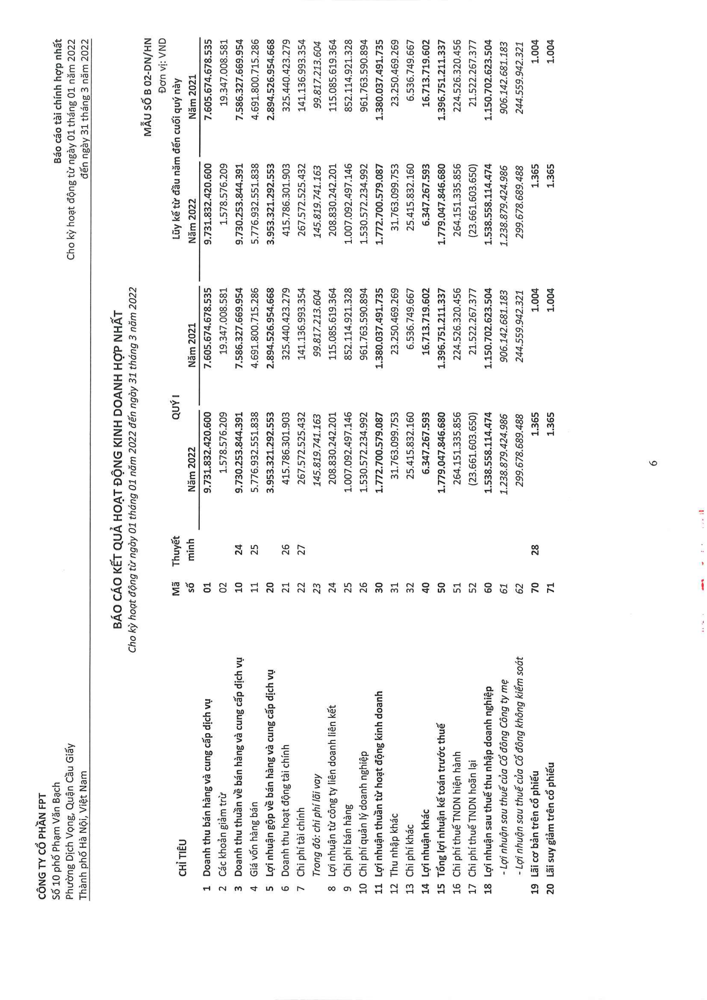

PDF PAGE 9


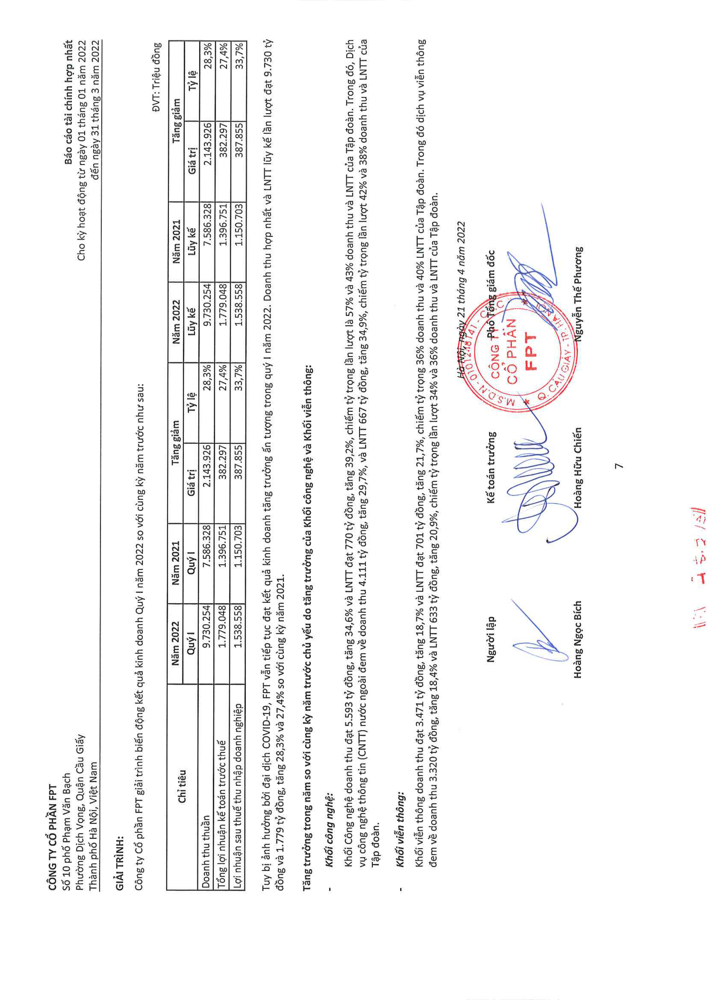

In [85]:

import pymupdf
from PIL import Image
from IPython.display import display

pdf_path = (
    QUARTERLY_DIR /
    "FPT_2022_Q1_Consolidated_FS.pdf"
)

doc = pymupdf.open(pdf_path)

for page_num in [7, 8]:

    page = doc[page_num]

    pix = page.get_pixmap(
        dpi=350,
        colorspace=pymupdf.csRGB
    )

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    print(f"PDF PAGE {page_num + 1}")
    display(image)

doc.close()


In [86]:

import re
import pandas as pd
import pymupdf
import pytesseract
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

# Tesseract executable
pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

# Folder containing the 24 quarterly PDFs
pdf_files = sorted(QUARTERLY_DIR.glob("*.pdf"))

print(f"Found {len(pdf_files)} PDF files")

# Recognition patterns
patterns = {
    "BS": [
        r"B01",
        r"CAN DOI KE TOAN",
        r"TAI SAN",
        r"NGUON VON",
        r"NO PHAI TRA",
        r"VON CHU SO HUU",
    ],
    "IS": [
        r"B02",
        r"KET QUA HOAT DONG KINH DOANH",
        r"DOANH THU BAN HANG",
        r"LOI NHUAN TRUOC THUE",
        r"LOI NHUAN SAU THUE",
    ],
    "CF": [
        r"B03",
        r"LUU CHUYEN TIEN TE",
        r"LUU CHUYEN TIEN",
        r"TIEN THUAN TU HOAT DONG",
        r"LUU CHUYEN TIEN THUAN",
    ],
}

def normalize_ocr(text):
    text = text.upper()
    text = re.sub(r"[^A-Z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

records = []

for pdf_path in tqdm(pdf_files):

    doc = pymupdf.open(pdf_path)

    # Scan the first 20 pages; financial statements are usually near the front.
    pages_to_scan = min(20, len(doc))

    for page_idx in range(pages_to_scan):

        page = doc[page_idx]

        pix = page.get_pixmap(
            dpi=250,
            colorspace=pymupdf.csGRAY
        )

        image = Image.frombytes(
            "L",
            [pix.width, pix.height],
            pix.samples
        )

        ocr_text = pytesseract.image_to_string(
            image,
            lang="eng",
            config="--psm 6"
        )

        text = normalize_ocr(ocr_text)

        scores = {}

        for statement, keywords in patterns.items():
            scores[statement] = sum(
                1 for keyword in keywords
                if keyword in text
            )

        # Keep pages with at least one recognition signal.
        for statement, score in scores.items():

            if score > 0:
                records.append({
                    "source_file": pdf_path.name,
                    "pdf_page": page_idx + 1,
                    "candidate_statement": statement,
                    "keyword_score": score,
                    "ocr_text_preview": text[:500],
                })

    doc.close()

candidates = pd.DataFrame(records)

# Save candidate pages for manual verification.
candidate_path = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "FPT_page_mapping_candidates.csv"
)

candidate_path.parent.mkdir(parents=True, exist_ok=True)
candidates.to_csv(candidate_path, index=False)

print("Candidate pages:", len(candidates))
print("Saved to:", candidate_path)

display(
    candidates.sort_values(
        ["source_file", "pdf_page", "keyword_score"],
        ascending=[True, True, False]
    )
)


d:\DS Project\Vietnam_Equity_Factor_Research\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Found 24 PDF files


100%|██████████| 24/24 [28:07<00:00, 70.29s/it]

Candidate pages: 56
Saved to: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_page_mapping_candidates.csv


,source_file,pdf_page,candidate_statement,keyword_score,ocr_text_preview
0,FPT_2020_Q1_Consolidated_FS.pdf,4,BS,2,CONG TY CO PHAN FPT 6 17 PH DUY TAN BAO CAO TA...
1,FPT_2020_Q1_Consolidated_FS.pdf,5,BS,2,RLL EEE EEE EEE CONG TY CO PHAN FPT 86 17 PH D...
2,FPT_2020_Q1_Consolidated_FS.pdf,6,IS,2,CONG TY CO PHAN FPT 6 17 PH DUY TAN BAO CAO TA...
4,FPT_2020_Q1_Consolidated_FS.pdf,8,CF,2,MMC CNC C CNC CCCNNNMNNRR NNN RRR RRR EE TWLQ ...
3,FPT_2020_Q1_Consolidated_FS.pdf,8,BS,1,MMC CNC C CNC CCCNNNMNNRR NNN RRR RRR EE TWLQ ...
5,FPT_2020_Q1_Consolidated_FS.pdf,10,BS,1,CANN NNN NN NN NN NNN CE SSS CONG TY CO PHAN F...
6,FPT_2020_Q1_Consolidated_FS.pdf,11,BS,1,A EE CONG TY CO PHAN FPT 6 17 PH DUY TAN BAO C...
7,FPT_2020_Q1_Consolidated_FS.pdf,14,BS,1,CONG TY CO PHAN FPT 6 17 PH DUY TAN BAO CAO TA...
8,FPT_2020_Q1_Consolidated_FS.pdf,15,BS,1,AAN N NNN NN NC CONG TY CO PHAN FPT 8617 PH DU...
9,FPT_2020_Q1_Consolidated_FS.pdf,16,IS,1,CAAMMMNCRRRRRCRRRRR RN NN ENE CONG TY CO PHAN ...


In [87]:

# Reload the saved candidate file
candidate_path = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "FPT_page_mapping_candidates.csv"
)

candidates = pd.read_csv(candidate_path)

# All 24 PDFs
pdf_files = sorted(QUARTERLY_DIR.glob("*.pdf"))

all_files = pd.DataFrame({
    "source_file": [p.name for p in pdf_files]
})

# Summarise candidate pages by statement type
summary_rows = []

for filename in all_files["source_file"]:

    file_candidates = candidates[
        candidates["source_file"] == filename
    ]

    row = {"source_file": filename}

    for statement in ["BS", "IS", "CF"]:

        pages = (
            file_candidates.loc[
                file_candidates["candidate_statement"] == statement,
                "pdf_page"
            ]
            .dropna()
            .astype(int)
            .sort_values()
            .unique()
        )

        row[f"{statement}_candidates"] = (
            ", ".join(map(str, pages))
            if len(pages) > 0 else "Not found"
        )

    row["total_candidates"] = len(file_candidates)

    summary_rows.append(row)

mapping_summary = pd.DataFrame(summary_rows)

display(mapping_summary)

# Identify files with no candidate pages
print("\nPDF files without any OCR candidates:")
display(
    mapping_summary.loc[
        mapping_summary["total_candidates"] == 0,
        ["source_file"]
    ]
)

# Save the summary
summary_path = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "FPT_page_mapping_summary.csv"
)

mapping_summary.to_csv(summary_path, index=False)

print("\nSaved:", summary_path)


,source_file,BS_candidates,IS_candidates,CF_candidates,total_candidates
0,FPT_2020_Q1_Consolidated_FS.pdf,"4, 5, 8, 10, 11, 14, 15, 17, 18, 20","6, 16",8,13
1,FPT_2020_Q2_Consolidated_FS.pdf,Not found,Not found,Not found,0
2,FPT_2020_Q3_Consolidated_FS.pdf,Not found,Not found,Not found,0
3,FPT_2020_Q4_Consolidated_FS.pdf,Not found,Not found,Not found,0
4,FPT_2021_Q1_Consolidated_FS.pdf,Not found,Not found,Not found,0
5,FPT_2021_Q2_Consolidated_FS.pdf,Not found,Not found,Not found,0
6,FPT_2021_Q3_Consolidated_FS.pdf,"4, 5, 6, 7, 10, 13, 14, 15, 16, 19","8, 17","10, 11",14
7,FPT_2021_Q4_Consolidated_FS.pdf,"4, 5, 6, 7, 10, 13, 14, 15, 16, 18, 19","8, 17",10,14
8,FPT_2022_Q1_Consolidated_FS.pdf,"4, 5, 6, 7, 10, 13, 14, 15, 16, 17, 18, 19, 20",17,10,15
9,FPT_2022_Q2_Consolidated_FS.pdf,Not found,Not found,Not found,0



PDF files without any OCR candidates:


,source_file
1,FPT_2020_Q2_Consolidated_FS.pdf
2,FPT_2020_Q3_Consolidated_FS.pdf
3,FPT_2020_Q4_Consolidated_FS.pdf
4,FPT_2021_Q1_Consolidated_FS.pdf
5,FPT_2021_Q2_Consolidated_FS.pdf
9,FPT_2022_Q2_Consolidated_FS.pdf
10,FPT_2022_Q3_Consolidated_FS.pdf
11,FPT_2022_Q4_Consolidated_FS.pdf
12,FPT_2023_Q1_Consolidated_FS.pdf
13,FPT_2023_Q2_Consolidated_FS.pdf



Saved: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_page_mapping_summary.csv


In [88]:

import pymupdf
import pandas as pd
from tqdm.auto import tqdm

diagnostics = []

for pdf_path in tqdm(pdf_files):

    doc = pymupdf.open(pdf_path)

    page_text_lengths = []

    for page_num, page in enumerate(doc):

        text = page.get_text("text").strip()

        page_text_lengths.append({
            "page": page_num + 1,
            "text_chars": len(text)
        })

    total_text_chars = sum(
        item["text_chars"] for item in page_text_lengths
    )

    substantial_pages = [
        item["page"]
        for item in page_text_lengths
        if item["text_chars"] >= 300
    ]

    diagnostics.append({
        "source_file": pdf_path.name,
        "total_pages": len(doc),
        "total_text_chars": total_text_chars,
        "pages_with_text": sum(
            item["text_chars"] > 50
            for item in page_text_lengths
        ),
        "substantial_text_pages": len(substantial_pages),
        "substantial_page_numbers": ", ".join(
            map(str, substantial_pages)
        ) if substantial_pages else "None",
        "page_text_lengths": page_text_lengths
    })

    doc.close()

pdf_diagnostics = pd.DataFrame(diagnostics)

display(
    pdf_diagnostics[
        [
            "source_file",
            "total_pages",
            "total_text_chars",
            "pages_with_text",
            "substantial_text_pages",
            "substantial_page_numbers"
        ]
    ]
)

# Export diagnostic results
diagnostic_path = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "FPT_pdf_text_diagnostics.csv"
)

pdf_diagnostics.drop(
    columns=["page_text_lengths"]
).to_csv(diagnostic_path, index=False)

print("\nSaved:", diagnostic_path)


100%|██████████| 24/24 [00:02<00:00,  8.54it/s]


,source_file,total_pages,total_text_chars,pages_with_text,substantial_text_pages,substantial_page_numbers
0,FPT_2020_Q1_Consolidated_FS.pdf,39,0,0,0,None
1,FPT_2020_Q2_Consolidated_FS.pdf,35,0,0,0,None
2,FPT_2020_Q3_Consolidated_FS.pdf,35,0,0,0,None
3,FPT_2020_Q4_Consolidated_FS.pdf,38,0,0,0,None
4,FPT_2021_Q1_Consolidated_FS.pdf,40,2470,2,2,"1, 2"
5,FPT_2021_Q2_Consolidated_FS.pdf,38,105035,38,37,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15..."
6,FPT_2021_Q3_Consolidated_FS.pdf,41,99,1,0,None
7,FPT_2021_Q4_Consolidated_FS.pdf,41,98,1,0,None
8,FPT_2022_Q1_Consolidated_FS.pdf,40,96,1,0,None
9,FPT_2022_Q2_Consolidated_FS.pdf,40,98,1,0,None



Saved: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_pdf_text_diagnostics.csv


In [89]:

import pymupdf
import pandas as pd

orientation_rows = []

for pdf_path in pdf_files:

    doc = pymupdf.open(pdf_path)

    for page_num in range(min(15, len(doc))):

        page = doc[page_num]
        rect = page.rect

        orientation_rows.append({
            "source_file": pdf_path.name,
            "pdf_page": page_num + 1,
            "rotation": page.rotation,
            "width": round(rect.width, 1),
            "height": round(rect.height, 1),
            "orientation": (
                "Landscape"
                if rect.width > rect.height
                else "Portrait"
            )
        })

    doc.close()

orientation_df = pd.DataFrame(orientation_rows)

display(
    orientation_df.groupby(
        ["source_file", "rotation", "orientation"]
    ).size().reset_index(name="page_count")
)

# Save detailed results
orientation_path = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "FPT_pdf_orientation_diagnostics.csv"
)

orientation_df.to_csv(orientation_path, index=False)

print("Saved:", orientation_path)


,source_file,rotation,orientation,page_count
0,FPT_2020_Q1_Consolidated_FS.pdf,0,Landscape,1
1,FPT_2020_Q1_Consolidated_FS.pdf,0,Portrait,14
2,FPT_2020_Q2_Consolidated_FS.pdf,0,Landscape,2
3,FPT_2020_Q2_Consolidated_FS.pdf,0,Portrait,13
4,FPT_2020_Q3_Consolidated_FS.pdf,0,Landscape,2
5,FPT_2020_Q3_Consolidated_FS.pdf,0,Portrait,13
6,FPT_2020_Q4_Consolidated_FS.pdf,0,Landscape,2
7,FPT_2020_Q4_Consolidated_FS.pdf,0,Portrait,13
8,FPT_2021_Q1_Consolidated_FS.pdf,0,Landscape,2
9,FPT_2021_Q1_Consolidated_FS.pdf,0,Portrait,13


Saved: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_pdf_orientation_diagnostics.csv


In [90]:

import pytesseract

available_languages = pytesseract.get_languages(config="")

print("Available OCR languages:")
print(available_languages)

print("\nVietnamese OCR available:", "vie" in available_languages)


Available OCR languages:
['eng', 'osd']

Vietnamese OCR available: False


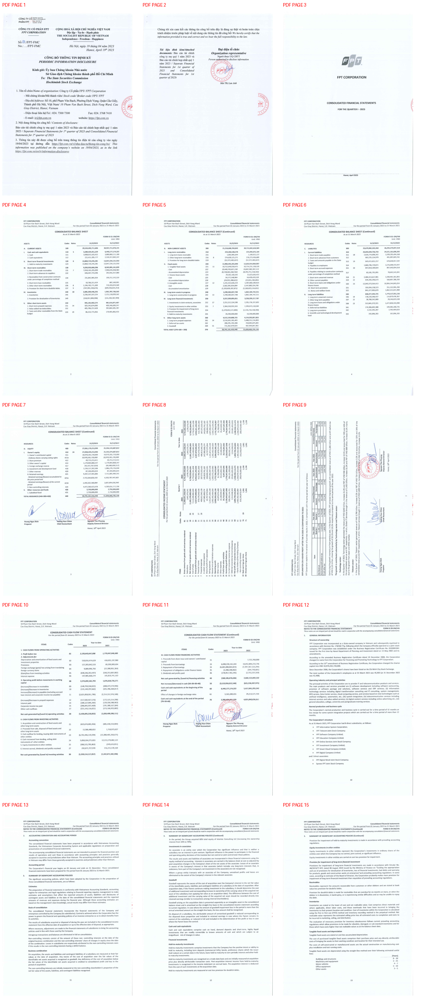

Saved: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_2023_Q1_contact_sheet.png


In [91]:

import pymupdf
from PIL import Image, ImageDraw
from pathlib import Path
import math

pdf_path = QUARTERLY_DIR / "FPT_2023_Q1_Consolidated_FS.pdf"

doc = pymupdf.open(pdf_path)

thumbnails = []

for page_num in range(min(15, len(doc))):

    page = doc[page_num]

    # PyMuPDF applies the page's rotation when rendering.
    pix = page.get_pixmap(
        dpi=80,
        colorspace=pymupdf.csRGB,
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    image.thumbnail((300, 420))

    thumbnails.append((page_num + 1, image.copy()))

doc.close()

# Contact sheet layout
columns = 3
rows = math.ceil(len(thumbnails) / columns)

cell_width = 320
cell_height = 455

sheet = Image.new(
    "RGB",
    (columns * cell_width, rows * cell_height),
    "white"
)

draw = ImageDraw.Draw(sheet)

for i, (page_number, image) in enumerate(thumbnails):

    x = (i % columns) * cell_width
    y = (i // columns) * cell_height

    draw.text(
        (x + 5, y + 5),
        f"PDF PAGE {page_number}",
        fill="red"
    )

    sheet.paste(image, (x + 5, y + 25))

display(sheet)

contact_path = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "FPT_2023_Q1_contact_sheet.png"
)

sheet.save(contact_path)

print("Saved:", contact_path)


In [93]:

import pymupdf
import pytesseract
from PIL import Image
from pathlib import Path

pdf_path = QUARTERLY_DIR / "FPT_2023_Q1_Consolidated_FS.pdf"

doc = pymupdf.open(pdf_path)

ocr_results = []

for page_num in range(3, 11):  # PDF pages 4–11

    page = doc[page_num]

    pix = page.get_pixmap(
        dpi=300,
        colorspace=pymupdf.csGRAY,
        alpha=False
    )

    image = Image.frombytes(
        "L",
        [pix.width, pix.height],
        pix.samples
    )

    text = pytesseract.image_to_string(
        image,
        lang="vie+eng",
        config="--psm 6"
    )

    ocr_results.append({
        "pdf_page": page_num + 1,
        "rotation": page.rotation,
        "ocr_text": text
    })

doc.close()

# Save OCR output
ocr_output_dir = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "OCR_test_2023_Q1"
)

ocr_output_dir.mkdir(parents=True, exist_ok=True)

for result in ocr_results:

    output_file = (
        ocr_output_dir /
        f"page_{result['pdf_page']:02d}.txt"
    )

    output_file.write_text(
        result["ocr_text"],
        encoding="utf-8"
    )

    print("\n" + "=" * 80)
    print(f"PDF PAGE {result['pdf_page']}")
    print(f"Rotation: {result['rotation']}")
    print("=" * 80)

    print(result["ocr_text"][:2500])

print("\nOCR completed.")
print("Output folder:", ocr_output_dir)



PDF PAGE 4
Rotation: 270
FPT CORPORATION
10 Pham Van Bach Street, Dich Vong Ward Consolidated financial statements
Cau Giay District, Hanoi, S.R. Vietnam ___ For the period from 01 January 2023 to 31 March 2023
CONSOLIDATED BALANCE SHEET
As at 31 March 2023
FORM B 01-DN/HN
Unit: VND
ASSETS Codes Notes 31/3/2023 31/12/2022
A. CURRENT ASSETS 100 29,524,492,711,606 30,937,711,076,141
I. Cash and cash equivalents 110 5 3,289,424,451,229 6,440,177,174,322
1. Cash 111 3,068,013,165,452 3,880,860,111,180
2. Cash equivalents 112 221,411,285,777 2,559,317,063,142
ll. Short-term financial investments 120 6 13,860,719,245,281 13,047,234,131,950
1. Held-to-maturity investments 123 13,860,719,245,281 13,047,234,131,950
lll. Short-term receivables 130 9,293,933,666,296 8,502,895,161,839
1. Short-term trade receivables 131 rf 7,918,165,205,099 7,990,076,948,983
2. Short-term advances to suppliers 132 646,447,723,206 292,916,357,080
3. Receivables f i
eceivables from construction contracts 134 231,84


PDF PAGE 8


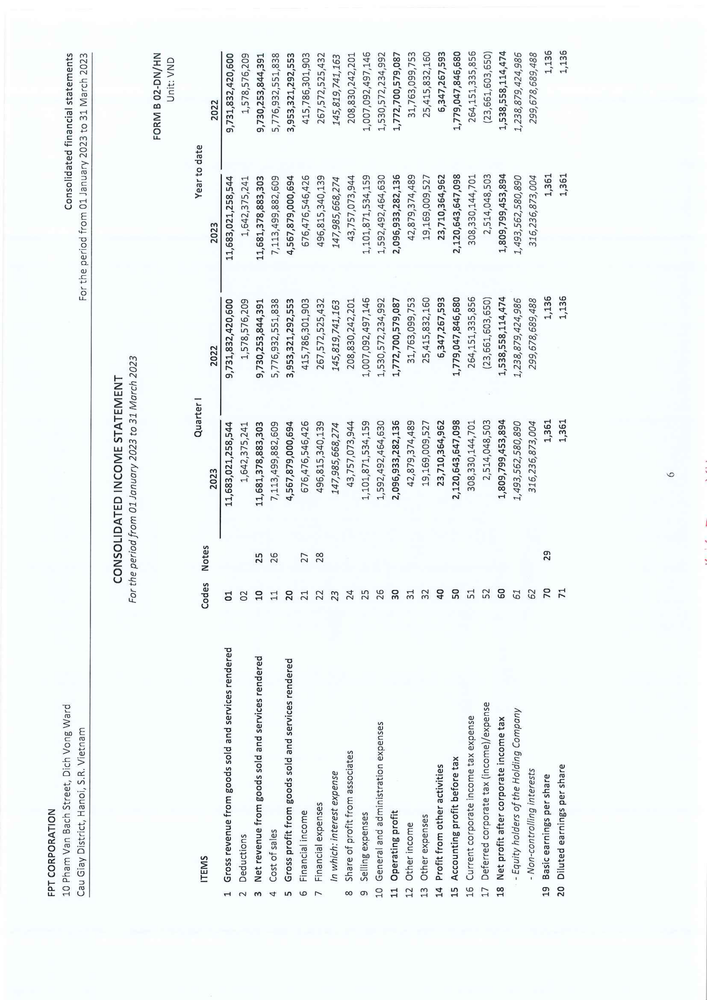


--- PSM 4 ---
N
loại

N

t+
lợi

wn
Loài

wo
N

oO
Luai

AN
nom

S5
T+

5
wy

AN
m Ww

=]
w

x
si

N
‹

Le]
=

x4
r


--- PSM 11 ---
m cm œ

c F

58

mo

vi vi

oa wt

—_

mi

.

nh

dx

mm .

nN

Fan

AN

9

N

+

wn

wo

oO

AN

o

5

AN

oO

Dal

N

oOo

x4

N

N

N

Loài

N

Luại

cm mm

t+

wy

mW

wo

So)

‹

™

m=

—_

—

—

—

—_

=

—

—

—

—

.=

=

..

—_

4

—

—

—

—

—

m wo


--- PSM 12 ---
FPT CORPORATION

10 Pham Van Bach Street, Dich Vong Ward

Consolidated financial statements

Cau Giay District, Hanoi, S.R. Vietnam

For the period from 01 January 2023 to 31 March 2023

CONSOLIDATED INCOMIE STATEMENT

For the period from 01 January 2023 to 31 March 2023

FORM B 02-DN/HN

Unit: VND

Quarter |

Year to date

ITEMS

Codes

Notes

2023

2022

2023

2022

Gross revenue from goods sold and services rendered

01

11,683,021,258,544

9,731,832,420,600

11,683,021,258,544

9,731,832,420,600

Deductions

02

1,642,375,241

1,578,576,209

1,642,375,241

1,578,576,209

Net re

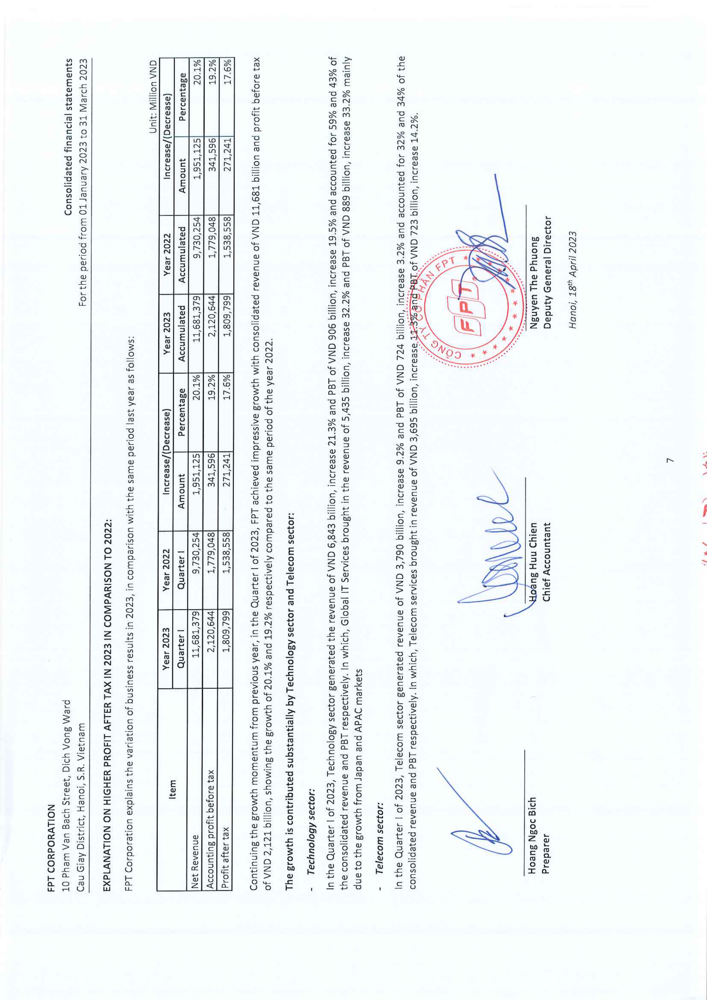


--- PSM 4 ---


--- PSM 11 ---
xs

x

>

>

yz

x

>

x

—

cS

On

> <

—

mg: 2

—

—

=

o 2

x

ƠI

C R

„++==*

—

x

mM .-

Sat

A

S

CO

.=

ch

es

>

Ơi

J

Sle

—e

r

n

cf

4

L

|

Vo

Oo

i=

han ...

=

>

>

>

—

ao oo

.=

>

—

cw

—

sa

OS

n>

Sa

—

—

..

..

—

=4

2 £

—

Rear |

—

.<

uw oO

on

wo €

x

2 o

—

.=

—

ToT xo

—

>

—

cc Cc

=

os

Q

—

WY k-

fo

~ ƠØ

mc

..

—

..

NS

ưu Cc

—

ow

—

1 mo}

Ơn

.=

`


--- PSM 12 ---
FPT CORPORATION

10 Pham Van Bach Street, Dịch Vong Ward

Consolidated financial statements

Cau Giay District, Hanoi, S.R. Vietnam

For the period from 01 January 2023 to 31 March 2023

EXPLANATION ON HIGHER PROFIT AFTER TAX IN 2023 IN COMPARISON TO 2022:

FPT Corporation explains the variation of business results in 2023, in comparison with the same period last year as follows:

Unit: Million VND

| Year 2023, | Year 2022 |

Increase/(Decrease)

| Year2023 | Year 2022 |

Increase/(Decrease)

—

| Quarter! | Quarter! |

In [94]:

import pymupdf
import pytesseract
from PIL import Image
from IPython.display import display

pdf_path = QUARTERLY_DIR / "FPT_2023_Q1_Consolidated_FS.pdf"

doc = pymupdf.open(pdf_path)

for page_num in [7, 8]:  # PDF pages 8 and 9

    page = doc[page_num]

    pix = page.get_pixmap(
        dpi=350,
        colorspace=pymupdf.csRGB,
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    print(f"\n{'='*70}")
    print(f"PDF PAGE {page_num + 1}")
    print(f"{'='*70}")

    display(image)

    for psm in [4, 11, 12]:

        config = f"--psm {psm}"

        text = pytesseract.image_to_string(
            image,
            lang="vie+eng",
            config=config
        )

        print(f"\n--- PSM {psm} ---")
        print(text[:3500])

doc.close()


In [95]:

# FPT Q1 2023 Income Statement - OCR validation

is_data = {
    "gross_revenue": 11683021258544,
    "deductions": 1642375241,
    "net_revenue": 11681378883303,
    "cost_of_sales": 7113499882609,
    "gross_profit": 4567879000694,
    "financial_income": 676476546426,
    "financial_expenses": 496815340139,
    "interest_expense": 147985668274,
    "share_profit_associates": 43757073944,
    "selling_expenses": 1101871534159,
    "admin_expenses": 1592492464630,
    "operating_profit": 2096933282136,
    "other_income": 42879374489,
    "other_expenses": 19169009527,
    "other_profit": 23710364962,
    "profit_before_tax": 2120643647098,
    "current_tax": 308330144701,
    "deferred_tax": 2514048503,
    "net_income": 1809799453894,
    "profit_attributable_owners": 1493562580890,
    "non_controlling_interests": 316236873004,
}

checks = {
    "Revenue reconciliation":
        is_data["gross_revenue"] - is_data["deductions"]
        == is_data["net_revenue"],

    "Gross profit reconciliation":
        is_data["net_revenue"] - is_data["cost_of_sales"]
        == is_data["gross_profit"],

    "Operating profit reconciliation":
        is_data["gross_profit"]
        + is_data["financial_income"]
        - is_data["financial_expenses"]
        + is_data["share_profit_associates"]
        - is_data["selling_expenses"]
        - is_data["admin_expenses"]
        == is_data["operating_profit"],

    "Other profit reconciliation":
        is_data["other_income"] - is_data["other_expenses"]
        == is_data["other_profit"],

    "Profit before tax reconciliation":
        is_data["operating_profit"] + is_data["other_profit"]
        == is_data["profit_before_tax"],

    "Net income reconciliation":
        is_data["profit_before_tax"]
        - is_data["current_tax"]
        - is_data["deferred_tax"]
        == is_data["net_income"],

    "Profit attribution reconciliation":
        is_data["profit_attributable_owners"]
        + is_data["non_controlling_interests"]
        == is_data["net_income"],
}

validation_df = pd.DataFrame([
    {"check": name, "passed": result}
    for name, result in checks.items()
])

display(validation_df)

print(
    f"\nPassed: {sum(checks.values())}/{len(checks)} checks"
)


,check,passed
0,Revenue reconciliation,True
1,Gross profit reconciliation,True
2,Operating profit reconciliation,True
3,Other profit reconciliation,True
4,Profit before tax reconciliation,True
5,Net income reconciliation,True
6,Profit attribution reconciliation,True



Passed: 7/7 checks


In [96]:

import pandas as pd
from pathlib import Path

# Reference values for FPT Q1 2023
# Values are in VND, except EPS (VND/share).

income_ground_truth = [
    ("gross_revenue", 11683021258544, "VND"),
    ("deductions", 1642375241, "VND"),
    ("net_revenue", 11681378883303, "VND"),
    ("cost_of_sales", 7113499882609, "VND"),
    ("gross_profit", 4567879000694, "VND"),
    ("financial_income", 676476546426, "VND"),
    ("financial_expenses", 496815340139, "VND"),
    ("interest_expense", 147985668274, "VND"),
    ("share_profit_associates", 43757073944, "VND"),
    ("selling_expenses", 1101871534159, "VND"),
    ("admin_expenses", 1592492464630, "VND"),
    ("operating_profit", 2096933282136, "VND"),
    ("other_income", 42879374489, "VND"),
    ("other_expenses", 19169009527, "VND"),
    ("other_profit", 23710364962, "VND"),
    ("profit_before_tax", 2120643647098, "VND"),
    ("current_tax", 308330144701, "VND"),
    ("deferred_tax", 2514048503, "VND"),
    ("net_income", 1809799453894, "VND"),
    ("profit_attributable_owners", 1493562580890, "VND"),
    ("non_controlling_interests", 316236873004, "VND"),
    ("basic_eps", 1361, "VND/share"),
    ("diluted_eps", 1361, "VND/share"),
]

ground_truth_df = pd.DataFrame(
    income_ground_truth,
    columns=["metric", "value", "unit"]
)

ground_truth_df.insert(0, "ticker", "FPT")
ground_truth_df.insert(1, "fiscal_period", "2023Q1")
ground_truth_df["statement_type"] = "Income Statement"
ground_truth_df["source_file"] = (
    "FPT_2023_Q1_Consolidated_FS.pdf"
)
ground_truth_df["source_page"] = 8
ground_truth_df["verification_status"] = "Provisional"

# Export
ground_truth_path = (
    PROCESSED_DIR /
    "fundamentals" /
    "FPT" /
    "FPT_IS_ground_truth_Q1_2023.csv"
)

ground_truth_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

ground_truth_df.to_csv(
    ground_truth_path,
    index=False
)

display(ground_truth_df)

print("\nGround Truth saved:", ground_truth_path)


,ticker,fiscal_period,metric,value,unit,statement_type,source_file,source_page,verification_status
0,FPT,2023Q1,gross_revenue,11683021258544,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
1,FPT,2023Q1,deductions,1642375241,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
2,FPT,2023Q1,net_revenue,11681378883303,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
3,FPT,2023Q1,cost_of_sales,7113499882609,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
4,FPT,2023Q1,gross_profit,4567879000694,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
5,FPT,2023Q1,financial_income,676476546426,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
6,FPT,2023Q1,financial_expenses,496815340139,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
7,FPT,2023Q1,interest_expense,147985668274,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
8,FPT,2023Q1,share_profit_associates,43757073944,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional
9,FPT,2023Q1,selling_expenses,1101871534159,VND,Income Statement,FPT_2023_Q1_Consolidated_FS.pdf,8,Provisional



Ground Truth saved: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_IS_ground_truth_Q1_2023.csv


PDF page: 8
Page rotation: 270
Page dimensions: Rect(0.0, 0.0, 595.4400024414062, 842.0399780273438)
Rendered image dimensions: (2895, 4094)
Saved to: d:\DS Project\Vietnam_Equity_Factor_Research\results\figures\ocr_diagnostics\FPT_2023_Q1_IS_page8_350dpi.png


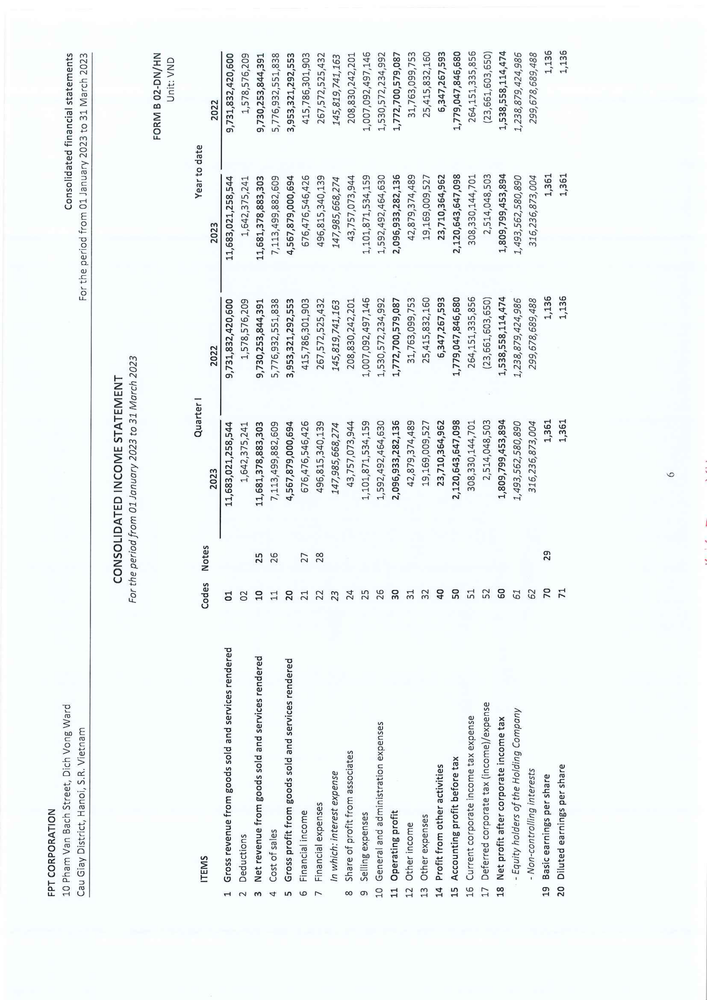

In [97]:
from pathlib import Path
import pymupdf
from PIL import Image
from IPython.display import display

# Define paths
PROJECT_ROOT = Path.cwd().parent

PDF_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "fundamentals"
    / "FPT"
    / "quarterly"
    / "FPT_2023_Q1_Consolidated_FS.pdf"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
    / "ocr_diagnostics"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Open PDF
doc = pymupdf.open(PDF_PATH)

# Page 8 = index 7 (Python uses zero-based indexing)
page = doc[7]

# Render at 350 DPI
dpi = 350
zoom = dpi / 72

pix = page.get_pixmap(
    matrix=pymupdf.Matrix(zoom, zoom),
    alpha=False
)

# Convert to PIL image
page_image = Image.frombytes(
    "RGB",
    [pix.width, pix.height],
    pix.samples
)

# Save rendered image
image_path = FIGURE_DIR / "FPT_2023_Q1_IS_page8_350dpi.png"
page_image.save(image_path)

print("PDF page:", 8)
print("Page rotation:", page.rotation)
print("Page dimensions:", page.rect)
print("Rendered image dimensions:", page_image.size)
print("Saved to:", image_path)

display(page_image)

In [98]:
from pathlib import Path
import pymupdf
import pytesseract

from PIL import Image
from pytesseract import Output

# Tesseract executable
pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

# Paths
PROJECT_ROOT = Path.cwd().parent

PDF_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "fundamentals"
    / "FPT"
    / "quarterly"
    / "FPT_2023_Q1_Consolidated_FS.pdf"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "fundamentals"
    / "FPT"
    / "normalized_pages"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Open PDF
doc = pymupdf.open(PDF_PATH)

dpi = 300
zoom = dpi / 72

rotation_log = []

for page_index, page in enumerate(doc):

    # Render page (PyMuPDF already applies PDF rotation metadata)
    pix = page.get_pixmap(
        matrix=pymupdf.Matrix(zoom, zoom),
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    # Detect text orientation
    try:
        osd = pytesseract.image_to_osd(
            image,
            output_type=Output.DICT
        )

        detected_rotation = osd["rotate"]
        confidence = osd["orientation_conf"]

    except pytesseract.TesseractError:
        detected_rotation = 0
        confidence = 0

    # Rotate only when OSD has sufficient confidence
    if detected_rotation != 0 and confidence >= 5:

        # PIL rotates counterclockwise;
        # Tesseract reports clockwise correction
        image = image.rotate(
            -detected_rotation,
            expand=True
        )

        action = f"Rotated {detected_rotation} degrees"

    else:
        action = "No rotation"

    # Save normalized page
    output_path = (
        OUTPUT_DIR
        / f"FPT_2023_Q1_page_{page_index + 1:02d}.png"
    )

    image.save(output_path)

    rotation_log.append({
        "page": page_index + 1,
        "original_pdf_rotation": page.rotation,
        "detected_rotation": detected_rotation,
        "orientation_confidence": confidence,
        "action": action,
        "image_width": image.width,
        "image_height": image.height,
        "output_path": str(output_path)
    })

doc.close()

import pandas as pd

rotation_df = pd.DataFrame(rotation_log)

display(rotation_df)

print("Total pages:", len(rotation_df))
print("Normalized images saved:", len(rotation_df))
print("Output directory:", OUTPUT_DIR)

,page,original_pdf_rotation,detected_rotation,orientation_confidence,action,image_width,image_height,output_path
0,1,270,0,16.07,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...
1,2,270,0,12.82,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...
2,3,270,0,2.15,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...
3,4,270,0,10.84,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...
4,5,270,0,9.63,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...
5,6,270,0,10.24,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...
6,7,270,0,11.75,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...
7,8,270,90,8.25,Rotated 90 degrees,3509,2481,d:\DS Project\Vietnam_Equity_Factor_Research\d...
8,9,270,90,12.98,Rotated 90 degrees,3509,2481,d:\DS Project\Vietnam_Equity_Factor_Research\d...
9,10,270,0,10.90,No rotation,2481,3509,d:\DS Project\Vietnam_Equity_Factor_Research\d...


Total pages: 44
Normalized images saved: 44
Output directory: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\normalized_pages


In [99]:
rotation_df["layout"] = rotation_df.apply(
    lambda row: (
        "Landscape"
        if row["image_width"] > row["image_height"]
        else "Portrait"
    ),
    axis=1
)

print("Layout distribution:")
display(
    rotation_df["layout"]
    .value_counts()
    .rename_axis("layout")
    .to_frame("number_of_pages")
)

print("\nPages requiring additional rotation:")
display(
    rotation_df.loc[
        rotation_df["detected_rotation"] != 0,
        [
            "page",
            "original_pdf_rotation",
            "detected_rotation",
            "orientation_confidence",
            "layout"
        ]
    ]
)

Layout distribution:


,number_of_pages
layout,
Portrait,29
Landscape,15



Pages requiring additional rotation:


,page,original_pdf_rotation,detected_rotation,orientation_confidence,layout
7,8,270,90,8.25,Landscape
8,9,270,90,12.98,Landscape
20,21,270,90,11.17,Landscape
21,22,270,90,8.94,Landscape
23,24,270,90,7.05,Landscape
25,26,270,90,6.93,Landscape
26,27,270,90,8.36,Landscape
30,31,270,90,5.76,Landscape
32,33,270,90,7.67,Landscape
33,34,270,90,8.97,Landscape


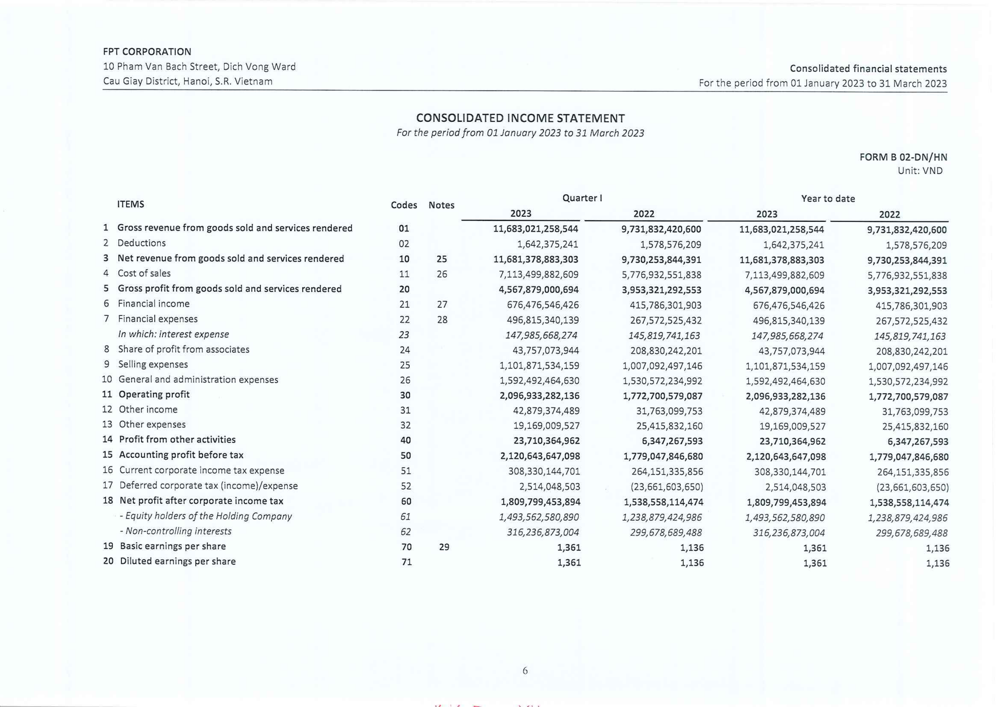

In [100]:
from IPython.display import display
from PIL import Image

normalized_page_8 = (
    OUTPUT_DIR / "FPT_2023_Q1_page_08.png"
)

display(Image.open(normalized_page_8))

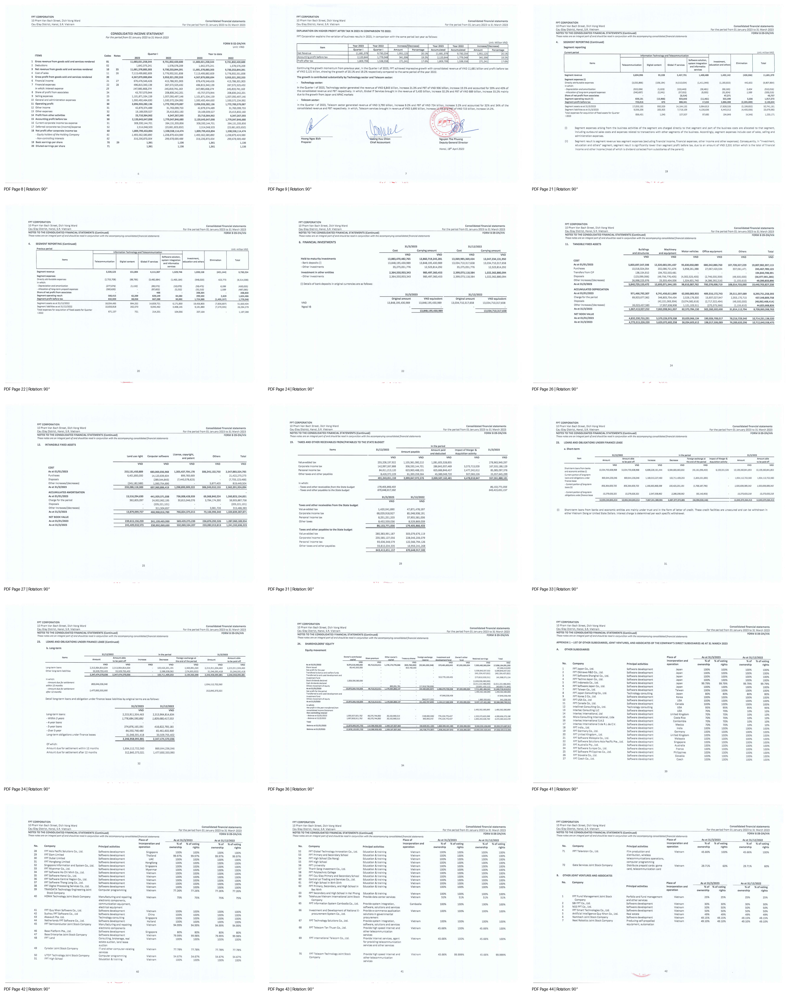

Landscape pages: 15
Contact sheet saved: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\normalized_pages\FPT_2023_Q1_landscape_contact_sheet.png


In [101]:
from PIL import Image, ImageDraw
from pathlib import Path
import math

# Select landscape pages
landscape_pages = rotation_df.loc[
    rotation_df["layout"] == "Landscape"
].copy()

# Contact sheet settings
cols = 3
thumb_width = 700
thumb_height = 495
label_height = 35
rows = math.ceil(len(landscape_pages) / cols)

sheet = Image.new(
    "RGB",
    (
        cols * thumb_width,
        rows * (thumb_height + label_height)
    ),
    "white"
)

draw = ImageDraw.Draw(sheet)

for i, (_, row) in enumerate(landscape_pages.iterrows()):

    image = Image.open(row["output_path"]).convert("RGB")
    image.thumbnail((thumb_width - 20, thumb_height - 20))

    x = (i % cols) * thumb_width
    y = (i // cols) * (thumb_height + label_height)

    # Center thumbnail
    paste_x = x + (thumb_width - image.width) // 2
    paste_y = y + (thumb_height - image.height) // 2

    sheet.paste(image, (paste_x, paste_y))

    draw.text(
        (x + 10, y + thumb_height),
        f"PDF Page {row['page']} | Rotation: {row['detected_rotation']}°",
        fill="black"
    )

display(sheet)

# Save contact sheet
contact_path = OUTPUT_DIR / "FPT_2023_Q1_landscape_contact_sheet.png"
sheet.save(contact_path)

print("Landscape pages:", len(landscape_pages))
print("Contact sheet saved:", contact_path)

In [102]:
import pandas as pd
import pytesseract

from PIL import Image, ImageDraw
from pytesseract import Output
from IPython.display import display

# Load normalized page 8
IMAGE_PATH = OUTPUT_DIR / "FPT_2023_Q1_page_08.png"

image = Image.open(IMAGE_PATH).convert("RGB")

# OCR with bounding boxes
ocr_data = pytesseract.image_to_data(
    image,
    lang="vie+eng",
    config="--oem 3 --psm 12",
    output_type=Output.DATAFRAME
)

# Remove empty OCR results
ocr_data = ocr_data.dropna(subset=["text"]).copy()

ocr_data["text"] = ocr_data["text"].astype(str).str.strip()

ocr_data = ocr_data.loc[
    (ocr_data["text"] != "") &
    (ocr_data["conf"] >= 0)
].copy()

# Keep relevant columns
ocr_tokens = ocr_data[
    [
        "text",
        "conf",
        "left",
        "top",
        "width",
        "height",
        "block_num",
        "par_num",
        "line_num",
        "word_num"
    ]
].copy()

# Sort tokens by position
ocr_tokens = ocr_tokens.sort_values(
    ["top", "left"]
).reset_index(drop=True)

print("Image dimensions:", image.size)
print("OCR tokens detected:", len(ocr_tokens))

display(ocr_tokens.head(100))

Image dimensions: (3509, 2481)
OCR tokens detected: 293


,text,conf,left,top,width,height,block_num,par_num,line_num,word_num
0,FPT,93.305710,364,168,55,25,1,1,1,1
1,CORPORATION,91.809807,431,168,238,26,1,1,1,2
2,Pham,96.344246,414,218,84,27,2,1,1,2
3,Dich,96.377701,786,218,63,28,2,1,1,6
4,10,96.658943,365,219,34,26,2,1,1,1
...,...,...,...,...,...,...,...,...,...,...
95,of,96.514008,489,945,30,26,38,1,1,2
96,sales,96.705795,528,945,70,26,38,1,1,3
97,Cost,96.935440,415,946,63,25,38,1,1,1
98,3,47.062256,1404,949,32,24,39,1,1,1


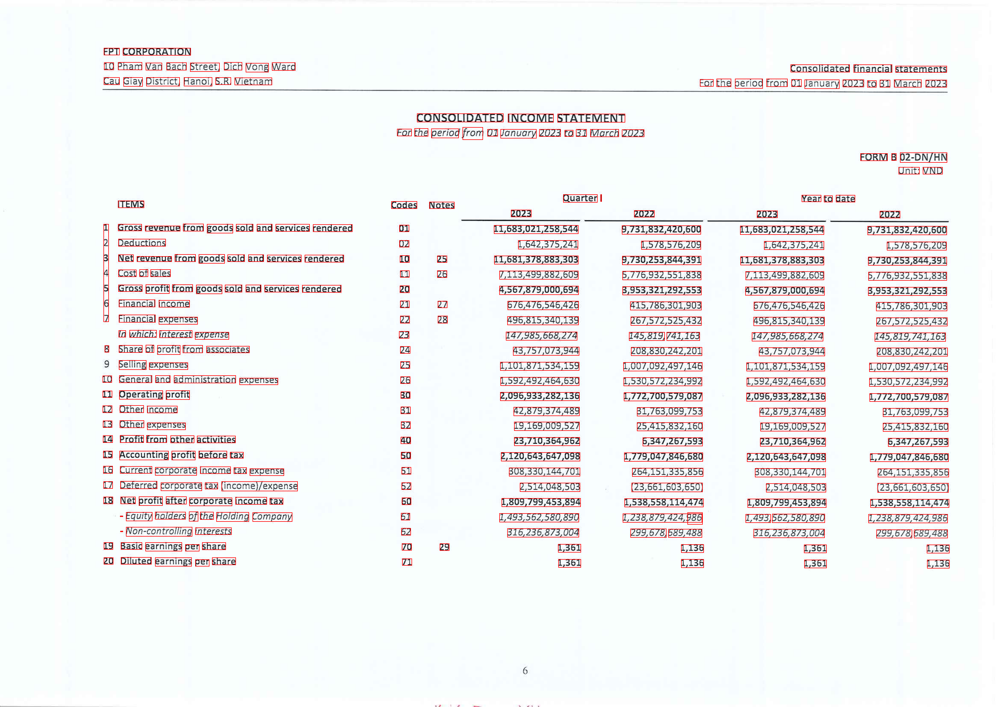

In [103]:
image_with_boxes = image.copy()
draw = ImageDraw.Draw(image_with_boxes)

for _, row in ocr_tokens.iterrows():

    x1 = int(row["left"])
    y1 = int(row["top"])
    x2 = x1 + int(row["width"])
    y2 = y1 + int(row["height"])

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=2
    )

display(image_with_boxes)

In [104]:
import re
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# Copy OCR tokens
numeric_tokens = ocr_tokens.copy()

# Identify numeric tokens
numeric_pattern = r"^\(?-?\d[\d,]*(?:\.\d+)?\)?$"

numeric_tokens = numeric_tokens.loc[
    numeric_tokens["text"].str.fullmatch(
        numeric_pattern,
        na=False
    )
].copy()

# Calculate right edge and vertical center
numeric_tokens["right"] = (
    numeric_tokens["left"] + numeric_tokens["width"]
)

numeric_tokens["y_center"] = (
    numeric_tokens["top"] + numeric_tokens["height"] / 2
)

# Exclude codes and notes on the left side
# Keep the four financial value columns
financial_tokens = numeric_tokens.loc[
    numeric_tokens["right"] > 1600
].copy()

# Cluster right-edge coordinates into four columns
X = financial_tokens[["right"]].values

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

financial_tokens["column_cluster"] = kmeans.fit_predict(X)

# Sort clusters from left to right
cluster_centers = sorted(
    kmeans.cluster_centers_.flatten()
)

cluster_mapping = {
    old_label: new_label
    for new_label, center in enumerate(cluster_centers)
    for old_label, old_center in enumerate(
        kmeans.cluster_centers_.flatten()
    )
    if np.isclose(center, old_center)
}

financial_tokens["column"] = (
    financial_tokens["column_cluster"].map(cluster_mapping)
)

# Display estimated column positions
column_summary = (
    financial_tokens.groupby("column")
    .agg(
        estimated_right=("right", "median"),
        min_right=("right", "min"),
        max_right=("right", "max"),
        token_count=("text", "count")
    )
    .round(1)
)

print("Estimated financial column positions:")
display(column_summary)

# Display extracted tokens
financial_tokens = financial_tokens.sort_values(
    ["y_center", "column"]
)

display(
    financial_tokens[
        ["text", "left", "right", "y_center", "column"]
    ].head(100)
)

Estimated financial column positions:


,estimated_right,min_right,max_right,token_count
column,,,,
0,2032.0,1746,2058,27
1,2463.0,2260,2469,28
2,2894.0,2704,3031,27
3,3325.0,3123,3331,26


,text,left,right,y_center,column
23,01,2777,2812,291.0,2
25,2023,2957,3031,292.0,2
27,31,3087,3123,293.0,3
28,2023,3248,3322,293.0,3
37,01,1710,1746,465.5,0
...,...,...,...,...,...
266,"299,678,",2212,2338,1870.5,1
267,"689,488",2345,2463,1871.0,1
268,"316,236,873,004",2644,2893,1871.5,2
269,"299,678,",3075,3200,1873.0,3


In [105]:
import numpy as np
import pandas as pd
import re
from sklearn.cluster import KMeans

# --------------------------------------------------
# 1. Select numeric tokens in the financial data area
# --------------------------------------------------

data_tokens = ocr_tokens.copy()

numeric_pattern = r"^\(?-?\d[\d,]*(?:\.\d+)?\)?$"

data_tokens = data_tokens.loc[
    data_tokens["text"].str.fullmatch(
        numeric_pattern,
        na=False
    )
].copy()

data_tokens["right"] = (
    data_tokens["left"] + data_tokens["width"]
)

data_tokens["y_center"] = (
    data_tokens["top"] + data_tokens["height"] / 2
)

# Exclude headers, codes and notes
data_tokens = data_tokens.loc[
    (data_tokens["y_center"] >= 400) &
    (data_tokens["y_center"] <= 2000) &
    (data_tokens["right"] > 1600)
].copy()

# --------------------------------------------------
# 2. Estimate four financial column anchors
# --------------------------------------------------

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

data_tokens["cluster"] = kmeans.fit_predict(
    data_tokens[["right"]]
)

# Sort cluster centers from left to right
centers = np.sort(
    kmeans.cluster_centers_.flatten()
)

print("Estimated column anchors:")
for i, center in enumerate(centers):
    print(f"Column {i}: {center:.1f}")

# Assign each token to nearest anchor
data_tokens["column"] = data_tokens["right"].apply(
    lambda x: int(np.argmin(np.abs(centers - x)))
)

# --------------------------------------------------
# 3. Group tokens into horizontal rows
# --------------------------------------------------

data_tokens = data_tokens.sort_values(
    "y_center"
).copy()

row_ids = []
current_row = 0
previous_y = None

ROW_TOLERANCE = 15

for y in data_tokens["y_center"]:

    if (
        previous_y is None or
        abs(y - previous_y) > ROW_TOLERANCE
    ):
        current_row += 1

    row_ids.append(current_row)
    previous_y = y

data_tokens["row_id"] = row_ids

# --------------------------------------------------
# 4. Reconstruct values within each row and column
# --------------------------------------------------

reconstructed = []

for (row_id, column), group in data_tokens.groupby(
    ["row_id", "column"]
):

    group = group.sort_values("left")

    fragments = group["text"].tolist()

    reconstructed_value = "".join(fragments)

    reconstructed.append({
        "row_id": row_id,
        "column": column,
        "y_center": group["y_center"].median(),
        "fragments": fragments,
        "reconstructed_value": reconstructed_value,
        "token_count": len(fragments)
    })

reconstructed_df = pd.DataFrame(reconstructed)

# --------------------------------------------------
# 5. Display reconstructed table
# --------------------------------------------------

reconstructed_wide = reconstructed_df.pivot(
    index="row_id",
    columns="column",
    values="reconstructed_value"
)

reconstructed_wide.columns = [
    f"column_{c}" for c in reconstructed_wide.columns
]

display(reconstructed_wide)

print("Reconstructed rows:", len(reconstructed_wide))

Estimated column anchors:
Column 0: 2013.9
Column 1: 2440.9
Column 2: 2880.4
Column 3: 3313.3


,column_0,column_1,column_2,column_3
row_id,,,,
1,01202331,2023,NaN,NaN
2,2023,2022,2023,2022
3,"11,683,021,258,544","9,731,832,420,600","11,683,021,258,544","9,731,832,420,600"
4,"1,642,375,241","1,578,576,209","1,642,375,241","1,578,576,209"
5,"11,681,378,883,303","9,730,253,844,391","11,681,378,883,303","9,730,253,844,391"
6,"7,113,499,882,609","5,776,932,551,838","7,113,499,882,609","5,776,932,551,838"
7,"4,567,879,000,694","3,953,321,292,553","4,567,879,000,694",NaN
8,"676,476,546,426","415,786,301,903","676,476,546,426","415,786,301,903"
9,"496,815,340,139","267,572,525,432","496,815,340,139","267,572,525,432"


Reconstructed rows: 25


In [106]:
# Inspect the missing value row
target_row = 7

# Get the row's vertical coordinate
target_y = reconstructed_df.loc[
    reconstructed_df["row_id"] == target_row,
    "y_center"
].median()

print("Target row:", target_row)
print("Target Y coordinate:", target_y)

# Inspect all OCR tokens around this row
debug_tokens = data_tokens.loc[
    (data_tokens["y_center"] >= target_y - 25) &
    (data_tokens["y_center"] <= target_y + 25)
].copy()

debug_tokens = debug_tokens.sort_values("left")

display(
    debug_tokens[
        [
            "text",
            "conf",
            "left",
            "right",
            "top",
            "width",
            "height",
            "column",
            "y_center"
        ]
    ]
)

Target row: 7
Target Y coordinate: 1020.0


,text,conf,left,right,top,width,height,column,y_center
113,"4,567,879,000,694",92.064888,1752,2030,1003,278,31,0,1018.5
114,"3,953,321,292,553",92.362694,2184,2461,1005,277,30,1,1020.0
115,"4,567,879,000,694",91.396843,2615,2893,1006,278,30,2,1021.0


In [107]:
# Identify rows with missing values
missing_rows = reconstructed_wide.loc[
    reconstructed_wide.isna().any(axis=1)
]

print("Rows with missing values:")
display(missing_rows)

# Identify rows with fragmented OCR tokens
fragmented = reconstructed_df.loc[
    reconstructed_df["token_count"] > 1
].copy()

print("Fragmented numeric values:")
display(fragmented)

Rows with missing values:


,column_0,column_1,column_2,column_3
row_id,,,,
1,01202331,2023,NaN,NaN
7,"4,567,879,000,694","3,953,321,292,553","4,567,879,000,694",NaN


Fragmented numeric values:


,row_id,column,y_center,fragments,reconstructed_value,token_count
0,1,0,466.00,"[01, 2023, 31]",01202331,3
34,10,1,1180.00,"[145,819,, 741,163]","145,819,741,163",2
82,22,1,1818.25,"[1,238,879,424,, 986]","1,238,879,424,986",2
83,22,2,1818.75,"[1,493,, 562,580,890]","1,493,562,580,890",2
86,23,1,1870.75,"[299,678,, 689,488]","299,678,689,488",2
88,23,3,1873.00,"[299,678,, 689,488]","299,678,689,488",2


Crop dimensions: (350, 100)


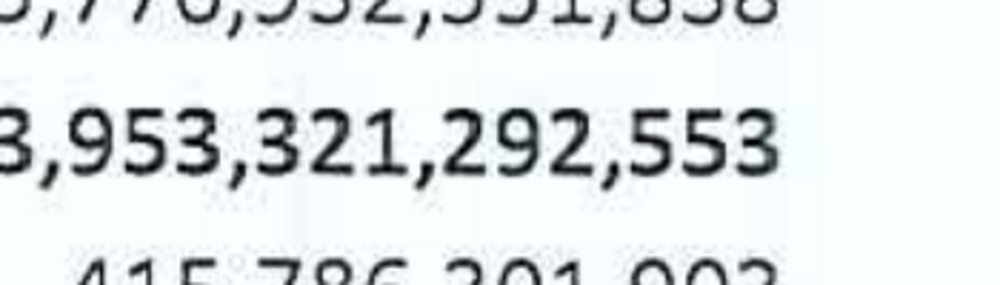


--- PSM 6 ---


,text,conf,left,top,width,height
4,"3,953,321,292,553",91.027275,0,37,272,30



--- PSM 7 ---


,text,conf,left,top,width,height



--- PSM 11 ---


,text,conf,left,top,width,height
4,bah,30.924850,239,0,33,9
5,ad,34.264641,265,0,11,18
9,Cae,9.310776,0,0,34,14
10,Cae,14.111343,62,0,145,14
11,eee,43.476707,111,0,36,18
12,Se,37.901875,159,0,9,18
13,ee,41.710770,175,0,35,18
17,"3,953,321,292,553",89.475525,0,37,272,30
21,ơn,0.000000,27,90,245,10



--- PSM 12 ---


,text,conf,left,top,width,height
4,-¬,24.830948,257,0,15,9
8,Cae,9.310776,0,0,34,14
9,ý,0.000000,45,0,9,18
10,km,0.000000,64,0,35,14
11,xử,0.774719,109,0,13,18
12,4œ,35.234619,127,0,13,18
13,Se,37.901875,159,0,9,18
14,ee,41.710770,175,0,32,9
18,"3,953,321,292,553",91.027275,0,37,272,30
22,ơn,0.000000,27,90,245,10



--- PSM 13 ---


,text,conf,left,top,width,height
4,958821292553.0,25.707512,0,0,350,100


In [108]:
from PIL import Image
from IPython.display import display
import pytesseract
from pytesseract import Output

# Crop the fourth financial column around Gross Profit
# Coordinates based on the current 3509 x 2481 image

crop = image.crop((
    3050,   # left
    970,    # top
    3400,   # right
    1070    # bottom
))

print("Crop dimensions:", crop.size)
display(crop.resize((1050, 300)))

# Test different OCR page segmentation modes
for psm in [6, 7, 11, 12, 13]:

    config = f"--oem 3 --psm {psm}"

    result = pytesseract.image_to_data(
        crop,
        lang="vie+eng",
        config=config,
        output_type=Output.DATAFRAME
    )

    result = result.dropna(subset=["text"])
    result["text"] = result["text"].astype(str).str.strip()

    result = result.loc[result["text"] != ""]

    print(f"\n--- PSM {psm} ---")
    display(
        result[["text", "conf", "left", "top", "width", "height"]]
    )

In [109]:
# Re-OCR the missing cell using PSM 6

crop_left = 3050
crop_top = 970

crop_ocr = pytesseract.image_to_data(
    crop,
    lang="vie+eng",
    config="--oem 3 --psm 6",
    output_type=Output.DATAFRAME
)

crop_ocr = crop_ocr.dropna(subset=["text"]).copy()
crop_ocr["text"] = crop_ocr["text"].astype(str).str.strip()

# Keep numeric tokens only
crop_ocr = crop_ocr.loc[
    crop_ocr["text"].str.fullmatch(
        r"^\(?-?\d[\d,]*(?:\.\d+)?\)?$",
        na=False
    )
].copy()

# Convert crop coordinates back to original page coordinates
crop_ocr["left"] += crop_left
crop_ocr["top"] += crop_top

crop_ocr["right"] = (
    crop_ocr["left"] + crop_ocr["width"]
)

crop_ocr["y_center"] = (
    crop_ocr["top"] + crop_ocr["height"] / 2
)

# Assign column using previously estimated anchors
crop_ocr["column"] = crop_ocr["right"].apply(
    lambda x: int(np.argmin(np.abs(centers - x)))
)

# Display recovered token
display(
    crop_ocr[
        ["text", "conf", "left", "right", "y_center", "column"]
    ]
)

,text,conf,left,right,y_center,column
4,"3,953,321,292,553",91.027275,3050,3322,1022.0,3


In [110]:
# Add recovered OCR tokens to the existing token dataset

recovered_tokens = crop_ocr.copy()

# Retain only columns needed for reconstruction
recovered_tokens = recovered_tokens[
    [
        "text", "conf", "left", "top",
        "width", "height", "right",
        "y_center", "column"
    ]
]

# Add recovered tokens
data_tokens_updated = pd.concat(
    [
        data_tokens[
            [
                "text", "conf", "left", "top",
                "width", "height", "right",
                "y_center", "column"
            ]
        ],
        recovered_tokens
    ],
    ignore_index=True
)

# Reconstruct rows again
data_tokens_updated = data_tokens_updated.sort_values(
    "y_center"
).copy()

row_ids = []
current_row = 0
previous_y = None

for y in data_tokens_updated["y_center"]:

    if previous_y is None or abs(y - previous_y) > 15:
        current_row += 1

    row_ids.append(current_row)
    previous_y = y

data_tokens_updated["row_id"] = row_ids

# Reconstruct values
reconstructed_updated = (
    data_tokens_updated
    .sort_values("left")
    .groupby(["row_id", "column"])
    .agg(
        y_center=("y_center", "median"),
        reconstructed_value=("text", "".join),
        token_count=("text", "count")
    )
    .reset_index()
)

# Convert to wide format
reconstructed_wide_updated = (
    reconstructed_updated
    .pivot(
        index="row_id",
        columns="column",
        values="reconstructed_value"
    )
)

reconstructed_wide_updated.columns = [
    f"column_{c}" for c in reconstructed_wide_updated.columns
]

display(reconstructed_wide_updated)

,column_0,column_1,column_2,column_3
row_id,,,,
1,01202331,2023,NaN,NaN
2,2023,2022,2023,2022
3,"11,683,021,258,544","9,731,832,420,600","11,683,021,258,544","9,731,832,420,600"
4,"1,642,375,241","1,578,576,209","1,642,375,241","1,578,576,209"
5,"11,681,378,883,303","9,730,253,844,391","11,681,378,883,303","9,730,253,844,391"
6,"7,113,499,882,609","5,776,932,551,838","7,113,499,882,609","5,776,932,551,838"
7,"4,567,879,000,694","3,953,321,292,553","4,567,879,000,694","3,953,321,292,553"
8,"676,476,546,426","415,786,301,903","676,476,546,426","415,786,301,903"
9,"496,815,340,139","267,572,525,432","496,815,340,139","267,572,525,432"


In [111]:
import pandas as pd
import numpy as np
from pathlib import Path

# 1. Load Ground Truth
GROUND_TRUTH_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "fundamentals"
    / "FPT"
    / "FPT_IS_ground_truth_Q1_2023.csv"
)

ground_truth = pd.read_csv(GROUND_TRUTH_PATH)

# 2. Define the mapping between OCR rows and metrics
metric_mapping = {
    3: "gross_revenue",
    4: "deductions",
    5: "net_revenue",
    6: "cost_of_sales",
    7: "gross_profit",
    8: "financial_income",
    9: "financial_expenses",
    10: "interest_expense",
    11: "share_profit_associates",
    12: "selling_expenses",
    13: "admin_expenses",
    14: "operating_profit",
    15: "other_income",
    16: "other_expenses",
    17: "other_profit",
    18: "profit_before_tax",
    19: "current_tax",
    20: "deferred_tax",
    21: "net_income",
    22: "profit_attributable_owners",
    23: "non_controlling_interests",
    24: "basic_eps",
    25: "diluted_eps"
}

# 3. Extract OCR values from Quarter 2023
ocr_results = []

for row_id, metric in metric_mapping.items():

    raw_value = reconstructed_wide_updated.loc[
        row_id, "column_0"
    ]

    ocr_value = int(
        str(raw_value).replace(",", "").replace("(", "-").replace(")", "")
    )

    ocr_results.append({
        "metric": metric,
        "ocr_value": ocr_value
    })

ocr_evaluation = pd.DataFrame(ocr_results)

# 4. Merge with Ground Truth
evaluation = ground_truth[
    ["metric", "value"]
].merge(
    ocr_evaluation,
    on="metric",
    how="inner"
)

evaluation["absolute_error"] = (
    evaluation["ocr_value"] - evaluation["value"]
).abs()

evaluation["exact_match"] = (
    evaluation["ocr_value"] == evaluation["value"]
)

evaluation["relative_error"] = np.where(
    evaluation["value"] != 0,
    evaluation["absolute_error"] / evaluation["value"].abs(),
    np.nan
)

# 5. Summary
print("Metrics evaluated:", len(evaluation))
print("Exact matches:", evaluation["exact_match"].sum())
print(
    "Exact match rate:",
    f"{evaluation['exact_match'].mean() * 100:.2f}%"
)

print(
    "Mean relative error:",
    f"{evaluation['relative_error'].mean() * 100:.6f}%"
)

display(evaluation)

Metrics evaluated: 23
Exact matches: 23
Exact match rate: 100.00%
Mean relative error: 0.000000%


,metric,value,ocr_value,absolute_error,exact_match,relative_error
0,gross_revenue,11683021258544,11683021258544,0,True,0.0
1,deductions,1642375241,1642375241,0,True,0.0
2,net_revenue,11681378883303,11681378883303,0,True,0.0
3,cost_of_sales,7113499882609,7113499882609,0,True,0.0
4,gross_profit,4567879000694,4567879000694,0,True,0.0
5,financial_income,676476546426,676476546426,0,True,0.0
6,financial_expenses,496815340139,496815340139,0,True,0.0
7,interest_expense,147985668274,147985668274,0,True,0.0
8,share_profit_associates,43757073944,43757073944,0,True,0.0
9,selling_expenses,1101871534159,1101871534159,0,True,0.0


Adding the py file "landscape_income_statement_ocr.py" to automately run the pipeline to extract figures from all financial statements of FPT corp from Q12026 to Q42025

In [112]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.landscape_income_statement_ocr import (
    LandscapeIncomeStatementOCR,
    LandscapeOCRConfig,
    save_result
)

print("Module imported successfully!")

Module imported successfully!


In [113]:
config = LandscapeOCRConfig(
    language="vie+eng",
    primary_psm=12,
    retry_psm=6,
    n_numeric_columns=4
)

landscape_ocr = LandscapeIncomeStatementOCR(
    config=config,
    tesseract_cmd=r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

In [114]:
image_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "fundamentals"
    / "FPT"
    / "normalized_pages"
    / "FPT_2023_Q1_page_08.png"
)

result = landscape_ocr.extract(
    image_path,
    retry_missing=True
)

display(result.column_anchors)
display(result.reconstructed_wide)
display(result.missing_cells)
display(result.retry_log)

,column,right_anchor,min_right,max_right,token_count
0,0,2030.5,1568,2058,32
1,1,2463.0,2260,2469,28
2,2,2894.0,2704,2900,25
3,3,3325.0,3158,3331,24


,column_0,column_1,column_2,column_3
row_id,,,,
0,01202331,2023,NaN,NaN
1,2023,2022,2023,2022
2,"11,683,021,258,544","9,731,832,420,600","11,683,021,258,544","9,731,832,420,600"
3,"1,642,375,241","1,578,576,209","1,642,375,241","1,578,576,209"
4,"2511,681,378,883,303","9,730,253,844,391","11,681,378,883,303","9,730,253,844,391"
5,"267,113,499,882,609","5,776,932,551,838","7,113,499,882,609","5,776,932,551,838"
6,"4,567,879,000,694","3,953,321,292,553","4,567,879,000,694","321,292,553"
7,"27676,476,546,426","415,786,301,903","676,476,546,426","415,786,301,903"
8,"28496,815,340,139","267,572,525,432","496,815,340,139","267,572,525,432"


,row_id,column,y_center


,row_id,column,crop_box,result,confidence,status
0,6,3,"(3138, 960, 3321, 1080)","321,292,553",95.76532,recovered


In [115]:
save_result(
    result,
    PROJECT_ROOT
    / "results"
    / "tables"
    / "ocr"
    / "FPT_2023_Q1"
)

In [116]:
OCR_OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "tables"
    / "ocr"
    / "FPT_2023_Q1"
)

for file in sorted(OCR_OUTPUT_DIR.glob("*.csv")):
    df = pd.read_csv(file)

    print(
        f"{file.name:<45} "
        f"Rows: {len(df):>3} | "
        f"Columns: {len(df.columns):>2}"
    )

landscape_is_all_tokens.csv                   Rows: 293 | Columns: 15
landscape_is_column_anchors.csv               Rows:   4 | Columns:  5
landscape_is_missing_cells.csv                Rows:   0 | Columns:  3
landscape_is_numeric_tokens.csv               Rows: 109 | Columns: 17
landscape_is_reconstructed_long.csv           Rows:  98 | Columns:  8
landscape_is_reconstructed_wide.csv           Rows:  25 | Columns:  5
landscape_is_retry_log.csv                    Rows:   1 | Columns:  6


In [117]:
import pandas as pd

wide_path = (
    PROJECT_ROOT
    / "results"
    / "tables"
    / "ocr"
    / "FPT_2023_Q1"
    / "landscape_is_reconstructed_wide.csv"
)

reconstructed_wide = pd.read_csv(wide_path)

# Display all rows and columns
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 200,
    "display.max_colwidth", None
):
    display(reconstructed_wide)

,row_id,column_0,column_1,column_2,column_3
0,0,01202331,2023,NaN,NaN
1,1,2023,2022,2023,2022
2,2,"11,683,021,258,544","9,731,832,420,600","11,683,021,258,544","9,731,832,420,600"
3,3,"1,642,375,241","1,578,576,209","1,642,375,241","1,578,576,209"
4,4,"2511,681,378,883,303","9,730,253,844,391","11,681,378,883,303","9,730,253,844,391"
5,5,"267,113,499,882,609","5,776,932,551,838","7,113,499,882,609","5,776,932,551,838"
6,6,"4,567,879,000,694","3,953,321,292,553","4,567,879,000,694","321,292,553"
7,7,"27676,476,546,426","415,786,301,903","676,476,546,426","415,786,301,903"
8,8,"28496,815,340,139","267,572,525,432","496,815,340,139","267,572,525,432"
9,9,"147,985,668,274","145,819,741,163","147,985,668,274","145,819,741,163"


In [118]:
import pandas as pd

OCR_OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "tables"
    / "ocr"
    / "FPT_2023_Q1"
)

numeric_tokens = pd.read_csv(
    OCR_OUTPUT_DIR / "landscape_is_numeric_tokens.csv"
)

print("Available columns:")
print(numeric_tokens.columns.tolist())

display(numeric_tokens.head(15))

Available columns:
['level', 'page_num', 'block_num', 'par_num', 'line_num', 'word_num', 'left', 'top', 'width', 'height', 'conf', 'text', 'right', 'x_center', 'y_center', 'column', 'row_id']


,level,page_num,block_num,par_num,line_num,word_num,left,top,width,height,conf,text,right,x_center,y_center,column,row_id
0,5,1,7,1,1,5,1710,453,36,25,89.828575,01,1746,1728.0,465.5,0,0
1,5,1,7,1,1,7,1892,453,75,26,96.223221,2023,1967,1929.5,466.0,0,0
2,5,1,7,1,1,9,2021,453,37,26,93.303413,31,2058,2039.5,466.0,0,0
3,5,1,7,1,1,11,2182,454,78,26,96.960571,2023,2260,2221.0,467.0,1,0
4,5,1,15,1,1,1,1793,736,71,25,96.991882,2023,1864,1828.5,748.5,0,1
5,5,1,16,1,1,1,2225,738,71,24,96.771255,2022,2296,2260.5,750.0,1,1
6,5,1,17,1,1,1,2656,739,72,25,96.714890,2023,2728,2692.0,751.5,2,1
7,5,1,18,1,1,1,3087,740,71,25,96.696075,2022,3158,3122.5,752.5,3,1
8,5,1,21,1,1,1,1733,790,296,30,91.508560,"11,683,021,258,544",2029,1881.0,805.0,0,2
9,5,1,22,1,1,1,2182,791,277,31,91.866844,"9,731,832,420,600",2459,2320.5,806.5,1,2


In [119]:
# Inspect all OCR tokens belonging to the problematic rows
problematic_rows = [4, 5, 6, 7, 8, 23]

display(
    numeric_tokens[
        numeric_tokens["row_id"].isin(problematic_rows)
    ].sort_values(["row_id"])
)

,level,page_num,block_num,par_num,line_num,word_num,left,top,width,height,conf,text,right,x_center,y_center,column,row_id
16,5,1,33,1,1,1,1534,897,34,24,96.039108,25,1568,1551.0,909.0,0,4
17,5,1,34,1,1,1,1734,897,295,30,87.938972,"11,681,378,883,303",2029,1881.5,912.0,0,4
18,5,1,35,1,1,1,2183,898,277,31,92.512421,"9,730,253,844,391",2460,2321.5,913.5,1,4
19,5,1,36,1,1,1,2598,900,293,30,88.553680,"11,681,378,883,303",2891,2744.5,915.0,2,4
20,5,1,37,1,1,1,3046,901,276,30,90.811958,"9,730,253,844,391",3322,3184.0,916.0,3,4
21,5,1,40,1,1,1,1534,949,34,25,96.788963,26,1568,1551.0,961.5,0,5
22,5,1,41,1,1,1,1752,950,277,30,91.807175,"7,113,499,882,609",2029,1890.5,965.0,0,5
23,5,1,42,1,1,1,2184,951,276,31,92.295387,"5,776,932,551,838",2460,2322.0,966.5,1,5
24,5,1,43,1,1,1,2616,952,275,30,92.152321,"7,113,499,882,609",2891,2753.5,967.0,2,5
25,5,1,44,1,1,1,3047,954,275,30,89.262802,"5,776,932,551,838",3322,3184.5,969.0,3,5


In [122]:
import sys

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Module directory:", SRC_DIR)
print("Module path added:", str(SRC_DIR) in sys.path)

Module directory: d:\DS Project\Vietnam_Equity_Factor_Research\src
Module path added: True


In [123]:
from importlib import reload
import landscape_income_statement_ocr

reload(landscape_income_statement_ocr)

from landscape_income_statement_ocr import (
    LandscapeOCRConfig,
    LandscapeIncomeStatementOCR,
    save_result
)

In [125]:
from pathlib import Path

image_files = list(
    (PROJECT_ROOT / "data").rglob("*")
)

image_files = [
    p for p in image_files
    if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tiff"]
]

for p in image_files:
    print(p)

d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_2023_Q1_contact_sheet.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_Q1_2025_balance_sheet_page_4.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_Q1_2025_balance_sheet_page_5.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_Q1_2025_balance_sheet_page_6.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_Q1_2025_balance_sheet_page_7.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_Q1_2025_cash_flow_page_10.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\FPT_Q1_2025_cash_flow_page_11.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\normalized_pages\FPT_2023_Q1_landscape_contact_sheet.png
d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\norm

In [126]:
LANDSCAPE_IMAGE_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "fundamentals"
    / "FPT"
    / "normalized_pages"
    / "FPT_2023_Q1_page_08.png"
)

print("Image exists:", LANDSCAPE_IMAGE_PATH.exists())
print("Image path:", LANDSCAPE_IMAGE_PATH)

Image exists: True
Image path: d:\DS Project\Vietnam_Equity_Factor_Research\data\processed\fundamentals\FPT\normalized_pages\FPT_2023_Q1_page_08.png


In [127]:
result = ocr_engine.extract(
    image=LANDSCAPE_IMAGE_PATH,
    retry_missing=True
)

In [128]:
NEW_OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "tables"
    / "ocr"
    / "FPT_2023_Q1_v2"
)

save_result(result, NEW_OUTPUT_DIR)

In [129]:
display(result.reconstructed_wide)
display(result.missing_cells)
display(result.retry_log)

,column_0,column_1,column_2,column_3
row_id,,,,
0,"11,683,021,258,544","9,731,832,420,600","11,683,021,258,544","9,731,832,420,600"
1,"1,642,375,241","1,578,576,209","1,642,375,241","1,578,576,209"
2,"11,681,378,883,303","9,730,253,844,391","11,681,378,883,303","9,730,253,844,391"
3,"7,113,499,882,609","5,776,932,551,838","7,113,499,882,609","5,776,932,551,838"
4,"4,567,879,000,694","3,953,321,292,553","4,567,879,000,694","3,953,321,292,553"
5,"676,476,546,426","415,786,301,903","676,476,546,426","415,786,301,903"
6,"496,815,340,139","267,572,525,432","496,815,340,139","267,572,525,432"
7,"147,985,668,274","145,819,741,163","147,985,668,274","145,819,741,163"
8,"43,757,073,944","208,830,242,201","43,757,073,944","208,830,242,201"


,row_id,column,y_center


,row_id,column,crop_box,result,confidence,status
0,4,3,"(2996, 960, 3328, 1080)","3,953,321,292,553",87.639664,recovered


In [131]:
def parse_vnd(value):
    if pd.isna(value):
        return None

    value = str(value).strip()

    negative = value.startswith("(") and value.endswith(")")

    value = (
        value
        .replace(",", "")
        .replace("(", "")
        .replace(")", "")
        .replace(" ", "")
    )

    number = int(value)

    return -number if negative else number

In [132]:
wide = result.reconstructed_wide.copy()

wide = wide.apply(
    lambda column: column.map(parse_vnd)
)

In [133]:
additional_checks = {
    "operating_profit_2023": (
        wide.loc[11, "column_0"],
        wide.loc[4, "column_0"]
        + wide.loc[5, "column_0"]
        - wide.loc[6, "column_0"]
        + wide.loc[8, "column_0"]
        - wide.loc[9, "column_0"]
        - wide.loc[10, "column_0"]
    ),

    "profit_attribution_2023": (
        wide.loc[18, "column_0"],
        wide.loc[19, "column_0"]
        + wide.loc[20, "column_0"]
    ),

    "revenue_reconciliation_2022": (
        wide.loc[2, "column_1"],
        wide.loc[0, "column_1"]
        - wide.loc[1, "column_1"]
    )
}

additional_results = []

for name, (actual, expected) in additional_checks.items():
    difference = actual - expected

    additional_results.append({
        "check": name,
        "actual": actual,
        "expected": expected,
        "difference": difference,
        "status": "PASS" if difference == 0 else "FAIL"
    })

additional_validation_df = pd.DataFrame(additional_results)

display(additional_validation_df)

,check,actual,expected,difference,status
0,operating_profit_2023,2096933282136,2096933282136,0,PASS
1,profit_attribution_2023,1809799453894,1809799453894,0,PASS
2,revenue_reconciliation_2022,9730253844391,9730253844391,0,PASS


In [134]:
validation_all = pd.concat(
    [validation_df, additional_validation_df],
    ignore_index=True
)

# Ensure exact integer comparison
validation_all["difference"] = (
    validation_all["actual"] - validation_all["expected"]
)

validation_all["status"] = validation_all["difference"].apply(
    lambda x: "PASS" if x == 0 else "FAIL"
)

display(validation_all)

validation_path = (
    NEW_OUTPUT_DIR / "accounting_validation.csv"
)

validation_all.to_csv(
    validation_path,
    index=False
)

print("Saved:", validation_path)
print(
    "Passed:",
    (validation_all["status"] == "PASS").sum(),
    "/",
    len(validation_all)
)

,check,actual,expected,difference,status
0,net_revenue_2023,1.168138e+13,1.168138e+13,0.0,PASS
1,gross_profit_2023,4.567879e+12,4.567879e+12,0.0,PASS
2,other_profit_2023,2.371036e+10,2.371036e+10,0.0,PASS
3,profit_before_tax_2023,2.120644e+12,2.120644e+12,0.0,PASS
4,net_income_2023,1.809799e+12,1.809799e+12,0.0,PASS
5,operating_profit_2023,2.096933e+12,2.096933e+12,0.0,PASS
6,profit_attribution_2023,1.809799e+12,1.809799e+12,0.0,PASS
7,revenue_reconciliation_2022,9.730254e+12,9.730254e+12,0.0,PASS


Saved: d:\DS Project\Vietnam_Equity_Factor_Research\results\tables\ocr\FPT_2023_Q1_v2\accounting_validation.csv
Passed: 8 / 8
